# FYP — IoMT Resource-Exhaustion Detector — PCAP-Native, Multiclass, Leakage-Safe Training Pipeline

**Project:** Adaptive Autonomous Cyber Defense for IoMT Networks
**Team:** Mohammad Haider Abbas (23i-2558), Hamd Ul Haq (23i-0081), Ayesha Ikram (23i-0109)
**Component:** Detection and Confidence Module (Revised Pipeline §4; Dataset Strategy §5, §12, §14–§18; Metrics Framework §3–§4)

## 1. Abstract, architecture and requirements tracing

This notebook replaces the CSV feature pipeline with **direct extraction from the raw CICIoMT2024 Wi-Fi/MQTT PCAP
captures**. It keeps the empirical rules of the CSV pipeline: an explicit label hierarchy, the official train/test capture
split, tail-block validation with a purge gap, transforms fitted on FIT only, and one final TEST pass. It also adds what
raw packets make possible: per-packet detection with a causal 20-packet context, sequence models (BiLSTM/GRU, Transformer),
hardware-aware model selection and a live PCAP inference engine.

**Prediction unit.** One prediction per packet. Each packet is described by its own header fields, statistics over
the **previous 20 packets of the same stream** (length/TTL statistics, flag and protocol ratios, packet and byte rate,
number of distinct sources, destinations and ports), and **victim-centric long-horizon features over the previous
`LONG_CONTEXT_N` = 1,024 packets** (how many distinct hosts are sending to this packet's destination, how many this
packet's source is sending to, the pair's share of that traffic and its rate). Only the past is used, so the same
features are available live. The sequence models see the 20-packet window as a sequence.

> **Revision: DoS vs DDoS.** The previous run separated the protocol (TEST subtype macro-F1 0.994) but not the attack
> scale (variant macro-F1 0.764; all top-10 confusions were DoS↔DDoS of the same protocol). §5b diagnoses why on the
> training captures: DoS and DDoS send the *same packets*; they differ only in *how many hosts attack one victim*, and
> attackers send in bursts longer than the 20-packet window, which also counted sources over the whole stream rather
> than per victim. The fix adds 8 attacker-cardinality features (`rt.LONG_FEATURES`) computed per endpoint over a
> 1,024-packet history, with matching eligibility, purge gap and live carry-over. §17 item 6 measures DoS↔DDoS swap
> rates before and after on the real VAL/TEST split, and every table reports a `dos_ddos_swap_rate`.

**Labels.** 13 variants → 7 subtypes → 4 families → binary, derived from the capture file name. One model is trained at
the variant level; coarser levels are obtained by multiplying the probabilities with fixed 0/1 collapse matrices.

```
 CICIoMT2024/**/*.pcap(ng)        §4 discovery · dual-chunk SHA-256 · filename → label hierarchy · train/test split
          │
          ▼  §5  header-only index → 1M packets/capture as 50 evenly spaced 20k-packet blocks (seek reads, dpkt decode)
 cache/<file>.<hash>.parquet     raw header fields (identifiers hashed; timestamp + packet_no kept only for ablation)
          │
          ▼  §5b DoS vs DDoS diagnosis on training captures (attackers, burst length, separability ladder)
          ▼  §6  causal features (packet + previous 20 + victim-centric previous 1,024) · roles FIT/gap/VAL/TEST · off-protocol packets dropped (logged)
 X_tab (74 features)  +  memory-mapped per-packet store → strided 20-packet windows for RNN / Transformer
          │
          ▼  §7–§9 FIT-only preprocessing · 13→7→4→2 collapse matrices · leakage checks
 §10–§13  Dummy · LogReg · Tree · RF · AdaBoost · XGBoost(CUDA) · LightGBM · BiLSTM/GRU · Transformer (resumable)
          │
          ▼  §14 composite score = 0.6·MacroF1 + 0.2·(1−latency/max) + 0.2·(1−RAM/max)  (manual override possible)
 §15 Platt calibration on VAL → §16 single TEST pass (4 levels) → §17 robustness → §18 bundle → §19 live PCAP engine
```

**Hardware envelope.** GPU ≤ 15.0 GB VRAM (T4 / A10G / RTX 3090), system RAM ≤ 12.7 GB (Colab free / edge gateway).
Captures are streamed in 20,000-packet blocks; all features are `float32`; labels are `int64`. RAM and VRAM are logged
at every heavy step, and a guard stops a step with a clear message before it would exceed the RAM ceiling.

### Design decisions confirmed for this build
| Decision | Setting | Where |
|---|---|---|
| Prediction unit | per packet + causal context of the previous 20 packets (`CONTEXT_N = 20`) | §3, §5–§6 |
| DoS vs DDoS signal | victim-centric attacker-count features over the previous 1,024 packets (`LONG_CONTEXT_N`); targets need the full history | §3, §5, §5b, §6 |
| Packets per capture | 1,000,000, as evenly spaced contiguous 20k-packet blocks | §3, §5 |
| Background packets in attack captures | dropped from training/evaluation and **counted per file** (`OFF_PROTOCOL_POLICY = "drop"`) | §6, §9 |
| Selection weights | 0.6 · Macro-F1 + 0.2 · latency + 0.2 · memory, with `MANUAL_SELECTION` override | §3, §14, §20 |

### Requirements traced to code
| Requirement | Where it is implemented |
|---|---|
| Discover all train/test PCAPs under `CICIoMT2024`, infer split from file name | §4 `parse_capture_name` |
| In-scope 13 variants only; Recon / ARP / Malformed / BLE excluded **and logged** | §4 label rules + exclusion table |
| Dual-chunk SHA-256 fingerprints (first/last 4 MB), duplicate-file detection | §4 `fast_fingerprint` |
| Streaming extraction in bounded 20k-packet batches; never OOM | §5 `extract_capture`, §2 `mem_guard` |
| Strip timestamp / packet_no / MAC / IP from model features | §5 assertion; identifiers only hashed for distinct counts |
| Length, TTL, TCP-flag, protocol-mix and rate features | §5 `iomt_runtime.build_features` |
| DoS vs DDoS: diagnose the collision, add attacker-cardinality features, measure before/after | §5b, §5 `long_horizon_features`, §17 item 6 |
| N-packet sequence windows without duplicating memory | §6 memory-mapped store + `sliding_window_view` |
| Transforms fitted on FIT only | §7 `ColumnTransformer`, §13 normalisation statistics |
| 13→7→4→2 collapse matrices | §8 |
| FIT 80 % / purge gap 1 % / VAL ~19 % per training capture; TEST = test captures only | §6 `assign_roles`, §9 assertions |
| Weighting `none` / `sqrt_balanced` / `balanced` tuned as a hyper-parameter | §10 |
| Dummy, LogReg (arcsinh), Decision Tree, RF, AdaBoost, XGBoost (CUDA hist), LightGBM | §10–§12 |
| BiLSTM/GRU and Transformer with DataLoader, AMP, AdamW, cosine LR, early stopping | §13 |
| Selection on F1 + latency + RAM/VRAM + disk (composite score) | §14 |
| Platt calibration on VAL only; reliability diagram; ECE | §15 |
| One TEST pass: Acc, Macro/Weighted-F1, worst-class recall, log-loss, Brier, ECE at 4 levels; 13×13 CM; PR curves | §16 |
| Permutation importance, shortcut ablation, leave-capture-out | §17 |
| Resumable caches, trials, checkpoints, bundle, best-model pointer with config hash | §5, §10, §13, §18 |
| `predict_pcap_stream` → SOC/Controller incident JSON (also a standalone CLI, `iomt_inference.py`) | §19 |

### How to run
1. Put the CICIoMT2024 PCAPs (train **and** test) under one Drive folder; set `DATA_DIR` in §3 if it differs.
2. *Runtime → Change runtime type → T4 GPU* (XGBoost and the PyTorch models use it; everything else runs on CPU).
3. *Run all*. If Colab disconnects, **run all again**: cached captures, finished trials, epoch checkpoints, finished
   models and benchmarks are reloaded instead of recomputed.
4. To pick a different model by hand after reading the §20 table, set `MANUAL_SELECTION` in §3 and re-run §14 → §20
   (nothing is retrained).

## 2. Environment setup, GPU detection and library audit
Installs whatever is missing (Colab already ships PyTorch, scikit-learn, XGBoost, LightGBM and pyarrow; `dpkt` and the
NVML bindings are added), records library versions, fixes all random seeds and defines the RAM/VRAM monitors used
throughout. `dpkt` is used instead of scapy: it decodes a packet roughly 20–50× faster, which matters for millions of
packets.

In [ ]:
import importlib.util, subprocess, sys
_REQUIRED = {"dpkt": "dpkt", "xgboost": "xgboost", "lightgbm": "lightgbm", "pyarrow": "pyarrow",
             "sklearn": "scikit-learn", "joblib": "joblib", "psutil": "psutil", "pynvml": "nvidia-ml-py"}
_missing = [pip for mod, pip in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import os, re, gc, json, glob, time, math, hashlib, platform, random, shutil, threading, inspect, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, psutil, sklearn, dpkt
import pyarrow as pa
import pyarrow.parquet as pq
import xgboost as xgb
try:
    import lightgbm as lgb
    HAS_LGBM = True
except Exception as e:
    lgb, HAS_LGBM = None, False
    print("LightGBM unavailable -> skipped:", e)
LGB_NEW_EVAL_API = HAS_LGBM and "eval_X" in inspect.signature(lgb.LGBMClassifier.fit).parameters
try:
    import torch
    HAS_TORCH = True
except Exception as e:
    torch, HAS_TORCH = None, False
    print("PyTorch unavailable -> sequence models skipped:", e)
try:
    import pynvml
    pynvml.nvmlInit()
    _NVML = pynvml.nvmlDeviceGetHandleByIndex(0)
except Exception:
    pynvml, _NVML = None, None

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix, roc_auc_score,
                             precision_recall_curve, average_precision_score)
try:
    from sklearn.frozen import FrozenEstimator          # scikit-learn >= 1.6
except ImportError:
    FrozenEstimator = None

warnings.filterwarnings("ignore", message=".*force_all_finite.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IP.off is deprecated.*")
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 80); pd.set_option("display.max_colwidth", 80)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__,
            "lightgbm": lgb.__version__ if HAS_LGBM else None, "torch": torch.__version__ if HAS_TORCH else None,
            "dpkt": dpkt.__version__, "pyarrow": pa.__version__, "joblib": joblib.__version__,
            "psutil": psutil.__version__}
print(json.dumps(VERSIONS, indent=2))

# ---------------- reproducibility ----------------
RANDOM_STATE = 42
def seed_everything(seed=RANDOM_STATE):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    if HAS_TORCH:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
seed_everything()

# ---------------- hardware ----------------
def _nvidia_smi_ok():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except (FileNotFoundError, OSError):
        return False
HAS_CUDA = bool(HAS_TORCH and torch.cuda.is_available())
GPU_PRESENT = HAS_CUDA or _nvidia_smi_ok()
XGB_DEVICE = "cuda" if GPU_PRESENT else "cpu"
TORCH_DEVICE = "cuda" if HAS_CUDA else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if HAS_CUDA else ("nvidia (no torch)" if GPU_PRESENT else "none")
N_JOBS = max(1, os.cpu_count() or 1)           # Colab free = 2 cores; never oversubscribe
HARDWARE = {"cpu": platform.processor() or platform.machine(), "cores": N_JOBS, "gpu": GPU_NAME,
            "ram_total_gb": round(psutil.virtual_memory().total / 1e9, 1),
            "vram_total_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if HAS_CUDA else 0}
print("Hardware:", HARDWARE, "| XGBoost:", XGB_DEVICE, "| PyTorch:", TORCH_DEVICE)

# ---------------- memory monitoring (RAM via psutil, VRAM via NVML / torch) ----------------
RAM_LIMIT_GB, VRAM_LIMIT_GB = 12.7, 15.0       # hardware ceilings from the specification
RAM_SAFETY_FRACTION = 0.85                     # stop a step before RSS would exceed 85 % of the ceiling

def ram_mb():
    return psutil.Process().memory_info().rss / 2**20

def vram_mb():
    if _NVML is not None:
        return pynvml.nvmlDeviceGetMemoryInfo(_NVML).used / 2**20
    return torch.cuda.memory_allocated() / 2**20 if HAS_CUDA else 0.0

def mem_status(tag=""):
    v = f" | VRAM {vram_mb():,.0f} MB" if GPU_PRESENT else ""
    head = f"[{tag}] " if tag else ""
    return f"{head}RAM {ram_mb():,.0f} MB (system avail {psutil.virtual_memory().available / 2**20:,.0f} MB){v}"

def free_memory():
    gc.collect()
    if HAS_CUDA:
        torch.cuda.empty_cache()

def mem_guard(stage, need_mb=0.0):
    """Free what can be freed, then refuse to start a step that would push RSS past the safety ceiling."""
    free_memory()
    ceiling = RAM_LIMIT_GB * 1024 * RAM_SAFETY_FRACTION
    room = min(psutil.virtual_memory().available / 2**20, ceiling - ram_mb())
    if need_mb > room:
        raise MemoryError(f"{stage}: needs ~{need_mb:,.0f} MB but only {room:,.0f} MB are safely available. "
                          "Lower the row budgets in §3 (FIT_ROWS_PER_CLASS / VAL_MAX_ROWS / TEST_MAX_ROWS) or restart "
                          "the runtime and re-run (all caches are reused).")
    return room

class PeakMemory:
    """Background sampler of peak process RSS and device VRAM while a block of code runs."""
    def __init__(self, interval=0.02):
        self.interval, self.peak_ram_mb, self.peak_vram_mb = interval, 0.0, 0.0
    def _run(self):
        while not self._stop.is_set():
            self.peak_ram_mb = max(self.peak_ram_mb, ram_mb())
            if GPU_PRESENT:
                self.peak_vram_mb = max(self.peak_vram_mb, vram_mb())
            self._stop.wait(self.interval)
    def __enter__(self):
        self.base_ram_mb, self.base_vram_mb = ram_mb(), (vram_mb() if GPU_PRESENT else 0.0)
        self._stop = threading.Event(); self._t = threading.Thread(target=self._run, daemon=True); self._t.start()
        return self
    def __exit__(self, *exc):
        self._stop.set(); self._t.join()
        self.peak_ram_mb = max(self.peak_ram_mb, ram_mb())

print(mem_status("start"))

# plot style: fixed categorical order, one-hue sequential maps, recessive grid
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#7a7a7a"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES_COLORS)})

{
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "torch": "2.14.1+cu130",
  "dpkt": "1.9.8",
  "pyarrow": "23.0.1",
  "joblib": "1.6.0",
  "psutil": "5.9.5"
}
Hardware: {'cpu': 'x86_64', 'cores': 2, 'gpu': 'Tesla T4', 'ram_total_gb': 13.6, 'vram_total_gb': 15.6} | XGBoost: cuda | PyTorch: cuda
[start] RAM 807 MB (system avail 10,978 MB) | VRAM 450 MB


## 3. Global configuration, paths and deterministic run hashes
Everything that changes results is set here. Result-affecting settings are hashed: `SETTINGS_HASH` here, and in §4 it is
combined with the data fingerprints into `CONFIG_HASH`, which names the run folder `runs/run_<CONFIG_HASH>/`. Changing a
setting therefore starts a new run instead of mixing checkpoints. **Selection-only settings** (`SCORE_WEIGHTS`,
`LATENCY_METRIC`, `MEMORY_METRIC`, `MANUAL_SELECTION`) are deliberately *not* hashed, so you can change your choice of
model without retraining anything.

* `LOCAL_DIR` is fast local disk (not Drive) for the memory-mapped sequence store. It is rebuilt from the Drive caches
  after a disconnect.
* `IOMT_SMOKE=1` (environment variable) shrinks everything for a quick end-to-end test.

In [ ]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount("/content/drive")

# =========================== PATHS ===========================
DATA_DIR   = os.environ.get("IOMT_DATA_DIR",   "/content/drive/MyDrive/CICIoMT2024")
OUTPUT_DIR = os.environ.get("IOMT_OUTPUT_DIR", "/content/drive/MyDrive/FYP_IoMT_Detector")
LOCAL_DIR  = os.environ.get("IOMT_LOCAL_DIR",  "/content/iomt_local" if IN_COLAB else os.path.join(OUTPUT_DIR, "local"))
# =============================================================
RECURSIVE_SEARCH = True
SMOKE_TEST = os.environ.get("IOMT_SMOKE", "0") == "1"

# ---- labels ----
TRAIN_LEVEL = "variant"                 # "variant" (13) | "subtype" (7) | "family" (4)
ALLOW_MISSING_CLASSES = False           # stop if a class lacks a train or test capture (never drop one silently)

# ---- PCAP extraction ----
PACKETS_PER_CAPTURE = 1_000_000         # packets extracted per capture (all packets if the capture is smaller)
BLOCK_PACKETS = 20_000                  # contiguous packets per block = streaming batch size
CONTEXT_N = 20                          # packet window: current packet + previous 19 (features and sequence models)
LONG_CONTEXT_N = 1_024                  # victim-centric history for the DoS-vs-DDoS (attacker-count) features, packets
OFF_PROTOCOL_POLICY = "drop"            # "drop" | "keep_label" | "relabel_benign" (packets not matching the attack)
FAST_FINGERPRINT_MB = 4

# ---- leakage-safe split inside every *training* capture (by packet index) ----
VAL_FRACTION = 0.20
GAP_FRACTION, GAP_MIN_ROWS, GAP_MAX_ROWS = 0.01, 50, 5_000      # the gap is also forced >= CONTEXT_N + 1

# ---- row budgets held in RAM (float32) ----
FIT_ROWS_PER_CLASS = 200_000            # FIT packets per class (uniform sample of the eligible FIT packets)
VAL_MAX_ROWS = 650_000                  # VAL / TEST: one uniform fraction for all classes (proportions preserved)
TEST_MAX_ROWS = 1_300_000
TUNE_ROWS_PER_CLASS = 40_000            # hyper-parameter search set (class-stratified draw of FIT)

# ---- models ----
MODELS_TO_RUN = ["logreg", "decision_tree", "random_forest", "adaboost", "xgboost", "lightgbm", "birnn", "transformer"]
N_ITER = {"logreg": 4, "decision_tree": 8, "random_forest": 6, "adaboost": 6, "xgboost": 10, "lightgbm": 10,
          "birnn": 3, "transformer": 3}
EARLY_STOPPING_ROUNDS, MAX_BOOST_ROUNDS = 30, 1_500
SEQ_BATCH = 1024
SEQ_TUNE_EPOCHS, SEQ_TUNE_SAMPLES_PER_EPOCH = 4, 150_000
SEQ_EPOCHS, SEQ_SAMPLES_PER_EPOCH, SEQ_PATIENCE = 12, 400_000, 3
USE_AMP = True                          # mixed precision on CUDA
CALIBRATION_METHOD = "sigmoid"          # Platt scaling, fitted on VAL only

# ---- multi-criteria selection (NOT hashed: changing these never retrains) ----
SCORE_WEIGHTS = {"macro_f1": 0.6, "latency": 0.2, "memory": 0.2}
LATENCY_METRIC = "batch1k_p95_ms"       # or "single_p95_ms" / "single_p50_ms" / "batch1k_p50_ms"
MEMORY_METRIC = "peak_ram_mb"           # model RAM while loading + predicting a 10k batch on CPU
MANUAL_SELECTION = None                 # e.g. "lightgbm" -> overrides the composite winner (see §20)
BENCH_REPEATS = 200
BENCH_ROWS = 10_000

# ---- robustness / demo ----
RUN_SHORTCUT_ABLATION, ABLATION_ROWS_PER_CLASS = True, 20_000
RUN_LEAVE_CAPTURE_OUT = True
RUN_DOS_DDOS_ABLATION = True            # §17 item 6: same model with / without the long-horizon features
RUN_DOS_DDOS_DIAGNOSIS = True           # §5b: diagnosis on the training captures (TEST is never read there)
DIAG_BLOCKS_PER_CAPTURE, DIAG_ROWS_PER_BLOCK = 6, 1_000
DIAG_WINDOWS = [20, 64, 256, 1_024, 4_096]   # history lengths compared in §5b
PERMUTATION_ROWS = 20_000
DEMO_PACKETS_PER_FILE = 5_000
SEVERITY_THRESHOLDS = {"high": 0.90, "medium": 0.60}        # on calibrated confidence of an Attack prediction

if SMOKE_TEST:
    PACKETS_PER_CAPTURE, BLOCK_PACKETS = 12_000, 2_000
    FIT_ROWS_PER_CLASS, VAL_MAX_ROWS, TEST_MAX_ROWS, TUNE_ROWS_PER_CLASS = 4_000, 12_000, 20_000, 1_500
    N_ITER = {k: (2 if k not in ("birnn", "transformer") else 1) for k in N_ITER}
    MAX_BOOST_ROUNDS, SEQ_TUNE_EPOCHS, SEQ_EPOCHS, SEQ_TUNE_SAMPLES_PER_EPOCH, SEQ_SAMPLES_PER_EPOCH = 80, 1, 2, 4_000, 8_000
    SEQ_BATCH, BENCH_REPEATS, BENCH_ROWS = 256, 30, 2_000
    ABLATION_ROWS_PER_CLASS, PERMUTATION_ROWS, DEMO_PACKETS_PER_FILE = 1_000, 2_000, 1_500
    LONG_CONTEXT_N, DIAG_BLOCKS_PER_CAPTURE, DIAG_ROWS_PER_BLOCK, DIAG_WINDOWS = 256, 2, 300, [20, 64, 256, 1_024]
    print("SMOKE TEST MODE - results are not meaningful")

assert OFF_PROTOCOL_POLICY in ("drop", "keep_label", "relabel_benign")
HISTORY_N = max(CONTEXT_N, LONG_CONTEXT_N)      # a target needs this many packets of history inside its block
assert HISTORY_N < BLOCK_PACKETS, "LONG_CONTEXT_N must be smaller than BLOCK_PACKETS"
FEATURE_VERSION = "v1.1-long-horizon"           # feature-set revision (hashed: a new feature set = a new run)
assert abs(sum(SCORE_WEIGHTS.values()) - 1.0) < 1e-9, "SCORE_WEIGHTS must sum to 1"
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"DATA_DIR does not exist: {DATA_DIR}\nOpen the Files pane, find the CICIoMT2024 folder, right-click -> "
        "Copy path, and paste it into DATA_DIR above.")
for d in (OUTPUT_DIR, LOCAL_DIR):
    os.makedirs(d, exist_ok=True)
CACHE_DIR = os.path.join(OUTPUT_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

SETTINGS = {"train_level": TRAIN_LEVEL, "packets_per_capture": PACKETS_PER_CAPTURE, "block_packets": BLOCK_PACKETS,
            "context_n": CONTEXT_N, "long_context_n": LONG_CONTEXT_N, "feature_version": FEATURE_VERSION,
            "off_protocol_policy": OFF_PROTOCOL_POLICY, "val_fraction": VAL_FRACTION,
            "gap": [GAP_FRACTION, GAP_MIN_ROWS, GAP_MAX_ROWS], "fit_rows_per_class": FIT_ROWS_PER_CLASS,
            "val_max_rows": VAL_MAX_ROWS, "test_max_rows": TEST_MAX_ROWS, "tune_rows_per_class": TUNE_ROWS_PER_CLASS,
            "max_boost_rounds": MAX_BOOST_ROUNDS, "early_stopping": EARLY_STOPPING_ROUNDS,
            "seq": [SEQ_BATCH, SEQ_TUNE_EPOCHS, SEQ_TUNE_SAMPLES_PER_EPOCH, SEQ_EPOCHS, SEQ_SAMPLES_PER_EPOCH,
                    SEQ_PATIENCE, USE_AMP], "seed": RANDOM_STATE, "smoke": SMOKE_TEST}
SETTINGS_HASH = hashlib.sha256(json.dumps(SETTINGS, sort_keys=True).encode()).hexdigest()[:10]
print("DATA_DIR  :", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("LOCAL_DIR :", LOCAL_DIR)
print("SETTINGS_HASH:", SETTINGS_HASH, "(combined with data fingerprints into CONFIG_HASH in §4)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR  : /content/drive/MyDrive/CICIoMT2024
OUTPUT_DIR: /content/drive/MyDrive/FYP_IoMT_Detector
LOCAL_DIR : /content/iomt_local
SETTINGS_HASH: 6173c20dcc (combined with data fingerprints into CONFIG_HASH in §4)


## 4. PCAP discovery, dual-chunk SHA-256 fingerprinting and label parsing
CICIoMT2024 PCAPs carry no label field: the class is defined by the **capture file name**. Each in-scope attack has one
explicit rule below, so nothing is merged by name similarity. DoS and DDoS stay separate (different number of
attackers). Train/test membership comes from the `_train` / `_test` suffix, with the parent folder name as a fallback.
Numbered files (`…ICMP1_train`, `…ICMP2_train`) are separate capture sessions of the same class. Out-of-scope captures
(Recon, ARP spoofing, malformed MQTT, BLE) are **listed with the reason**, never dropped silently.

**Fingerprint** = SHA-256 over (file size, first 4 MB, last 4 MB). Hashing a 1.5 GB file in full on Drive is slow; the
dual-chunk hash still changes if the file is replaced, and it is what keys every cache and the run hash.

In [ ]:
LABEL_RULES = [   # (filename regex, variant, subtype, family) - order fixes the class order everywhere
    (r"^benign",            "Benign",            "Benign",       "Benign"),
    (r"^tcp_ip-dos-syn",    "DoS-SYN",           "SYN",          "DoS"),
    (r"^tcp_ip-dos-tcp",    "DoS-TCP",           "TCP",          "DoS"),
    (r"^tcp_ip-dos-udp",    "DoS-UDP",           "UDP",          "DoS"),
    (r"^tcp_ip-dos-icmp",   "DoS-ICMP",          "ICMP",         "DoS"),
    (r"^tcp_ip-ddos-syn",   "DDoS-SYN",          "SYN",          "DDoS"),
    (r"^tcp_ip-ddos-tcp",   "DDoS-TCP",          "TCP",          "DDoS"),
    (r"^tcp_ip-ddos-udp",   "DDoS-UDP",          "UDP",          "DDoS"),
    (r"^tcp_ip-ddos-icmp",  "DDoS-ICMP",         "ICMP",         "DDoS"),
    (r"^mqtt-dos-connect",  "MQTT-DoS-Connect",  "MQTT-Connect", "MQTT-Flood"),
    (r"^mqtt-dos-publish",  "MQTT-DoS-Publish",  "MQTT-Publish", "MQTT-Flood"),
    (r"^mqtt-ddos-connect", "MQTT-DDoS-Connect", "MQTT-Connect", "MQTT-Flood"),
    (r"^mqtt-ddos-publish", "MQTT-DDoS-Publish", "MQTT-Publish", "MQTT-Flood"),
]
OUT_OF_SCOPE_RULES = [   # matched against the file name; BLE also against the folder path
    (r"recon|ping_sweep|port_scan|os_scan|vulnerability", "Recon - excluded (Dataset Strategy 5.2)"),
    (r"(^|[_-])arp",                                     "ARP spoofing - excluded (5.2)"),
    (r"malformed",                                       "MQTT malformed data - excluded (5.2)"),
    (r"bluetooth|(^|[_/-])ble([_/.-]|$)",                "BLE - optional extension, excluded (5.2)"),
]
CAPTURE_EXT = (".pcap", ".pcapng", ".cap")
HIERARCHY = pd.DataFrame([(v, s, f, "Benign" if v == "Benign" else "Attack") for _, v, s, f in LABEL_RULES],
                         columns=["variant", "subtype", "family", "binary"])
LEVELS = ["variant", "subtype", "family", "binary"]

def parse_capture_name(path):
    name, rel = os.path.basename(path), os.path.relpath(path, DATA_DIR)
    low, rel_low = name.lower(), rel.lower().replace(os.sep, "/")
    for pat, reason in OUT_OF_SCOPE_RULES:
        if re.search(pat, low) or ("ble" in reason.lower() and re.search(pat, rel_low)):
            return {"status": "excluded", "reason": reason}
    m = re.search(r"(train|test)(?=\.(pcapng|pcap|cap)$)", low)
    if m:
        split, capture = m.group(1), name[:m.start()].rstrip("_- ")
    else:
        parts = [p for p in rel_low.split("/")[:-1]]
        split = "train" if any(p in ("train", "training") for p in parts) else \
                "test" if any(p in ("test", "testing") for p in parts) else None
        capture = os.path.splitext(name)[0]
        if split is None:
            return {"status": "rejected", "reason": "cannot infer train/test split from file name or folder"}
    for pat, variant, _, _ in LABEL_RULES:
        if re.search(pat, low):
            return {"status": "ok", "reason": "", "variant": variant, "split": split, "capture": capture}
    return {"status": "rejected", "reason": "no label rule matched (not an in-scope CICIoMT2024 capture)"}

def fast_fingerprint(path, mb=FAST_FINGERPRINT_MB):
    """Dual-chunk SHA-256: size + first `mb` MB + last `mb` MB."""
    size = os.path.getsize(path)
    h = hashlib.sha256(str(size).encode())
    with open(path, "rb") as f:
        h.update(f.read(mb * 2**20))
        if size > mb * 2**20:
            f.seek(max(0, size - mb * 2**20)); h.update(f.read())
    return h.hexdigest()[:16]

_out_abs = [os.path.abspath(OUTPUT_DIR), os.path.abspath(LOCAL_DIR)]
all_caps = []
for root, dirs, files in os.walk(DATA_DIR):
    if any(os.path.abspath(root).startswith(o) for o in _out_abs):
        continue
    all_caps += [os.path.join(root, f) for f in files if f.lower().endswith(CAPTURE_EXT)]
    if not RECURSIVE_SEARCH:
        break
all_caps = sorted(all_caps)
print(f"Found {len(all_caps)} capture file(s) under {DATA_DIR}")

records, seen_fp = [], {}
for p in all_caps:
    rec = {"file": os.path.basename(p), "path": p, "size_mb": round(os.path.getsize(p) / 1e6, 2), **parse_capture_name(p)}
    if rec["status"] == "ok":
        rec["fingerprint"] = fast_fingerprint(p)
        if rec["fingerprint"] in seen_fp:
            rec.update(status="rejected", reason=f"duplicate copy of {seen_fp[rec['fingerprint']]}")
        else:
            seen_fp[rec["fingerprint"]] = rec["file"]
    records.append(rec)
MANIFEST = pd.DataFrame(records)
for col in ["variant", "split", "capture", "fingerprint"]:
    if col not in MANIFEST:
        MANIFEST[col] = None

print("\nFiles NOT used (and why):")
_unused = MANIFEST[MANIFEST.status != "ok"][["file", "status", "reason"]]
print(_unused.to_string(index=False) if len(_unused) else "  (none)")

FILES = MANIFEST[MANIFEST.status == "ok"].copy().reset_index(drop=True)
coverage = (FILES.groupby(["variant", "split"]).size().unstack(fill_value=0)
            .reindex(index=HIERARCHY.variant, columns=["train", "test"], fill_value=0))
print("\nCapture files per class:\n", coverage.to_string())
_missing_cls = coverage[(coverage["train"] == 0) | (coverage["test"] == 0)]
if len(_missing_cls):
    msg = ("These classes lack a train or test capture:\n" + _missing_cls.to_string() +
           "\nAdd the files, or set ALLOW_MISSING_CLASSES=True to continue knowingly (reported as missing).")
    if not ALLOW_MISSING_CLASSES:
        raise RuntimeError(msg)
    print("WARNING:", msg)
CLASS_NAMES_VARIANT = [v for v in HIERARCHY.variant if coverage.loc[v, "train"] > 0]

RUN_CONFIG = {**SETTINGS, "data": sorted(FILES.fingerprint)}
CONFIG_HASH = hashlib.sha256(json.dumps(RUN_CONFIG, sort_keys=True).encode()).hexdigest()[:10]
RUN_DIR = os.path.join(OUTPUT_DIR, "runs", f"run_{CONFIG_HASH}")
DIRS = {k: os.path.join(RUN_DIR, k) for k in ["models", "tuning", "reports", "figures", "bench"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
MANIFEST.drop(columns=["path"]).to_csv(os.path.join(DIRS["reports"], "file_manifest.csv"), index=False)
with open(os.path.join(RUN_DIR, "run_config.json"), "w") as f:
    json.dump({**RUN_CONFIG, "config_hash": CONFIG_HASH, "versions": VERSIONS, "hardware": HARDWARE,
               "created_utc": datetime.now(timezone.utc).isoformat()}, f, indent=2)
print(f"\nCONFIG_HASH {CONFIG_HASH}  ->  run folder: {RUN_DIR}")

def save_fig(fig, name):
    fig.savefig(os.path.join(DIRS["figures"], f"{name}.png"), bbox_inches="tight")
    plt.show()

def json_safe(o):
    if isinstance(o, dict):
        return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [json_safe(v) for v in o]
    if isinstance(o, pd.DataFrame):
        return json_safe(o.reset_index().to_dict("records"))
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    return o

Found 60 capture file(s) under /content/drive/MyDrive/CICIoMT2024

Files NOT used (and why):
  (none)

Capture files per class:
 split              train  test
variant                       
Benign                 1     1
DoS-SYN                4     1
DoS-TCP                4     1
DoS-UDP                4     1
DoS-ICMP               4     1
DDoS-SYN               4     1
DDoS-TCP               4     1
DDoS-UDP               8     2
DDoS-ICMP              8     2
MQTT-DoS-Connect       1     1
MQTT-DoS-Publish       1     1
MQTT-DDoS-Connect      1     1
MQTT-DDoS-Publish      1     1

CONFIG_HASH c53a51becb  ->  run folder: /content/drive/MyDrive/FYP_IoMT_Detector/runs/run_c53a51becb


## 5. Streaming PCAP feature extraction and shortcut removal
The extraction code lives in a small module, `iomt_runtime.py`, written by the next cell. Training (§6) and the live
engine (§19) import the **same** functions, so a packet is described identically in both. The module is also copied into
the deployment bundle.

**How a capture is read (bounded memory).**
1. *Header-only index.* One pass reads only the 16-byte record headers, counts packets and remembers the byte offset of
   every 20,000th packet. Payload bytes are skipped, so this is fast even for 1.5 GB files.
2. *Block plan.* If a capture has more than `PACKETS_PER_CAPTURE` packets, 50 contiguous 20,000-packet blocks are
   chosen, evenly spaced from the start to the end of the capture (early, middle and late traffic are all represented).
   Smaller captures are read completely.
3. *Block reads.* Each block is read by seeking to its offset and decoded with `dpkt` into raw header fields, then
   appended to a Parquet file, one block at a time. Peak memory is one block, whatever the capture size.
   (pcapng files cannot be seeked, so they are read sequentially and only the planned blocks are kept.)

**Raw fields kept per packet:** frame length, IP version, header length, TTL / hop limit, L4 protocol, DF/MF/fragment
bits, TCP flags / window / header length, L4 payload length, ICMP type/code, MQTT control-packet type (first payload byte
on port 1883/8883), a malformed flag, and **32-bit hashes** of source/destination addresses (the hashes are used only to
count *how many distinct* sources and destinations appear in a window, never as features).

**A note on TTL.** TTL is kept, as the feature list asks for TTL distributions. In CICIoMT2024, though, the attacking
Raspberry Pis and the benign internet hosts sit at different hop distances, so TTL can partly encode *where traffic comes
from in this lab* rather than *what it does*. Check its permutation importance in §17 before relying on it in a
different network.

**Long-horizon, victim-centric features (DoS vs DDoS).** `long_horizon_features` adds 8 columns computed over the
previous `LONG_CONTEXT_N` packets: distinct sources in the window (`lh_n_src`), distinct sources sending to *this
packet's destination* (`lh_fanin_dst`), distinct destinations of *this packet's source* (`lh_fanout_src`), their maximum
(`lh_peer_max`, the attacker count whatever the packet direction, so the victim's replies count too), the smaller of
the pair's share of the destination's inbound and of the source's outbound traffic (`lh_pair_share_min`: about 1 with
one attacker, about 1/k with k), the destination's share of the window, and log rates into the destination and of the
pair. They are exact and vectorised (`window_group_stats`: a difference array over each endpoint's packets, no Python
loop, about 40 ms per 20k-packet block) and were checked against a brute-force loop. Addresses enter only as anonymous
32-bit hashes used for *counting*; no address is a feature, so the model learns "how many hosts hit this victim", not
"which hosts".

**Shortcut removal.** `timestamp` (epoch) and `packet_no` stay in the cache only because the split (§6) and the
shortcut ablation (§17) need them. MAC/IP addresses never reach the cache in readable form, and raw ports are reduced
to "MQTT port" / "well-known port" flags plus distinct counts. An assertion after the next cell checks that no identifier
or shortcut column is a model feature.

Every capture is cached as `cache/<file>.<fingerprint>-<extract-hash>.parquet` (+ `.json` stats), written atomically,
so an interrupted extraction never leaves a half-written cache and a re-run skips finished captures.

In [ ]:
%%writefile iomt_runtime.py
"""IoMT PCAP runtime — shared by training and deployment.

* PcapSource      : classic-pcap / pcapng reader with a fast header-only index and block (seek) reads
* decode_records  : packet bytes -> raw header fields (no feature engineering, identifiers only hashed)
* build_features  : causal per-packet features + context over the previous N packets (same math in training & live)
* StreamFeaturizer: carries the last N raw packets across batches for live streams
* ProbaPassthrough: lets a post-hoc calibrator work on any model's probabilities (tabular or sequence)
"""
import os
import socket
import struct
import zlib

import dpkt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin

RUNTIME_VERSION = "1.1.0"           # 1.1: victim-centric long-horizon (attacker-cardinality) features
PARSE_VERSION = "raw-v1"            # bump when decode_records changes -> invalidates parquet caches
MQTT_PORTS = (1883, 8883)
DEFAULT_LONG_CONTEXT_N = 1024       # history (packets) for the long-horizon features; the bundle stores its own value

# ----------------------------------------------------------------------------------------------------------------
# raw fields produced by the decoder (one row per packet)
# ----------------------------------------------------------------------------------------------------------------
RAW_SPEC = [  # name, dtype, value when absent
    ("ts", "float64", 0.0), ("frame_len", "int32", 0), ("ip_ver", "int8", 0), ("is_arp", "int8", 0),
    ("ip_hdr_len", "int16", 0), ("ttl", "int16", 0), ("l4", "int16", -1), ("ip_df", "int8", 0),
    ("ip_mf", "int8", 0), ("ip_frag", "int8", 0), ("sport", "int32", -1), ("dport", "int32", -1),
    ("tcp_flags", "int16", -1), ("tcp_win", "int32", 0), ("tcp_hdr_len", "int16", 0), ("payload_len", "int32", 0),
    ("icmp_type", "int16", -1), ("icmp_code", "int16", -1), ("mqtt_type", "int8", -1),
    ("src_h", "uint32", 0), ("dst_h", "uint32", 0), ("malformed", "int8", 0)]
RAW_COLUMNS = [n for n, _, _ in RAW_SPEC]
RAW_DTYPES = {n: d for n, d, _ in RAW_SPEC}
_ABSENT = tuple(v for _, _, v in RAW_SPEC)

LINKTYPE_ETHERNET, LINKTYPE_NULL, LINKTYPE_LOOP = 1, 0, 108
LINKTYPE_RAW = (101, 12, 14, 228, 229)
LINKTYPE_SLL, LINKTYPE_SLL2 = 113, 276

_PCAP_MAGIC = {0xA1B2C3D4: ("<", 1e-6), 0xD4C3B2A1: (">", 1e-6),
               0xA1B23C4D: ("<", 1e-9), 0x4D3CB2A1: (">", 1e-9)}
_PCAPNG_MAGIC = 0x0A0D0D0A
_CHUNK = 32 << 20
_IP_HAS_BITFIELDS = hasattr(dpkt.ip.IP, "df") and hasattr(dpkt.ip.IP, "offset")


class PcapSource:
    """Streaming reader. Classic pcap supports a header-only index + seek-based block reads; pcapng is sequential."""

    def __init__(self, path):
        self.path = path
        with open(path, "rb") as f:
            head = f.read(24)
        if len(head) < 4:
            raise ValueError("file too short to be a capture")
        magic = struct.unpack("<I", head[:4])[0]
        if magic in _PCAP_MAGIC:
            self.format = "pcap"
            self.endian, self.ts_scale = _PCAP_MAGIC[magic]
            if len(head) < 24:
                raise ValueError("truncated pcap global header")
            self.linktype = struct.unpack(self.endian + "I", head[20:24])[0] & 0x0FFFFFFF
            self._rec = struct.Struct(self.endian + "IIII")
        elif magic == _PCAPNG_MAGIC:
            self.format = "pcapng"
            self.linktype = None                         # read from the interface block
            with open(path, "rb") as f:
                r = dpkt.pcapng.Reader(f)
                self.linktype = r.datalink()
        else:
            raise ValueError(f"unknown capture magic 0x{magic:08x}")

    # ---------------------------------------------------------------- classic pcap
    _MAX_RECORD = 1 << 20          # a record longer than 1 MiB means a corrupt file

    def _walk(self, offset, f):
        """Yield (ts, orig_len, data) for consecutive records starting at byte `offset` (bounded memory)."""
        rec, scale = self._rec, self.ts_scale
        f.seek(offset)
        buf, bpos = f.read(_CHUNK), 0
        while True:
            if len(buf) - bpos < 16:
                more = f.read(_CHUNK)
                if not more:
                    return
                buf, bpos = buf[bpos:] + more, 0
                continue
            sec, frac, incl, orig = rec.unpack_from(buf, bpos)
            if incl > self._MAX_RECORD:
                raise ValueError(f"corrupt pcap record (incl_len={incl}) in {self.path}")
            end = bpos + 16 + incl
            if end > len(buf):
                more = f.read(max(_CHUNK, end - len(buf)))
                if not more:
                    return                                  # truncated final record -> ignored
                buf, bpos = buf[bpos:] + more, 0
                continue
            yield sec + frac * scale, orig, buf[bpos + 16:end]
            bpos = end

    def index(self, every):
        """Header-only pass: (n_packets, byte offsets of packets 0, every, 2*every, ...). pcapng -> (n, None)."""
        if self.format == "pcapng":
            return sum(1 for _ in self.iter_all()), None
        rec, size = self._rec, os.path.getsize(self.path)
        offsets, n = [], 0
        with open(self.path, "rb") as f:
            f.seek(24)
            buf, bpos, fpos = f.read(_CHUNK), 0, 24        # fpos = file offset of buf[0]
            while True:
                if bpos > len(buf):                         # next header lies beyond the buffer: seek forward
                    f.seek(bpos - len(buf), 1)
                    fpos, buf, bpos = fpos + bpos, f.read(_CHUNK), 0
                if len(buf) - bpos < 16:
                    more = f.read(_CHUNK)
                    if not more:
                        break
                    fpos, buf, bpos = fpos + bpos, buf[bpos:] + more, 0
                    continue
                incl = rec.unpack_from(buf, bpos)[2]
                pos = fpos + bpos
                if incl > self._MAX_RECORD or pos + 16 + incl > size:
                    break                                   # corrupt or truncated tail
                if n % every == 0:
                    offsets.append(pos)
                n += 1
                bpos += 16 + incl
        return n, np.asarray(offsets, dtype=np.int64)

    def read_blocks(self, plan):
        """plan: sorted list of (block_id, start_index, n_packets, byte_offset or None).
        Yields (block_id, start_index, [(ts, orig_len, data), ...]). Classic pcap seeks; pcapng reads once."""
        if self.format == "pcap":
            with open(self.path, "rb") as f:
                for bid, s, n, off in plan:
                    recs = []
                    for r in self._walk(int(off), f):
                        recs.append(r)
                        if len(recs) >= n:
                            break
                    yield bid, s, recs
            return
        it = iter(plan)
        cur = next(it, None)
        recs = []
        for i, r in enumerate(self.iter_all()):
            if cur is None:
                break
            bid, s, n, _ = cur
            if i >= s:
                recs.append(r)
                if len(recs) >= n:
                    yield bid, s, recs
                    recs, cur = [], next(it, None)
        if cur is not None and recs:
            yield cur[0], cur[1], recs

    def iter_all(self):
        """Sequential (ts, orig_len, data) over the whole capture."""
        if self.format == "pcap":
            with open(self.path, "rb") as f:
                yield from self._walk(24, f)
        else:
            with open(self.path, "rb") as f:
                for ts, data in dpkt.pcapng.Reader(f):
                    yield ts, len(data), data


# ----------------------------------------------------------------------------------------------------------------
# packet decoding
# ----------------------------------------------------------------------------------------------------------------
def _ip4_int(b):
    return struct.unpack("!I", b)[0] if len(b) == 4 else zlib.crc32(b)


def _decode_one(ts, orig_len, data, linktype):
    ip_ver = is_arp = ip_hdr = ttl = df = mf = frag = 0
    l4, sport, dport, flags, win, thl, plen = -1, -1, -1, -1, 0, 0, 0
    itype = icode = mqtt = -1
    src_h = dst_h = 0
    try:
        if linktype == LINKTYPE_ETHERNET:
            l2 = dpkt.ethernet.Ethernet(data)
            net = l2.data
            src_h, dst_h = zlib.crc32(l2.src), zlib.crc32(l2.dst)
        elif linktype in LINKTYPE_RAW:
            v = data[0] >> 4 if data else 0
            net = dpkt.ip.IP(data) if v == 4 else dpkt.ip6.IP6(data) if v == 6 else None
        elif linktype == LINKTYPE_SLL:
            net = dpkt.sll.SLL(data).data
        elif linktype == LINKTYPE_SLL2 and hasattr(dpkt, "sll2"):
            net = dpkt.sll2.SLL2(data).data
        elif linktype in (LINKTYPE_NULL, LINKTYPE_LOOP):
            net = dpkt.loopback.Loopback(data).data
        else:
            return (ts, orig_len, 0, 0, 0, 0, -1, 0, 0, 0, -1, -1, -1, 0, 0, 0, -1, -1, -1, 0, 0, 1)
        if isinstance(net, dpkt.ip.IP):
            ip_ver, ip_hdr, ttl = 4, net.hl * 4, net.ttl
            if _IP_HAS_BITFIELDS:
                df, mf, frag = int(net.df), int(net.mf), int(net.offset != 0)
            else:                                        # dpkt < 1.9.5
                df, mf = int(bool(net.off & dpkt.ip.IP_DF)), int(bool(net.off & dpkt.ip.IP_MF))
                frag = int((net.off & dpkt.ip.IP_OFFMASK) != 0)
            src_h, dst_h, l4, seg = _ip4_int(net.src), _ip4_int(net.dst), net.p, net.data
        elif isinstance(net, dpkt.ip6.IP6):
            ip_ver, ip_hdr, ttl = 6, 40, net.hlim
            src_h, dst_h, l4, seg = zlib.crc32(net.src), zlib.crc32(net.dst), net.nxt, net.data
        elif isinstance(net, dpkt.arp.ARP):
            is_arp = 1
            src_h, dst_h = _ip4_int(net.spa), _ip4_int(net.tpa)
            seg = None
        else:
            seg = None
        if ip_ver and frag == 0:
            if isinstance(seg, dpkt.tcp.TCP):
                sport, dport, flags, win, thl = seg.sport, seg.dport, seg.flags, seg.win, seg.off * 4
                plen = len(seg.data)
                if plen and (sport in MQTT_PORTS or dport in MQTT_PORTS):
                    mqtt = seg.data[0] >> 4
            elif isinstance(seg, dpkt.udp.UDP):
                sport, dport, plen = seg.sport, seg.dport, len(seg.data)
            elif isinstance(seg, (dpkt.icmp.ICMP, dpkt.icmp6.ICMP6)):
                itype, icode = seg.type, seg.code
                plen = max(0, len(bytes(seg)) - 4)
            elif isinstance(seg, (bytes, bytearray)):
                plen = len(seg)
        return (ts, orig_len, ip_ver, is_arp, ip_hdr, ttl, l4, df, mf, frag, sport, dport, flags, win, thl, plen,
                itype, icode, mqtt, src_h, dst_h, 0)
    except Exception:          # malformed / truncated packet: keep timing + length, flag it
        return (ts, orig_len, ip_ver, is_arp, ip_hdr, ttl, l4, df, mf, frag, sport, dport, flags, win, thl, plen,
                itype, icode, mqtt, src_h, dst_h, 1)


def decode_records(records, linktype):
    """records: iterable of (ts, orig_len, data) -> DataFrame[RAW_COLUMNS] with compact dtypes."""
    rows = [_decode_one(ts, ol, d, linktype) for ts, ol, d in records]
    if not rows:
        return pd.DataFrame({c: np.array([], dtype=RAW_DTYPES[c]) for c in RAW_COLUMNS})
    arr = np.array(rows, dtype=np.float64)
    return pd.DataFrame({c: arr[:, j].astype(RAW_DTYPES[c]) for j, c in enumerate(RAW_COLUMNS)})


def packet_addresses(data, linktype):
    """Human-readable (src, dst) for incident reports only - never used as features."""
    try:
        if linktype == LINKTYPE_ETHERNET:
            l2 = dpkt.ethernet.Ethernet(data)
            net = l2.data
            fallback = (":".join(f"{b:02x}" for b in l2.src), ":".join(f"{b:02x}" for b in l2.dst))
        elif linktype in LINKTYPE_RAW:
            v = data[0] >> 4 if data else 0
            net, fallback = (dpkt.ip.IP(data) if v == 4 else dpkt.ip6.IP6(data)), (None, None)
        elif linktype == LINKTYPE_SLL:
            net, fallback = dpkt.sll.SLL(data).data, (None, None)
        else:
            return None, None
        if isinstance(net, dpkt.ip.IP):
            return socket.inet_ntoa(net.src), socket.inet_ntoa(net.dst)
        if isinstance(net, dpkt.ip6.IP6):
            return socket.inet_ntop(socket.AF_INET6, net.src), socket.inet_ntop(socket.AF_INET6, net.dst)
        if isinstance(net, dpkt.arp.ARP):
            return socket.inet_ntoa(net.spa), socket.inet_ntoa(net.tpa)
        return fallback
    except Exception:
        return None, None


# ----------------------------------------------------------------------------------------------------------------
# features — causal: a packet only sees itself and the packets before it in the same segment
# ----------------------------------------------------------------------------------------------------------------
BASE_FEATURES = [
    "frame_len", "ip_hdr_len", "payload_len", "ttl", "is_ipv4", "is_ipv6", "is_arp", "is_tcp", "is_udp", "is_icmp",
    "is_other_l4", "ip_df", "ip_mf", "ip_frag", "tcp_fin", "tcp_syn", "tcp_rst", "tcp_psh", "tcp_ack", "tcp_urg",
    "tcp_ece", "tcp_cwr", "tcp_win", "tcp_hdr_len", "icmp_type", "icmp_code", "sport_mqtt", "dport_mqtt",
    "sport_wellknown", "dport_wellknown", "mqtt_connect", "mqtt_publish", "mqtt_other", "log_iat_prev",
    "same_src_prev", "same_dst_prev", "same_sport_prev", "same_dport_prev", "malformed"]
CONTEXT_FEATURES = [
    "ctx_len_mean", "ctx_len_std", "ctx_len_min", "ctx_len_max", "ctx_len_sum", "ctx_payload_mean",
    "ctx_ttl_mean", "ctx_ttl_std", "ctx_log_iat_mean", "ctx_iat_cv", "ctx_log_pkt_rate", "ctx_log_byte_rate",
    "ctx_syn_ratio", "ctx_ack_ratio", "ctx_fin_ratio", "ctx_rst_ratio", "ctx_psh_ratio",
    "ctx_tcp_ratio", "ctx_udp_ratio", "ctx_icmp_ratio", "ctx_other_ratio",
    "ctx_mqtt_connect_ratio", "ctx_mqtt_publish_ratio",
    "ctx_n_src", "ctx_n_dst", "ctx_n_sport", "ctx_n_dport"]
# Long-horizon, victim-centric features over the previous n_long packets of the stream (see long_horizon_features).
# DoS and DDoS of one protocol send the same packets; they differ in HOW MANY hosts attack the same victim. That is
# only visible over a horizon longer than an attacker's burst, and only when sources are counted per endpoint.
LONG_FEATURES = [
    "lh_n_src",             # distinct sources in the whole window
    "lh_fanin_dst",         # distinct sources that sent to this packet's destination
    "lh_fanout_src",        # distinct destinations this packet's source sent to
    "lh_peer_max",          # max(fan-in of dst, fan-out of src): attacker count, whatever the packet direction
    "lh_pair_share_min",    # min(pair / dst-inbound, pair / src-outbound): ~1 for one attacker, ~1/k for k attackers
    "lh_dst_share",         # share of the window that goes to this destination (victim concentration)
    "lh_log_dst_rate",      # log10 packets/s into this destination over the window
    "lh_log_pair_rate"]     # log10 packets/s of this (source, destination) pair over the window
TAB_FEATURES = BASE_FEATURES + CONTEXT_FEATURES + LONG_FEATURES
SEQ_FEATURES = BASE_FEATURES + LONG_FEATURES
SHORTCUT_COLUMNS = ["timestamp", "packet_no"]      # never model features; used only by the shortcut ablation
_FLAG_BITS = [("tcp_fin", 0x01), ("tcp_syn", 0x02), ("tcp_rst", 0x04), ("tcp_psh", 0x08), ("tcp_ack", 0x10),
              ("tcp_urg", 0x20), ("tcp_ece", 0x40), ("tcp_cwr", 0x80)]


def _prev_equal(a):
    out = np.zeros(len(a), np.float32)
    if len(a) > 1:
        out[1:] = (a[1:] == a[:-1])
    return out


def _window_sum(x, start):
    cs = np.concatenate([[0.0], np.cumsum(x, dtype=np.float64)])
    i = np.arange(len(x))
    return cs[i + 1] - cs[start]


def _group_codes(a, b=None):
    """Dense int64 code per row for the key a (or the pair (a, b)); a, b are 32-bit hashes."""
    k = np.asarray(a).astype(np.uint64)
    if b is not None:
        k = (k << np.uint64(32)) | np.asarray(b).astype(np.uint64)
    return np.unique(k, return_inverse=True)[1].astype(np.int64).ravel()


def window_group_stats(group, value, H):
    """Exact sliding-window statistics, causal, O(n log n), no Python loop.

    For every row i, over the rows j in the window (i-H, i] that share i's group (group[j] == group[i]):
      count[i]    = number of such rows
      distinct[i] = number of distinct value[j] among them      (skipped when value is None)

    Distinct count uses the 'first occurrence inside the window' identity: a row j is the first of its
    (group, value) inside the window ending at i  <=>  its previous same-(group, value) row prev(j) lies outside,
    i.e.  max(j, prev(j) + H) <= i <= j + H - 1.  Each row therefore adds +1 to one contiguous range of its group's
    rows, which a difference array + cumsum resolves for all rows at once."""
    group = np.asarray(group, np.int64)
    n = len(group)
    if n == 0:
        return np.zeros(0, np.int64), (None if value is None else np.zeros(0, np.int64))
    H = max(1, int(H))
    idx = np.arange(n, dtype=np.int64)
    M = np.int64(n + H + 1)                        # composite key group*M + index never crosses a group band
    order = np.lexsort((idx, group))
    C = group[order] * M + idx[order]              # strictly increasing
    rank = np.empty(n, np.int64)
    rank[order] = np.arange(n)
    count = rank - np.searchsorted(C, group * M + (idx - H), side="right") + 1
    if value is None:
        return count, None
    value = np.asarray(value)
    o2 = np.lexsort((idx, value, group))
    same = np.zeros(n, bool)
    same[1:] = (group[o2][1:] == group[o2][:-1]) & (value[o2][1:] == value[o2][:-1])
    prev = np.empty(n, np.int64)
    prev[o2] = np.where(same, np.r_[np.int64(-H - 1), idx[o2][:-1]], -H - 1)
    lo, hi = np.maximum(idx, prev + H), idx + H - 1
    L = np.searchsorted(C, group * M + lo, side="left")
    R = np.searchsorted(C, group * M + hi, side="right")
    diff = np.bincount(L, minlength=n + 1) - np.bincount(R, minlength=n + 1)
    distinct = np.cumsum(diff[:n])[rank]
    return count, distinct


def long_horizon_features(src_h, dst_h, ts, n_long):
    """Victim-centric attacker-cardinality features over the previous n_long packets (inclusive), causal.
    Addresses are used only as anonymous hashes for counting; no identifier becomes a feature."""
    n = len(src_h)
    if n == 0:
        return {c: np.zeros(0, np.float32) for c in LONG_FEATURES}
    H = max(1, int(n_long))
    src, dst = np.asarray(src_h), np.asarray(dst_h)
    ts = np.asarray(ts, np.float64)
    idx = np.arange(n)
    cnt = np.minimum(idx + 1, H).astype(np.float64)
    _, n_src = window_group_stats(np.zeros(n, np.int64), src, H)
    dst_in, fanin = window_group_stats(_group_codes(dst), src, H)
    src_out, fanout = window_group_stats(_group_codes(src), dst, H)
    pair, _ = window_group_stats(_group_codes(src, dst), None, H)
    dur = np.maximum(ts - ts[np.maximum(idx - H + 1, 0)], 1e-6)
    pair_f = pair.astype(np.float64)
    out = {"lh_n_src": n_src, "lh_fanin_dst": fanin, "lh_fanout_src": fanout,
           "lh_peer_max": np.maximum(fanin, fanout),
           "lh_pair_share_min": np.minimum(pair_f / dst_in, pair_f / src_out),
           "lh_dst_share": dst_in / cnt,
           "lh_log_dst_rate": np.log10(dst_in / dur + 1.0),
           "lh_log_pair_rate": np.log10(pair_f / dur + 1.0)}
    return {c: np.asarray(out[c], dtype=np.float32) for c in LONG_FEATURES}


def build_features(raw, n_ctx, n_long=DEFAULT_LONG_CONTEXT_N):
    """raw: DataFrame[RAW_COLUMNS] for ONE contiguous packet segment (in capture order).
    Returns float32 DataFrame[TAB_FEATURES]. Row i uses packets max(0, i-n_ctx+1)..i for the short context and
    max(0, i-n_long+1)..i for the long-horizon features - the past only."""
    n = len(raw)
    g = {c: raw[c].to_numpy() for c in RAW_COLUMNS}
    f = {}
    l4, ipv = g["l4"].astype(np.int32), g["ip_ver"]
    is_tcp, is_udp = (l4 == 6), (l4 == 17)
    is_icmp = (l4 == 1) | (l4 == 58)
    flags = np.where(is_tcp, g["tcp_flags"], 0).astype(np.int32)
    f["frame_len"] = g["frame_len"].astype(np.float32)
    f["ip_hdr_len"] = g["ip_hdr_len"].astype(np.float32)
    f["payload_len"] = g["payload_len"].astype(np.float32)
    f["ttl"] = g["ttl"].astype(np.float32)
    f["is_ipv4"], f["is_ipv6"] = (ipv == 4).astype(np.float32), (ipv == 6).astype(np.float32)
    f["is_arp"] = g["is_arp"].astype(np.float32)
    f["is_tcp"], f["is_udp"], f["is_icmp"] = is_tcp.astype(np.float32), is_udp.astype(np.float32), \
        is_icmp.astype(np.float32)
    f["is_other_l4"] = ((ipv > 0) & ~is_tcp & ~is_udp & ~is_icmp).astype(np.float32)
    for c in ("ip_df", "ip_mf", "ip_frag"):
        f[c] = g[c].astype(np.float32)
    for name, bit in _FLAG_BITS:
        f[name] = ((flags & bit) > 0).astype(np.float32)
    f["tcp_win"] = np.where(is_tcp, g["tcp_win"], 0).astype(np.float32)
    f["tcp_hdr_len"] = np.where(is_tcp, g["tcp_hdr_len"], 0).astype(np.float32)
    f["icmp_type"], f["icmp_code"] = g["icmp_type"].astype(np.float32), g["icmp_code"].astype(np.float32)
    sp, dp = g["sport"].astype(np.int64), g["dport"].astype(np.int64)
    f["sport_mqtt"] = np.isin(sp, MQTT_PORTS).astype(np.float32)
    f["dport_mqtt"] = np.isin(dp, MQTT_PORTS).astype(np.float32)
    f["sport_wellknown"] = ((sp >= 0) & (sp < 1024)).astype(np.float32)
    f["dport_wellknown"] = ((dp >= 0) & (dp < 1024)).astype(np.float32)
    mq = g["mqtt_type"].astype(np.int32)
    f["mqtt_connect"], f["mqtt_publish"] = (mq == 1).astype(np.float32), (mq == 3).astype(np.float32)
    f["mqtt_other"] = ((mq >= 0) & (mq != 1) & (mq != 3)).astype(np.float32)
    ts = g["ts"].astype(np.float64)
    iat = np.zeros(n, np.float64)
    if n > 1:
        iat[1:] = np.clip(np.diff(ts), 0, None)            # out-of-order timestamps clipped at 0
    f["log_iat_prev"] = np.log10(iat + 1e-7).astype(np.float32)
    f["same_src_prev"], f["same_dst_prev"] = _prev_equal(g["src_h"]), _prev_equal(g["dst_h"])
    f["same_sport_prev"], f["same_dport_prev"] = _prev_equal(sp), _prev_equal(dp)
    f["malformed"] = g["malformed"].astype(np.float32)

    # ---- context over the previous n_ctx packets (inclusive) ----
    idx = np.arange(n)
    start = np.maximum(idx - n_ctx + 1, 0)
    cnt = (idx - start + 1).astype(np.float64)
    L = f["frame_len"].astype(np.float64)
    s1, s2 = _window_sum(L, start), _window_sum(L * L, start)
    f["ctx_len_mean"] = s1 / cnt
    f["ctx_len_std"] = np.sqrt(np.clip(s2 / cnt - (s1 / cnt) ** 2, 0, None))
    f["ctx_len_sum"] = s1
    f["ctx_payload_mean"] = _window_sum(f["payload_len"].astype(np.float64), start) / cnt
    T = f["ttl"].astype(np.float64)
    t1, t2 = _window_sum(T, start), _window_sum(T * T, start)
    f["ctx_ttl_mean"] = t1 / cnt
    f["ctx_ttl_std"] = np.sqrt(np.clip(t2 / cnt - (t1 / cnt) ** 2, 0, None))
    # inter-arrival statistics of the packets *inside* the window (start+1 .. i)
    m = np.maximum(cnt - 1, 1)
    i1 = _window_sum(iat, np.minimum(start + 1, idx)) * (cnt > 1)
    i2 = _window_sum(iat * iat, np.minimum(start + 1, idx)) * (cnt > 1)
    imean = i1 / m
    istd = np.sqrt(np.clip(i2 / m - imean ** 2, 0, None))
    f["ctx_log_iat_mean"] = np.log10(imean + 1e-7)
    f["ctx_iat_cv"] = np.where(imean > 0, istd / np.maximum(imean, 1e-12), 0.0)
    dur = np.maximum(ts - ts[start], 1e-6)
    f["ctx_log_pkt_rate"] = np.log10((cnt - 1) / dur + 1.0)
    f["ctx_log_byte_rate"] = np.log10(s1 / dur + 1.0)
    for name, src in [("ctx_syn_ratio", "tcp_syn"), ("ctx_ack_ratio", "tcp_ack"), ("ctx_fin_ratio", "tcp_fin"),
                      ("ctx_rst_ratio", "tcp_rst"), ("ctx_psh_ratio", "tcp_psh"), ("ctx_tcp_ratio", "is_tcp"),
                      ("ctx_udp_ratio", "is_udp"), ("ctx_icmp_ratio", "is_icmp"),
                      ("ctx_mqtt_connect_ratio", "mqtt_connect"), ("ctx_mqtt_publish_ratio", "mqtt_publish")]:
        f[name] = _window_sum(f[src].astype(np.float64), start) / cnt
    f["ctx_other_ratio"] = 1.0 - f["ctx_tcp_ratio"] - f["ctx_udp_ratio"] - f["ctx_icmp_ratio"]
    # min / max / distinct counts via a gathered (n, n_ctx) index matrix, clipped to the segment start
    gi = np.maximum(idx[:, None] - np.arange(n_ctx)[None, :], start[:, None]).astype(np.int64)
    Lw = f["frame_len"][gi]
    f["ctx_len_min"], f["ctx_len_max"] = Lw.min(1), Lw.max(1)
    for name, arr in [("ctx_n_src", g["src_h"]), ("ctx_n_dst", g["dst_h"]), ("ctx_n_sport", sp), ("ctx_n_dport", dp)]:
        w = np.sort(arr[gi], axis=1)
        f[name] = 1.0 + (np.diff(w, axis=1) != 0).sum(1)
    # ---- long horizon, per endpoint: how many hosts are hitting the same victim (DoS vs DDoS) ----
    f.update(long_horizon_features(g["src_h"], g["dst_h"], ts, n_long))
    out = pd.DataFrame({c: np.asarray(f[c], dtype=np.float32) for c in TAB_FEATURES})
    return out


def windows_from_base(base, ends, n_ctx):
    """base: (n, F) array of SEQ_FEATURES; ends: target row indices -> (len(ends), n_ctx, F); zero-padded on the left."""
    base = np.asarray(base, dtype=np.float32)
    pad = np.zeros((n_ctx - 1, base.shape[1]), np.float32)
    padded = np.concatenate([pad, base], 0)
    idx = (np.asarray(ends)[:, None] + np.arange(n_ctx)[None, :])     # shifted by the padding
    return padded[idx]


class StreamFeaturizer:
    """Live-stream feature builder: keeps the last max(n_ctx, n_long) raw packets so every batch is computed exactly
    like the contiguous training blocks (short context AND long-horizon features). Packets whose history is not yet
    full are flagged as warm-up."""

    def __init__(self, n_ctx, n_long=DEFAULT_LONG_CONTEXT_N):
        self.n_ctx, self.n_long = int(n_ctx), int(n_long)
        self.history = max(self.n_ctx, self.n_long)
        self.carry = None
        self.seen = 0

    def transform(self, raw_batch):
        raw_batch = raw_batch.reset_index(drop=True)
        k = 0 if self.carry is None else len(self.carry)
        cat = raw_batch if k == 0 else pd.concat([self.carry, raw_batch], ignore_index=True)
        feats = build_features(cat, self.n_ctx, self.n_long)
        base = feats[SEQ_FEATURES].to_numpy(np.float32)
        ends = np.arange(k, len(cat))
        wins = windows_from_base(base, ends, self.n_ctx)
        gpos = self.seen + np.arange(len(raw_batch))
        # sequence windows that reach back before the stream start are zero-padded on the left
        for j in np.flatnonzero(gpos < self.n_ctx - 1):
            wins[j, : self.n_ctx - 1 - gpos[j]] = 0.0
        warm = gpos < self.history                    # short or long history not yet complete
        self.seen += len(raw_batch)
        self.carry = cat.iloc[-self.history:].reset_index(drop=True)
        return feats.iloc[k:].reset_index(drop=True), wins, warm


# ----------------------------------------------------------------------------------------------------------------
# calibration on probabilities (model-agnostic)
# ----------------------------------------------------------------------------------------------------------------
class ProbaPassthrough(ClassifierMixin, BaseEstimator):
    """Input X = an (n, K) probability matrix from any detector. Exposes log-probabilities as the decision function
    so CalibratedClassifierCV(method='sigmoid') performs Platt scaling on log-probabilities."""

    def __init__(self, n_classes=2):
        self.n_classes = n_classes

    def fit(self, X=None, y=None, sample_weight=None):
        self.classes_ = np.arange(self.n_classes)
        return self

    def predict_proba(self, X):
        P = np.clip(np.asarray(X, dtype=np.float64), 0, None)
        return P / np.clip(P.sum(1, keepdims=True), 1e-12, None)

    def decision_function(self, X):
        return np.log(np.clip(self.predict_proba(X), 1e-9, 1.0))

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

Writing iomt_runtime.py


In [ ]:
import importlib
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
import iomt_runtime as rt
importlib.reload(rt)
RUNTIME_DIR = os.getcwd()

# ---- shortcut / identifier exclusion is enforced, not just documented ----
_FORBIDDEN = {"ts", "timestamp", "packet_no", "__pkt__", "src_h", "dst_h", "sport", "dport", "src_ip", "dst_ip",
              "src_mac", "dst_mac"}
assert not _FORBIDDEN & set(rt.TAB_FEATURES), "an identifier / shortcut column leaked into the model features"
print(f"{len(rt.BASE_FEATURES)} per-packet features + {len(rt.CONTEXT_FEATURES)} context features + "
      f"{len(rt.LONG_FEATURES)} long-horizon features = {len(rt.TAB_FEATURES)} tabular features; sequence models use "
      f"{len(rt.SEQ_FEATURES)} features per step (per-packet + long-horizon)")
print("Excluded from all models:", sorted(_FORBIDDEN))

EXTRACT_CONFIG = {"parse_version": rt.PARSE_VERSION, "packets_per_capture": PACKETS_PER_CAPTURE,
                  "block_packets": BLOCK_PACKETS}
EXTRACT_HASH = hashlib.sha256(json.dumps(EXTRACT_CONFIG, sort_keys=True).encode()).hexdigest()[:8]

def cache_paths(rec):
    base = re.sub(r"[^A-Za-z0-9_.-]", "_", rec.file)
    stem = os.path.join(CACHE_DIR, f"{base}.{rec.fingerprint}-{EXTRACT_HASH}")
    return stem + ".parquet", stem + ".json"

def plan_blocks(n_total, offsets):
    """Evenly spaced contiguous blocks covering the capture; all packets if it is small enough."""
    n_grid = max(1, math.ceil(n_total / BLOCK_PACKETS))
    n_blocks = min(n_grid, max(1, PACKETS_PER_CAPTURE // BLOCK_PACKETS))
    grid = np.unique(np.round(np.linspace(0, n_grid - 1, n_blocks)).astype(int))
    return [(bid, int(g * BLOCK_PACKETS), int(min(BLOCK_PACKETS, n_total - g * BLOCK_PACKETS)),
             None if offsets is None else int(offsets[g])) for bid, g in enumerate(grid)]

def extract_capture(rec):
    pq_path, js_path = cache_paths(rec)
    if os.path.exists(pq_path) and os.path.exists(js_path):
        with open(js_path) as f:
            return json.load(f), True
    t0 = time.time()
    try:
        src = rt.PcapSource(rec.path)
        n_total, offsets = src.index(BLOCK_PACKETS)
    except Exception as e:
        return {"status": "rejected", "reason": f"unreadable capture: {type(e).__name__}: {e}"}, False
    if n_total == 0:
        return {"status": "rejected", "reason": "no packets"}, False
    plan = plan_blocks(n_total, offsets)
    tmp = pq_path + ".tmp"
    writer, n_ext, n_bad, t_index = None, 0, 0, time.time() - t0
    try:
        for bid, start, recs in src.read_blocks(plan):
            raw = rt.decode_records(recs, src.linktype)
            raw["__pkt__"] = np.arange(start, start + len(raw), dtype=np.int64)     # packet index in capture
            raw["__bpos__"] = np.arange(len(raw), dtype=np.int32)                   # position inside the block
            raw["__block__"] = np.int32(bid)
            table = pa.Table.from_pandas(raw, preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(tmp, table.schema, compression="zstd")
            writer.write_table(table)
            n_ext += len(raw); n_bad += int(raw["malformed"].sum())
            del raw, recs, table
    except MemoryError:
        raise MemoryError(f"Out of RAM while reading {rec.file}: lower BLOCK_PACKETS in §3 and re-run "
                          "(finished captures are not re-read).")
    finally:
        if writer is not None:
            writer.close()
    if n_ext == 0:
        return {"status": "rejected", "reason": "no packets decoded"}, False
    os.replace(tmp, pq_path)                                                    # atomic: no partial caches
    stats = {"status": "ok", "reason": "", "format": src.format, "linktype": int(src.linktype or -1),
             "packets_total": int(n_total), "packets_extracted": int(n_ext), "blocks": len(plan),
             "malformed": int(n_bad), "index_seconds": round(t_index, 1),
             "seconds": round(time.time() - t0, 1), "extract_config": EXTRACT_CONFIG}
    with open(js_path, "w") as f:
        json.dump(stats, f)
    return stats, False

ext_rows, t_all = [], time.time()
for rec in FILES.itertuples(index=False):
    mem_guard(f"extract {rec.file}")
    st, cached = extract_capture(rec)
    ext_rows.append({"file": rec.file, "variant": rec.variant, "split": rec.split, "capture": rec.capture,
                     "size_mb": rec.size_mb, "cached": cached, **{k: v for k, v in st.items() if k != "extract_config"}})
    if st["status"] != "ok":
        print(f"  REJECTED {rec.file}: {st['reason']}")
    else:
        print(f"  {rec.file:<44} {'cache ' if cached else 'parsed'} {st['packets_extracted']:>9,} / "
              f"{st['packets_total']:>11,} pkts  {st['blocks']:>3} blocks  {st['seconds']:>6}s  {mem_status('')}")
    free_memory()
EXTRACT_REPORT = pd.DataFrame(ext_rows)
EXTRACT_REPORT.to_csv(os.path.join(DIRS["reports"], "extraction_report.csv"), index=False)
_bad = EXTRACT_REPORT[EXTRACT_REPORT.status != "ok"]
if len(_bad):
    print("\nCaptures rejected during extraction (excluded from everything below):\n",
          _bad[["file", "reason"]].to_string(index=False))
FILES = FILES[FILES.file.isin(EXTRACT_REPORT.loc[EXTRACT_REPORT.status == "ok", "file"])].reset_index(drop=True)
FILES = FILES.merge(EXTRACT_REPORT[["file", "packets_total", "packets_extracted", "linktype", "format"]], on="file")
ok = EXTRACT_REPORT[EXTRACT_REPORT.status == "ok"]
print(f"\n{len(ok)} captures | {ok.packets_total.sum():,} packets in total | {ok.packets_extracted.sum():,} extracted | "
      f"{ok.malformed.sum():,} malformed (kept, flagged) | {time.time() - t_all:.0f}s")
ok[["file", "variant", "split", "format", "size_mb", "packets_total", "packets_extracted", "blocks", "malformed"]]

39 per-packet features + 27 context features + 8 long-horizon features = 74 tabular features; sequence models use 47 features per step (per-packet + long-horizon)
Excluded from all models: ['__pkt__', 'dport', 'dst_h', 'dst_ip', 'dst_mac', 'packet_no', 'sport', 'src_h', 'src_ip', 'src_mac', 'timestamp', 'ts']
  Benign_test.pcap                             cache    377,536 /     377,536 pkts   19 blocks     9.6s  RAM 815 MB (system avail 10,593 MB) | VRAM 450 MB
  Benign_train.pcap                            cache    995,680 /   1,935,680 pkts   50 blocks    35.0s  RAM 815 MB (system avail 10,594 MB) | VRAM 450 MB
  MQTT-DDoS-Connect_Flood_test.pcap            cache    989,922 /   4,189,922 pkts   50 blocks    25.8s  RAM 815 MB (system avail 10,594 MB) | VRAM 450 MB
  MQTT-DDoS-Connect_Flood_train.pcap           cache    995,946 /  17,295,946 pkts   50 blocks    51.2s  RAM 815 MB (system avail 10,594 MB) | VRAM 450 MB
  MQTT-DDoS-Publish_Flood_test.pcap            cache    840,207 /    

,file,variant,split,format,size_mb,packets_total,packets_extracted,blocks,malformed
0,Benign_test.pcap,Benign,test,pcap,98.06,377536,377536,19,0
1,Benign_train.pcap,Benign,train,pcap,395.00,1935680,995680,50,0
2,MQTT-DDoS-Connect_Flood_test.pcap,MQTT-DDoS-Connect,test,pcap,354.55,4189922,989922,50,0
3,MQTT-DDoS-Connect_Flood_train.pcap,MQTT-DDoS-Connect,train,pcap,1474.00,17295946,995946,50,0
4,MQTT-DDoS-Publish_Flood_test.pcap,MQTT-DDoS-Publish,test,pcap,331.11,840207,840207,43,0
5,MQTT-DDoS-Publish_Flood_train.pcap,MQTT-DDoS-Publish,train,pcap,1556.00,2754292,994292,50,0
6,MQTT-DoS-Connect_Flood_test.pcap,MQTT-DoS-Connect,test,pcap,27.17,312927,312927,16,0
7,MQTT-DoS-Connect_Flood_train.pcap,MQTT-DoS-Connect,train,pcap,110.00,1276947,996947,50,0
8,MQTT-DoS-Publish_Flood_test.pcap,MQTT-DoS-Publish,test,pcap,236.95,849206,849206,43,0
9,MQTT-DoS-Publish_Flood_train.pcap,MQTT-DoS-Publish,train,pcap,1228.00,4431579,991579,50,0


## 5b. Diagnosis — why DoS and DDoS of the same protocol collide per packet
The previous run (`run_0c8497aa2f`) separated the protocol almost perfectly (TEST subtype macro-F1 0.994) but not the
scale of the attack (variant macro-F1 0.764). All ten most frequent TEST confusions were DoS↔DDoS pairs of the same
protocol, and leave-capture-out recall for DDoS-SYN fell to 0.38 on an unseen session. This section finds the cause
**on the training captures only** (TEST is not read here), before any model is built.

**What actually differs between DoS and DDoS.** In CICIoMT2024 a DoS capture has one attacking host and a DDoS capture
has several, running the same flood tool. The packet headers are the same; the difference is *how many hosts hit the
same victim at the same time*. The capture profile (`PCAP_README.md`) shows this directly: every DoS packet comes from
`192.168.137.48`, while the DDoS captures use `.48`, `.212`, `.156` and `.37`.

**Why the previous features could not see it.** Three reasons, each tested below:

1. **Attackers send in bursts.** Consecutive packets usually come from one attacker (the first five packets of
   DDoS-UDP1, DDoS-ICMP2 and DDoS-SYN in the profile all share one source and often one timestamp). If a burst is longer
   than the 20-packet window, `ctx_n_src` sees **one** attacker in a DDoS, exactly as in a DoS.
2. **The window is not victim-centric.** `ctx_n_src` counts every source in the last 20 packets of the whole capture,
   including the victim's own replies. A DoS with replies (attacker + victim = 2 sources) looks like a 2-attacker DDoS.
3. **The packet itself carries no scale information.** Header fields (length, TTL, flags, ports) are produced by the
   same tool on identical Raspberry Pis, so a per-packet model can only memorise session-specific details. That is
   what leave-capture-out exposes.

**What this section measures** (a sample of evenly spaced 20k-packet blocks from every `_train` DoS/DDoS capture):

* **(A) Attacker count and burst length per class**: attackers per block (sources with ≥ 1 % of the victim's inbound
  attack packets), the median and p90 length of same-source bursts towards the victim, and how often the victim's
  fan-in shows ≥ 2 attackers for history lengths from 20 to 4,096 packets. If DDoS fan-in reaches ≥ 2 only at long
  horizons, the 20-packet context is too short by construction.
* **(B) Separability ladder** (one binary DoS-vs-DDoS model per protocol, scored on **unseen capture sessions**):
  header only → + 20-packet context (previous design) → + long-horizon features → long-horizon features alone.
  Balanced accuracy 0.5 means "not separable". Classes with a single training capture (MQTT) fall back to a
  chronological split inside the capture, which is optimistic, and the table says so.

The fix this motivates is implemented in `iomt_runtime.long_horizon_features` (§5) and used by every model from §6
onward. The before/after comparison on the real VAL/TEST split is §17 item 6.


DoS/DDoS pairs: [('DoS-SYN', 'DDoS-SYN'), ('DoS-TCP', 'DDoS-TCP'), ('DoS-UDP', 'DDoS-UDP'), ('DoS-ICMP', 'DDoS-ICMP'), ('MQTT-DoS-Connect', 'MQTT-DDoS-Connect'), ('MQTT-DoS-Publish', 'MQTT-DDoS-Publish')]
Diagnosis reloaded

(A) Per class (medians over blocks). fanin_ge2_H<h>: share of attack packets whose victim fan-in over the last h packets shows >= 2 attackers.


,,attackers_in_block,burst_median,burst_p90,fanin_ge2_H20,fanin_ge2_H64,fanin_ge2_H256,fanin_ge2_H1024,fanin_ge2_H4096,median_ctx_n_src,median_lh_fanin_dst,median_lh_peer_max,median_lh_pair_share_min
subtype,variant,,,,,,,,,,,,
MQTT-Connect,MQTT-DDoS-Connect,4.0,38.75,72.00,0.262,0.691,0.978,1.000,1.000,2.0,3.0,4.0,0.333
MQTT-Publish,MQTT-DDoS-Publish,3.0,16.00,85.90,0.222,0.591,0.961,1.000,1.000,2.0,3.0,4.0,0.395
MQTT-Connect,MQTT-DoS-Connect,1.0,15.00,2076.95,0.012,0.032,0.102,0.321,0.892,2.0,1.0,1.0,1.000
MQTT-Publish,MQTT-DoS-Publish,1.0,41.00,4024.60,0.003,0.011,0.036,0.142,0.476,2.0,1.0,1.0,1.000
ICMP,DDoS-ICMP,3.0,26.00,74.00,0.361,0.876,1.000,1.000,1.000,1.0,3.0,3.0,0.390
SYN,DDoS-SYN,3.0,2.00,21.75,0.524,0.802,0.985,1.000,1.000,2.0,3.0,3.0,0.386
TCP,DDoS-TCP,4.0,2.00,12.50,0.709,0.966,1.000,1.000,1.000,2.0,4.0,4.0,0.330
UDP,DDoS-UDP,4.0,4.00,31.00,0.688,0.989,1.000,1.000,1.000,2.0,4.0,4.0,0.314
ICMP,DoS-ICMP,1.0,10180.00,10180.00,0.000,0.000,0.000,0.000,0.168,1.0,1.0,1.0,1.000



(B) Separability ladder - balanced accuracy of DoS vs DDoS (0.5 = not separable):


,feature_set,header only,+ 20-packet context (previous design),+ long-horizon features (new design),long-horizon features alone
pair,split,,,,
DoS-SYN vs DDoS-SYN,leave-capture-out (4 folds),0.506,0.711,0.899,0.896
DoS-TCP vs DDoS-TCP,leave-capture-out (4 folds),0.483,0.781,0.925,0.952
DoS-UDP vs DDoS-UDP,leave-capture-out (4 folds),0.563,0.894,0.960,0.959
DoS-ICMP vs DDoS-ICMP,leave-capture-out (4 folds),0.628,0.763,0.927,0.934
MQTT-DoS-Connect vs MQTT-DDoS-Connect,chronological (single capture - optimistic),0.760,0.953,0.982,0.988
MQTT-DoS-Publish vs MQTT-DDoS-Publish,chronological (single capture - optimistic),0.906,0.982,0.995,0.994



Reading:
  attackers per block: DoS median 1, DDoS median 4
  DDoS same-source burst: median 4 packets, p90 37 (short context = 20 packets)
  DDoS attack packets whose window shows >= 2 attackers: 51.8% with 20 packets vs 95.8% with LONG_CONTEXT_N = 1024


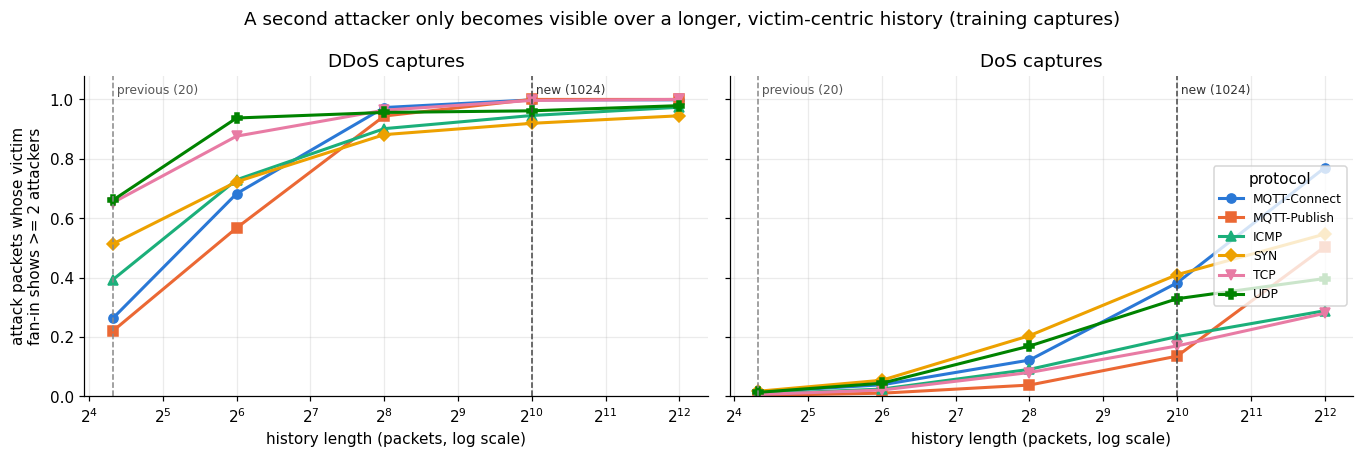

In [ ]:
# ---------------- shared label helpers (used here and by §6 onward) ----------------
VARIANT_CODE = {v: i for i, v in enumerate(HIERARCHY.variant)}
SUBTYPE_OF = HIERARCHY.set_index("variant")["subtype"].to_dict()

def protocol_match(l4, sport, dport, variant):
    """True where a packet's protocol can belong to the capture's attack (all True for Benign)."""
    st = SUBTYPE_OF[variant]
    if st == "Benign":
        return np.ones(len(l4), bool)
    if st in ("SYN", "TCP"):
        return l4 == 6
    if st == "UDP":
        return l4 == 17
    if st == "ICMP":
        return (l4 == 1) | (l4 == 58)
    return (l4 == 6) & (np.isin(sport, rt.MQTT_PORTS) | np.isin(dport, rt.MQTT_PORTS))     # MQTT-*

def dos_ddos_partner(name):
    """'DoS-SYN' -> 'DDoS-SYN', 'MQTT-DoS-Publish' -> 'MQTT-DDoS-Publish', 'DoS' -> 'DDoS'; None if not a DoS name."""
    toks = str(name).split("-")
    return "-".join("DDoS" if t == "DoS" else t for t in toks) if "DoS" in toks else None

DOS_DDOS_PAIRS = [(v, dos_ddos_partner(v)) for v in HIERARCHY.variant if dos_ddos_partner(v) in set(HIERARCHY.variant)]
print("DoS/DDoS pairs:", DOS_DDOS_PAIRS)

def read_cache_blocks(rec, n_blocks):
    """Evenly spaced blocks of a cached capture (one Parquet row group = one block), read without the rest."""
    pf = pq.ParquetFile(cache_paths(rec)[0])
    ids = np.unique(np.round(np.linspace(0, pf.num_row_groups - 1, min(n_blocks, pf.num_row_groups))).astype(int))
    for i in ids:
        rg = pf.read_row_group(int(i)).to_pandas()
        for _, b in rg.groupby("__block__", sort=True):
            yield b.reset_index(drop=True)

def burst_lengths(src):
    """Lengths of runs of consecutive packets from the same source."""
    if len(src) == 0:
        return np.zeros(0, int)
    cut = np.flatnonzero(src[1:] != src[:-1]) + 1
    return np.diff(np.r_[0, cut, len(src)])

DIAG_H = sorted({h for h in DIAG_WINDOWS + [CONTEXT_N, LONG_CONTEXT_N] if h < BLOCK_PACKETS})
diag_key = json.dumps({"cfg": CONFIG_HASH, "blocks": DIAG_BLOCKS_PER_CAPTURE, "rows": DIAG_ROWS_PER_BLOCK, "H": DIAG_H,
                       "rt": rt.RUNTIME_VERSION}, sort_keys=True)
diag_a_path = os.path.join(DIRS["reports"], "dos_ddos_diagnosis_attackers.csv")
diag_b_path = os.path.join(DIRS["reports"], "dos_ddos_diagnosis_separability.csv")
DIAG_ATTACKERS = DIAG_SEPARABILITY = None

if RUN_DOS_DDOS_DIAGNOSIS and DOS_DDOS_PAIRS:
    if (os.path.exists(diag_a_path) and os.path.exists(diag_b_path)
            and pd.read_csv(diag_b_path)["key"].iloc[0] == diag_key):
        DIAG_ATTACKERS, DIAG_SEPARABILITY = pd.read_csv(diag_a_path), pd.read_csv(diag_b_path)
        print("Diagnosis reloaded")
    else:
        in_pair = {v for p in DOS_DDOS_PAIRS for v in p}
        recs = FILES[(FILES.split == "train") & FILES.variant.isin(in_pair)]
        a_rows, samples, t0 = [], [], time.time()
        rng_d = np.random.default_rng(RANDOM_STATE + 11)
        for rec in recs.itertuples(index=False):
            for bnum, b in enumerate(read_cache_blocks(rec, DIAG_BLOCKS_PER_CAPTURE)):
                l4, sp, dp = b.l4.to_numpy(), b.sport.to_numpy(), b.dport.to_numpy()
                src, dst, bpos = b.src_h.to_numpy(), b.dst_h.to_numpy(), b["__bpos__"].to_numpy()
                ok = protocol_match(l4, sp, dp, rec.variant)
                if ok.sum() < 100:
                    continue
                victim = pd.Series(dst[ok]).value_counts().index[0]           # most-targeted host = victim
                to_v = ok & (dst == victim)
                share = pd.Series(src[to_v]).value_counts(normalize=True)
                bl = burst_lengths(src[to_v])
                row = {"variant": rec.variant, "subtype": SUBTYPE_OF[rec.variant], "capture": rec.capture,
                       "block": bnum, "attackers_in_block": int((share >= 0.01).sum()),
                       "burst_median": float(np.median(bl)), "burst_p90": float(np.percentile(bl, 90))}
                gcode = rt._group_codes(dst)
                tgt = to_v & (bpos >= max(DIAG_H))
                for H in DIAG_H:
                    _, fan = rt.window_group_stats(gcode, src, H)
                    row[f"fanin_ge2_H{H}"] = float((fan[tgt] >= 2).mean()) if tgt.any() else np.nan
                a_rows.append(row)
                # ---- sampled feature rows for the separability ladder (same eligibility as training) ----
                F = rt.build_features(b, CONTEXT_N, LONG_CONTEXT_N)
                elig = np.flatnonzero(ok & (bpos >= HISTORY_N))
                if len(elig):
                    k = rng_d.choice(elig, size=min(DIAG_ROWS_PER_BLOCK, len(elig)), replace=False)
                    s = F.iloc[np.sort(k)].copy()
                    s["__variant__"], s["__capture__"], s["__blk__"] = rec.variant, rec.capture, bnum
                    samples.append(s)
                del b, F
            free_memory()
        DIAG_ATTACKERS = pd.DataFrame(a_rows)
        DS = pd.concat(samples, ignore_index=True)
        print(f"Diagnosis data: {len(DIAG_ATTACKERS)} blocks from {len(recs)} training captures, "
              f"{len(DS):,} sampled packets | {time.time() - t0:.0f}s")

        # ---- (B) separability ladder: binary DoS vs DDoS per protocol on unseen capture sessions ----
        from sklearn.ensemble import HistGradientBoostingClassifier
        from sklearn.metrics import balanced_accuracy_score
        LADDER = {"header only": rt.BASE_FEATURES,
                  "+ 20-packet context (previous design)": rt.BASE_FEATURES + rt.CONTEXT_FEATURES,
                  "+ long-horizon features (new design)": rt.TAB_FEATURES,
                  "long-horizon features alone": rt.LONG_FEATURES}
        b_rows = []
        for dos, ddos in DOS_DDOS_PAIRS:
            D = DS[DS["__variant__"].isin([dos, ddos])].reset_index(drop=True)
            if D["__variant__"].nunique() < 2:
                continue
            y = (D["__variant__"] == ddos).to_numpy().astype(int)
            caps = {v: sorted(D.loc[D["__variant__"] == v, "__capture__"].unique()) for v in (dos, ddos)}
            k = min(4, len(caps[dos]), len(caps[ddos]))
            if k >= 2:                                    # leave-capture-out: every fold holds out DoS and DDoS sessions
                folds = [D["__capture__"].isin(caps[dos][f::k] + caps[ddos][f::k]).to_numpy() for f in range(k)]
                split = f"leave-capture-out ({k} folds)"
            else:                                         # one capture per class: last blocks of each capture
                last = D.groupby("__capture__")["__blk__"].transform(lambda s: s >= np.quantile(s, 0.7)).to_numpy()
                folds, split = [last], "chronological (single capture - optimistic)"
            for fs_name, cols in LADDER.items():
                pred = np.full(len(y), -1)
                for te in folds:
                    m = HistGradientBoostingClassifier(max_iter=150, class_weight="balanced", random_state=RANDOM_STATE)
                    m.fit(D.loc[~te, cols], y[~te]); pred[te] = m.predict(D.loc[te, cols])
                ev = pred >= 0
                b_rows.append({"key": diag_key, "pair": f"{dos} vs {ddos}", "subtype": SUBTYPE_OF[dos],
                               "feature_set": fs_name, "split": split,
                               "balanced_accuracy": balanced_accuracy_score(y[ev], pred[ev]), "packets": int(ev.sum())})
            print(f"  ladder done: {dos} vs {ddos} ({split})")
        DIAG_SEPARABILITY = pd.DataFrame(b_rows)
        # old vs new view of the same packets (medians per class)
        _med = DS.groupby("__variant__")[["ctx_n_src", "lh_fanin_dst", "lh_peer_max", "lh_pair_share_min"]].median()
        DIAG_ATTACKERS = DIAG_ATTACKERS.merge(_med.add_prefix("median_").reset_index()
                                              .rename(columns={"__variant__": "variant"}), on="variant", how="left")
        DIAG_ATTACKERS.to_csv(diag_a_path, index=False); DIAG_SEPARABILITY.to_csv(diag_b_path, index=False)
        del DS; free_memory()

    # ---------------- report ----------------
    fan_cols = [c for c in DIAG_ATTACKERS.columns if c.startswith("fanin_ge2_H")]
    med_cols = [c for c in DIAG_ATTACKERS.columns if c.startswith("median_")]
    A = (DIAG_ATTACKERS.groupby(["subtype", "variant"], sort=False)
         [["attackers_in_block", "burst_median", "burst_p90"] + fan_cols + med_cols].median())
    print("\n(A) Per class (medians over blocks). fanin_ge2_H<h>: share of attack packets whose victim fan-in over the "
          "last h packets shows >= 2 attackers.")
    display(A.round(3))
    print("\n(B) Separability ladder - balanced accuracy of DoS vs DDoS (0.5 = not separable):")
    display(DIAG_SEPARABILITY.pivot_table(index=["pair", "split"], columns="feature_set", values="balanced_accuracy",
                                          sort=False)[list(dict.fromkeys(DIAG_SEPARABILITY.feature_set))].round(3))

    # ---- automatic reading of the evidence ----
    ddos_rows = DIAG_ATTACKERS[DIAG_ATTACKERS.variant.str.contains("DDoS")]
    dos_rows = DIAG_ATTACKERS[~DIAG_ATTACKERS.variant.str.contains("DDoS")]
    c20, cL = f"fanin_ge2_H{CONTEXT_N}", f"fanin_ge2_H{LONG_CONTEXT_N}"
    print(f"\nReading:\n  attackers per block: DoS median {dos_rows.attackers_in_block.median():.0f}, "
          f"DDoS median {ddos_rows.attackers_in_block.median():.0f}")
    print(f"  DDoS same-source burst: median {ddos_rows.burst_median.median():.0f} packets, p90 "
          f"{ddos_rows.burst_p90.median():.0f} (short context = {CONTEXT_N} packets)")
    print(f"  DDoS attack packets whose window shows >= 2 attackers: {ddos_rows[c20].mean():.1%} with {CONTEXT_N} "
          f"packets vs {ddos_rows[cL].mean():.1%} with LONG_CONTEXT_N = {LONG_CONTEXT_N}")
    _weak = A[A.index.get_level_values("variant").str.contains("DDoS") & (A[cL] < 0.8)]
    if len(_weak):
        print(f"  NOTE: for {list(_weak.index.get_level_values('variant'))} fewer than 80 % of attack packets see a "
              f"second attacker within {LONG_CONTEXT_N} packets - consider a larger LONG_CONTEXT_N in §3 "
              f"(must stay < BLOCK_PACKETS = {BLOCK_PACKETS}).")

    # ---- figure: how much history is needed to see a second attacker ----
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
    hs = [int(c.split("H")[-1]) for c in fan_cols]
    markers = ["o", "s", "^", "D", "v", "P"]
    for ax, (title, sub) in zip(axes, [("DDoS captures", ddos_rows), ("DoS captures", dos_rows)]):
        for i, st in enumerate(dict.fromkeys(DIAG_ATTACKERS.subtype)):
            r = sub[sub.subtype == st]
            if len(r):
                ax.plot(hs, r[fan_cols].mean().to_numpy(), marker=markers[i % 6], ms=6, lw=2,
                        color=SERIES_COLORS[i % len(SERIES_COLORS)], label=st)
        ax.axvline(CONTEXT_N, color="#888", lw=1, ls="--"); ax.axvline(LONG_CONTEXT_N, color="#444", lw=1, ls="--")
        ax.text(CONTEXT_N, 1.02, f" previous ({CONTEXT_N})", fontsize=8, color="#555")
        ax.text(LONG_CONTEXT_N, 1.02, f" new ({LONG_CONTEXT_N})", fontsize=8, color="#333")
        ax.set_xscale("log", base=2); ax.set_ylim(0, 1.08); ax.set_xlabel("history length (packets, log scale)")
        ax.set_title(title)
    axes[0].set_ylabel("attack packets whose victim\nfan-in shows >= 2 attackers")
    axes[1].legend(title="protocol", fontsize=8, loc="center right")
    fig.suptitle("A second attacker only becomes visible over a longer, victim-centric history (training captures)")
    fig.tight_layout(); save_fig(fig, "dos_ddos_diagnosis_history")
elif not RUN_DOS_DDOS_DIAGNOSIS:
    print("DoS/DDoS diagnosis skipped (RUN_DOS_DDOS_DIAGNOSIS = False)")


## 6. Feature assembly, sequence windowing and temporal batching
Each cached capture is turned into model inputs, **one block at a time**:

* **Features.** `rt.build_features` runs per 20k-packet block (a block is contiguous traffic). Packet *i* only sees
  packets *i−19 … i* (short context) and *i−1023 … i* (long-horizon features) of its own block.
* **Eligibility.** A packet is a training/evaluation target only if its **full history** lies inside its block
  (`position ≥ HISTORY_N = max(CONTEXT_N, LONG_CONTEXT_N)`). The long-horizon features are then computed exactly as
  the live engine computes them, and tabular and sequence models are scored on **exactly the same packets**. This
  excludes the first 1,024 packets of each block (about 5 %).
* **Roles (FIT / gap / VAL / TEST).** Packet index inside the capture decides the role (§9 explains the policy). The purge
  gap is at least `HISTORY_N + 1` packets, so no VAL packet's history (short or long) can contain a FIT packet.
* **Off-protocol packets** (`OFF_PROTOCOL_POLICY = "drop"`): in an attack capture, a packet whose protocol cannot belong
  to that attack (e.g. a TCP:443 web packet inside an ICMP flood) is not used as a target, and the count is reported per
  file in §9. It still appears inside other packets' context windows, as it would on a live network. Benign captures keep
  every packet.
* **Row budgets.** FIT is sampled uniformly up to `FIT_ROWS_PER_CLASS` per class. VAL and TEST use **one uniform
  fraction for all classes**, so their class proportions are not rebalanced.

**Sequence windows without copies.** The per-packet features of *every* extracted packet are written once to a
memory-mapped `float32` array on local disk (`SEQ_STORE`). `SEQ_VIEW = sliding_window_view(SEQ_STORE, …)` is a strided
*view*: window *r* is rows *r−19 … r* and costs 0 bytes until it is indexed. The PyTorch `WindowDataset` indexes one
batch at a time, so at most one batch of windows exists in RAM.

In [ ]:
# VARIANT_CODE, SUBTYPE_OF and protocol_match are defined in §5b
GAP_MIN_EFFECTIVE = max(GAP_MIN_ROWS, HISTORY_N + 1)

def assign_roles(pkt, n_total, split):
    """Chronological tail-block validation inside each training capture, with a purge gap (policy: §9)."""
    if split == "test":
        return np.full(len(pkt), 3, np.int8)                       # 0 fit, 1 gap, 2 val, 3 test
    cut = int(np.floor(n_total * (1 - VAL_FRACTION)))
    gap = int(np.clip(round(n_total * GAP_FRACTION), GAP_MIN_EFFECTIVE, max(GAP_MAX_ROWS, GAP_MIN_EFFECTIVE)))
    gap = min(gap, max(0, (n_total - cut) // 2))
    role = np.zeros(len(pkt), np.int8)
    role[(pkt >= cut) & (pkt < cut + gap)] = 1
    role[pkt >= cut + gap] = 2
    return role
ROLE_NAMES = {0: "fit", 1: "gap", 2: "val", 3: "test"}

def row_labels(proto_ok, variant):
    lab = np.full(len(proto_ok), VARIANT_CODE[variant], np.int8)
    if OFF_PROTOCOL_POLICY == "relabel_benign":
        lab[~proto_ok] = VARIANT_CODE["Benign"]
    return lab

def target_mask(bpos, role, proto_ok):
    m = (bpos >= HISTORY_N) & (role != 1)                         # full short + long history inside the block
    if OFF_PROTOCOL_POLICY == "drop":
        m &= proto_ok
    return m

# ---------------- pass 1: count eligible targets per (file, role, label) - reads 5 small columns only ----------------
plan_rows, count_rows = [], []
for fid, rec in enumerate(FILES.itertuples(index=False)):
    t = pq.read_table(cache_paths(rec)[0], columns=["__pkt__", "__bpos__", "l4", "sport", "dport"]).to_pandas()
    l4, sp, dp = t.l4.to_numpy(), t.sport.to_numpy(), t.dport.to_numpy()
    role = assign_roles(t.__pkt__.to_numpy(), rec.packets_total, rec.split)
    ok = protocol_match(l4, sp, dp, rec.variant)
    lab = row_labels(ok, rec.variant)
    tm_ = target_mask(t.__bpos__.to_numpy(), role, ok)
    plan_rows.append({"fid": fid, "file": rec.file, "variant": rec.variant, "split": rec.split,
                      "extracted": len(t), "warmup_excluded": int((t.__bpos__.to_numpy() < HISTORY_N).sum()),
                      "gap_purged": int((role == 1).sum()), "off_protocol": int((~ok).sum()),
                      "off_protocol_share": round(float((~ok).mean()), 4),
                      "tcp_share": round(float((l4 == 6).mean()), 3), "udp_share": round(float((l4 == 17).mean()), 3),
                      "icmp_share": round(float(np.isin(l4, (1, 58)).mean()), 3),
                      "non_ip_share": round(float((l4 < 0).mean()), 3)})
    for r in (0, 2, 3):
        for c in np.unique(lab[tm_ & (role == r)]):
            count_rows.append({"fid": fid, "role": r, "label": int(c), "n": int((tm_ & (role == r) & (lab == c)).sum())})
    del t
ASSEMBLY = pd.DataFrame(plan_rows)
COUNTS = pd.DataFrame(count_rows)
tot = COUNTS.groupby(["role", "label"]).n.sum()
FRAC_TAB = np.zeros((4, len(HIERARCHY)))           # [role, variant code] -> sampling probability
for (r, c), n in tot.items():
    if r == 0:
        FRAC_TAB[0, c] = min(1.0, FIT_ROWS_PER_CLASS / max(n, 1))
for r, cap in ((2, VAL_MAX_ROWS), (3, TEST_MAX_ROWS)):
    n_r = int(tot[tot.index.get_level_values(0) == r].sum())
    FRAC_TAB[r, :] = min(1.0, cap / max(n_r, 1))
print("Sampling fractions  FIT (per class):",
      {HIERARCHY.variant[c]: round(float(FRAC_TAB[0, c]), 3) for c in range(len(HIERARCHY)) if FRAC_TAB[0, c] > 0})
print(f"                    VAL: {FRAC_TAB[2, 0]:.4f} | TEST: {FRAC_TAB[3, 0]:.4f} (one fraction for every class)")

# ---------------- pass 2: features per block, sampled targets, sequence store ----------------
USE_SEQ = HAS_TORCH and any(m in MODELS_TO_RUN for m in ("birnn", "transformer"))
F_SEQ = len(rt.SEQ_FEATURES)
FILES["store_offset"] = np.concatenate([[0], np.cumsum(FILES.packets_extracted.to_numpy())[:-1]]).astype(np.int64)
N_STORE = int(FILES.packets_extracted.sum())
STORE_KEY = hashlib.sha256(json.dumps({"files": FILES[["fingerprint", "packets_extracted"]].values.tolist(),
                                       "extract": EXTRACT_HASH, "seq": rt.SEQ_FEATURES, "rt": rt.RUNTIME_VERSION,
                                       "n_long": LONG_CONTEXT_N},
                                      sort_keys=True).encode()).hexdigest()[:12]
STORE_PATH = os.path.join(LOCAL_DIR, f"seq_store_{STORE_KEY}.npy")
store_done_flag = STORE_PATH + ".complete"
for _old in glob.glob(os.path.join(LOCAL_DIR, "seq_store_*.npy*")):          # stale stores of an older feature set
    if not os.path.basename(_old).startswith(f"seq_store_{STORE_KEY}"):
        os.remove(_old); print("Removed stale sequence store (rebuildable cache):", os.path.basename(_old))
write_store = USE_SEQ and not os.path.exists(store_done_flag)
if USE_SEQ:
    need_gb = N_STORE * F_SEQ * 4 / 1e9
    print(f"Sequence store: {N_STORE:,} packets x {F_SEQ} features = {need_gb:.2f} GB on local disk "
          f"({'build' if write_store else 'reuse'}: {STORE_PATH})")
    if write_store and shutil.disk_usage(LOCAL_DIR).free / 1e9 < need_gb * 1.1:
        raise OSError(f"Not enough local disk for the sequence store ({need_gb:.1f} GB). Lower PACKETS_PER_CAPTURE.")
    SEQ_STORE = (np.lib.format.open_memmap(STORE_PATH, mode="w+", dtype=np.float32, shape=(N_STORE, F_SEQ))
                 if write_store else np.load(STORE_PATH, mmap_mode="r"))

parts = {r: {"X": [], "y": [], "fid": [], "pkt": [], "ts": [], "seqrow": []} for r in (0, 2, 3)}
_seq_idx = [rt.TAB_FEATURES.index(c) for c in rt.SEQ_FEATURES]
t_asm = time.time()
for fid, rec in enumerate(FILES.itertuples(index=False)):
    mem_guard(f"assemble {rec.file}")
    raw = pq.read_table(cache_paths(rec)[0]).to_pandas()
    blk = raw["__block__"].to_numpy()
    bounds = np.flatnonzero(np.diff(blk)) + 1
    starts, ends_ = np.r_[0, bounds], np.r_[bounds, len(raw)]
    role_all = assign_roles(raw.__pkt__.to_numpy(), rec.packets_total, rec.split)
    ok_all = protocol_match(raw.l4.to_numpy(), raw.sport.to_numpy(), raw.dport.to_numpy(), rec.variant)
    lab_all = row_labels(ok_all, rec.variant)
    tmask = target_mask(raw.__bpos__.to_numpy(), role_all, ok_all)
    rng = np.random.default_rng(int(rec.fingerprint[:8], 16) ^ RANDOM_STATE)
    u = rng.random(len(raw))
    sel = tmask & (u < FRAC_TAB[role_all, lab_all])
    for a, b in zip(starts, ends_):
        F = rt.build_features(raw.iloc[a:b], CONTEXT_N, LONG_CONTEXT_N).to_numpy(np.float32)
        if write_store:
            SEQ_STORE[rec.store_offset + a: rec.store_offset + b] = F[:, _seq_idx]
        s = np.flatnonzero(sel[a:b])
        if len(s):
            for r in (0, 2, 3):
                k = s[role_all[a:b][s] == r]
                if len(k):
                    P = parts[r]
                    P["X"].append(F[k]); P["y"].append(lab_all[a:b][k]); P["fid"].append(np.full(len(k), fid, np.int16))
                    P["pkt"].append(raw.__pkt__.to_numpy()[a:b][k]); P["ts"].append(raw.ts.to_numpy()[a:b][k])
                    P["seqrow"].append(rec.store_offset + a + k)
        del F
    del raw, role_all, ok_all, lab_all, tmask, sel, u
    free_memory()
if write_store:
    SEQ_STORE.flush()
    open(store_done_flag, "w").write(datetime.now(timezone.utc).isoformat())
    del SEQ_STORE
    SEQ_STORE = np.load(STORE_PATH, mmap_mode="r")
print(f"Assembled in {time.time() - t_asm:.0f}s | {mem_status('after assembly')}")

def _cat(P, k, dt):
    return np.concatenate(P[k]).astype(dt, copy=False) if P[k] else np.zeros((0,) if k != "X" else (0, len(rt.TAB_FEATURES)), dt)
RAW_PARTS = {}
for r, name in ((0, "fit"), (2, "val"), (3, "test")):
    P = parts[r]
    RAW_PARTS[name] = {"X": _cat(P, "X", np.float32), "variant_code": _cat(P, "y", np.int8),
                       "fid": _cat(P, "fid", np.int16), "pkt": _cat(P, "pkt", np.int64), "ts": _cat(P, "ts", np.float64),
                       "seqrow": _cat(P, "seqrow", np.int64)}
    parts[r] = None
del parts; free_memory()
for k, v in RAW_PARTS.items():
    print(f"  {k.upper():<4} {len(v['X']):>10,} packets x {v['X'].shape[1]} features ({v['X'].nbytes / 2**20:,.0f} MB)")

# ---------------- strided window view over the memory-mapped store ----------------
if USE_SEQ:
    from numpy.lib.stride_tricks import sliding_window_view
    SEQ_VIEW = sliding_window_view(SEQ_STORE, (CONTEXT_N, F_SEQ))[:, 0]          # (N_STORE-CONTEXT_N+1, N, F) view
    def get_windows(seqrows):
        """Windows ending at the given store rows -> (n, CONTEXT_N, F_SEQ); only these rows are read from disk."""
        return np.asarray(SEQ_VIEW[np.asarray(seqrows, np.int64) - (CONTEXT_N - 1)])
    # consistency check: last window step == the tabular per-packet features of the same packet
    _chk = np.random.default_rng(0).choice(len(RAW_PARTS["fit"]["X"]), size=min(500, len(RAW_PARTS["fit"]["X"])), replace=False)
    _w = get_windows(RAW_PARTS["fit"]["seqrow"][_chk])
    assert np.allclose(_w[:, -1, :], RAW_PARTS["fit"]["X"][_chk][:, _seq_idx]), "window / tabular row mismatch"
    print(f"SEQ_VIEW {SEQ_VIEW.shape} is a strided view (no copy); one batch of {SEQ_BATCH} windows = "
          f"{SEQ_BATCH * CONTEXT_N * F_SEQ * 4 / 2**20:.1f} MB")

    from torch.utils.data import Dataset, DataLoader, BatchSampler, RandomSampler, SequentialSampler

    class WindowDataset(Dataset):
        """Batched lookup: __getitem__ receives a list of positions and returns a whole batch (x, y, w)."""
        def __init__(self, seqrows, y, w=None):
            self.seqrows, self.y = np.asarray(seqrows, np.int64), np.asarray(y, np.int64)
            self.w = np.ones(len(self.y), np.float32) if w is None else np.asarray(w, np.float32)
        def __len__(self):
            return len(self.y)
        def __getitem__(self, pos):
            pos = np.sort(np.asarray(pos))                     # sorted reads are friendlier to the memory map
            return (torch.from_numpy(get_windows(self.seqrows[pos])), torch.from_numpy(self.y[pos]),
                    torch.from_numpy(self.w[pos]))

    def make_loader(ds, batch_size, shuffle, seed=0, num_samples=None):
        if shuffle:
            g = torch.Generator().manual_seed(int(seed))
            sampler = RandomSampler(ds, replacement=False, num_samples=min(num_samples or len(ds), len(ds)), generator=g)
        else:
            sampler = SequentialSampler(ds)
        return DataLoader(ds, sampler=BatchSampler(sampler, batch_size, drop_last=False), batch_size=None,
                          num_workers=0, pin_memory=HAS_CUDA)
else:
    print("Sequence models disabled (no PyTorch or not in MODELS_TO_RUN) - no sequence store built.")

Sampling fractions  FIT (per class): {'Benign': 0.263, 'DoS-SYN': 0.066, 'DoS-TCP': 0.066, 'DoS-UDP': 0.067, 'DoS-ICMP': 0.066, 'DDoS-SYN': 0.066, 'DDoS-TCP': 0.066, 'DDoS-UDP': 0.033, 'DDoS-ICMP': 0.033, 'MQTT-DoS-Connect': 0.264, 'MQTT-DoS-Publish': 0.264, 'MQTT-DDoS-Connect': 0.264, 'MQTT-DDoS-Publish': 0.265}
                    VAL: 0.0805 | TEST: 0.1034 (one fraction for every class)
Sequence store: 57,850,708 packets x 47 features = 10.88 GB on local disk (build: /content/iomt_local/seq_store_85c6a496adab.npy)
Assembled in 265s | [after assembly] RAM 2,567 MB (system avail 8,757 MB) | VRAM 450 MB
  FIT   2,598,912 packets x 74 features (734 MB)
  VAL     651,090 packets x 74 features (184 MB)
  TEST  1,299,644 packets x 74 features (367 MB)
SEQ_VIEW (57850689, 20, 47) is a strided view (no copy); one batch of 1024 windows = 3.7 MB


## 7. Preprocessing pipeline and feature transformation
* Start from the 74 tabular features (66 + 8 long-horizon). Shortcuts and identifiers were excluded in §5.
* Drop columns that are **constant on FIT** and columns that are **exact copies of another column on FIT**. Both
  decisions use FIT only.
* Preprocessor = `ColumnTransformer` with a median imputer. Training rows have no missing values; the imputer protects
  inference against them. It is **fitted on FIT only** and shipped inside every saved tabular pipeline.
* **Scaling** is fitted on FIT only, where it is needed:
  * logistic regression: `arcsinh` (heavy tails) followed by `StandardScaler`, inside the model pipeline;
  * sequence models: `arcsinh` followed by standardisation with FIT statistics, stored as buffers inside the network
    (§13).

  Trees and boosted models are scale-invariant.

In [ ]:
FITDF = pd.DataFrame(RAW_PARTS["fit"]["X"], columns=rt.TAB_FEATURES, copy=False)
const_cols = [c for c in rt.TAB_FEATURES if FITDF[c].nunique(dropna=False) <= 1]
dup_cols, seen = {}, {}
for c in rt.TAB_FEATURES:
    if c in const_cols:
        continue
    key = hashlib.sha1(np.ascontiguousarray(FITDF[c].to_numpy()).tobytes()).hexdigest()
    if key in seen:
        dup_cols[c] = seen[key]
    else:
        seen[key] = c
FEATURES = [c for c in rt.TAB_FEATURES if c not in const_cols and c not in dup_cols]
print(f"{len(FEATURES)} model features (dropped: constant on FIT {const_cols}, duplicate {dup_cols})")

def make_preprocessor(features):
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), features)],
                             remainder="drop", verbose_feature_names_out=False)

PREP = make_preprocessor(FEATURES).fit(FITDF)                          # FIT partition only
def to_matrix(X_raw):
    return PREP.transform(pd.DataFrame(X_raw, columns=rt.TAB_FEATURES, copy=False)).astype(np.float32, copy=False)

X_fit, X_val, X_test = (to_matrix(RAW_PARTS[r]["X"]) for r in ("fit", "val", "test"))
_s = FITDF.sample(n=min(50_000, len(FITDF)), random_state=RANDOM_STATE)[FEATURES]
_corr = _s.corr().abs().where(np.triu(np.ones((len(FEATURES),) * 2, bool), 1)).stack()
print("Most correlated feature pairs (|r|, FIT sample) - informative only:")
print(_corr.sort_values(ascending=False).head(10).round(3).to_string())
for r in RAW_PARTS:
    RAW_PARTS[r]["X"] = None                                           # the raw 66-column copies are no longer needed
del FITDF, _s; free_memory()
print(f"FIT {X_fit.shape} | VAL {X_val.shape} | TEST {X_test.shape} | {mem_status('preprocessed')}")

69 model features (dropped: constant on FIT ['ip_mf', 'ip_frag', 'tcp_urg', 'malformed'], duplicate {'tcp_cwr': 'tcp_ece'})
Most correlated feature pairs (|r|, FIT sample) - informative only:
ctx_len_mean      ctx_len_sum         1.000
is_icmp           icmp_code           1.000
frame_len         payload_len         1.000
ctx_len_sum       ctx_payload_mean    1.000
ctx_len_mean      ctx_payload_mean    1.000
ctx_log_iat_mean  ctx_log_pkt_rate    0.999
is_icmp           ctx_icmp_ratio      0.999
icmp_code         ctx_icmp_ratio      0.999
is_tcp            ctx_tcp_ratio       0.989
is_udp            ctx_udp_ratio       0.986
FIT (2598912, 69) | VAL (651090, 69) | TEST (1299644, 69) | [preprocessed] RAM 3,847 MB (system avail 7,469 MB) | VRAM 450 MB


## 8. Label mapping, hierarchy encodings and matrix collapsing
Classes are encoded in the fixed order of `LABEL_RULES` (stable across runs, saved with the model). Coarser levels are
obtained with fixed 0/1 **collapse matrices**: $P_{\text{coarse}} = P_{\text{variant}} \cdot M$, where $M_{13\to 7}$,
$M_{13\to 4}$ and $M_{13\to 2}$ have exactly one 1 per row. One trained model is therefore evaluated at 13 / 7 / 4 / 2
classes without retraining. A coarser level is only reported when it is a function of the training level.

In [ ]:
TRAIN_CLASSES = list(dict.fromkeys(HIERARCHY.set_index("variant", drop=False).loc[CLASS_NAMES_VARIANT, TRAIN_LEVEL]))
K = len(TRAIN_CLASSES)
CLASS_INDEX = {c: i for i, c in enumerate(TRAIN_CLASSES)}
_hv = HIERARCHY.set_index("variant", drop=False)

def to_train_label(variant_codes):
    names = HIERARCHY.variant.to_numpy()[np.asarray(variant_codes, int)]
    if TRAIN_LEVEL != "variant":
        names = _hv.loc[names, TRAIN_LEVEL].to_numpy()
    return pd.Series(names).map(CLASS_INDEX).to_numpy(np.int64)

y_fit, y_val, y_test = (to_train_label(RAW_PARTS[r]["variant_code"]) for r in ("fit", "val", "test"))
assert not any(np.isnan(y.astype(float)).any() for y in (y_fit, y_val, y_test))
w_fit, w_val, w_test = (np.ones(len(y), np.float64) for y in (y_fit, y_val, y_test))   # one row = one packet

_h = HIERARCHY.drop_duplicates(TRAIN_LEVEL).set_index(TRAIN_LEVEL, drop=False)
EVAL_LEVELS = {}
for lv in LEVELS[LEVELS.index(TRAIN_LEVEL):]:
    if HIERARCHY.groupby(TRAIN_LEVEL)[lv].nunique().max() != 1:
        continue
    names = list(dict.fromkeys(_h.loc[TRAIN_CLASSES, lv]))
    M = np.zeros((K, len(names)))
    for i, c in enumerate(TRAIN_CLASSES):
        M[i, names.index(_h.loc[c, lv])] = 1
    EVAL_LEVELS[lv] = (names, M)
print("Training level:", TRAIN_LEVEL, f"({K} classes) | reported levels:", {lv: len(n) for lv, (n, _) in EVAL_LEVELS.items()})
for lv, (names, M) in list(EVAL_LEVELS.items())[1:]:
    print(f"\nCollapse matrix M ({K} -> {len(names)}, {lv}):")
    display(pd.DataFrame(M.astype(int), index=TRAIN_CLASSES, columns=names))
with open(os.path.join(DIRS["reports"], "label_mapping.json"), "w") as f:
    json.dump({"train_level": TRAIN_LEVEL, "classes": TRAIN_CLASSES, "label_rules": LABEL_RULES,
               "hierarchy": HIERARCHY.to_dict("records"),
               "collapse_matrices": {lv: {"names": n, "M": M.tolist()} for lv, (n, M) in EVAL_LEVELS.items()}}, f, indent=2)

def meta_frame(part):
    P = RAW_PARTS[part]
    return pd.DataFrame({"__variant__": pd.Categorical(HIERARCHY.variant.to_numpy()[P["variant_code"].astype(int)],
                                                       categories=list(HIERARCHY.variant)),
                         "__file__": pd.Categorical(FILES.file.to_numpy()[P["fid"]]),
                         "__capture__": pd.Categorical(FILES.capture.to_numpy()[P["fid"]]),
                         "__pkt__": P["pkt"], "__ts__": P["ts"], "__seqrow__": P["seqrow"]})
META_fit, META_val, META_test = (meta_frame(r) for r in ("fit", "val", "test"))
PARTS = {"fit": dict(X=X_fit, y=y_fit, w=w_fit, meta=META_fit), "val": dict(X=X_val, y=y_val, w=w_val, meta=META_val),
         "test": dict(X=X_test, y=y_test, w=w_test, meta=META_test)}

Training level: variant (13 classes) | reported levels: {'variant': 13, 'subtype': 7, 'family': 4, 'binary': 2}

Collapse matrix M (13 -> 7, subtype):


,Benign,SYN,TCP,UDP,ICMP,MQTT-Connect,MQTT-Publish
Benign,1,0,0,0,0,0,0
DoS-SYN,0,1,0,0,0,0,0
DoS-TCP,0,0,1,0,0,0,0
DoS-UDP,0,0,0,1,0,0,0
DoS-ICMP,0,0,0,0,1,0,0
DDoS-SYN,0,1,0,0,0,0,0
DDoS-TCP,0,0,1,0,0,0,0
DDoS-UDP,0,0,0,1,0,0,0
DDoS-ICMP,0,0,0,0,1,0,0
MQTT-DoS-Connect,0,0,0,0,0,1,0



Collapse matrix M (13 -> 4, family):


,Benign,DoS,DDoS,MQTT-Flood
Benign,1,0,0,0
DoS-SYN,0,1,0,0
DoS-TCP,0,1,0,0
DoS-UDP,0,1,0,0
DoS-ICMP,0,1,0,0
DDoS-SYN,0,0,1,0
DDoS-TCP,0,0,1,0
DDoS-UDP,0,0,1,0
DDoS-ICMP,0,0,1,0
MQTT-DoS-Connect,0,0,0,1



Collapse matrix M (13 -> 2, binary):


,Benign,Attack
Benign,1,0
DoS-SYN,0,1
DoS-TCP,0,1
DoS-UDP,0,1
DoS-ICMP,0,1
DDoS-SYN,0,1
DDoS-TCP,0,1
DDoS-UDP,0,1
DDoS-ICMP,0,1
MQTT-DoS-Connect,0,1


## 9. Leakage-safe data splitting and purge gaps
| Partition | Source | Used for |
|---|---|---|
| **FIT** | first 80 % of the packets of every `_train` capture | fitting preprocessors, normalisation and models |
| **gap** | next 1 % (≥ `HISTORY_N + 1` packets, ≤ 5,000) | **purged**: never used |
| **VAL** | remaining ~19 % of every `_train` capture | early stopping, tuning, model selection, calibration |
| **TEST** | every `_test` capture (official CIC split, separate capture sessions) | **one final evaluation only** |

Why not a random packet split: neighbouring packets in a flood are near-copies, and their context windows overlap. A
random split would put near-copies on both sides and inflate every score. The tail block keeps time order, and the gap
is longer than the longest history (`HISTORY_N` = 1,024 packets), so no VAL packet's features use a FIT packet. Splitting inside every capture keeps all classes
in VAL in their natural proportions. Whole-capture grouping is tested in §17 (**leave-capture-out**) for classes recorded
in several training sessions.

This section also audits the assembled data: class distribution, off-protocol packets, shortcut evidence, identical
feature vectors with different labels (label conflicts), and feature vectors shared between FIT and TEST.

,FIT,VAL,TEST
Benign,200150,14800,36960
DoS-SYN,199727,58949,97732
DoS-TCP,199822,58146,96464
DoS-UDP,199827,57327,95821
DoS-ICMP,199712,57054,96819
DDoS-SYN,200122,59909,96919
DDoS-TCP,198963,58204,97429
DDoS-UDP,200172,113021,194788
DDoS-ICMP,199908,114743,192730
MQTT-DoS-Connect,200223,14729,30529


No capture file is shared between TEST and FIT/VAL.
Every training capture: FIT packets precede VAL packets; minimum gap 5000 packets >= HISTORY_N (1024), so no VAL packet's short or long history contains a FIT packet.

Per-capture assembly report (off-protocol packets are dropped as targets under the 'drop' policy):


,file,variant,split,extracted,warmup_excluded,gap_purged,off_protocol,off_protocol_share,tcp_share,udp_share,icmp_share,non_ip_share
0,Benign_test.pcap,Benign,test,377536,19456,0,0,0.0000,0.826,0.156,0.000,0.018
1,Benign_train.pcap,Benign,train,995680,51200,0,0,0.0000,0.901,0.079,0.000,0.020
2,MQTT-DDoS-Connect_Flood_test.pcap,MQTT-DDoS-Connect,test,989922,51200,0,98,0.0001,1.000,0.000,0.000,0.000
3,MQTT-DDoS-Connect_Flood_train.pcap,MQTT-DDoS-Connect,train,995946,51200,0,1009,0.0010,1.000,0.000,0.000,0.000
4,MQTT-DDoS-Publish_Flood_test.pcap,MQTT-DDoS-Publish,test,840207,43215,0,515,0.0006,1.000,0.000,0.000,0.000
5,MQTT-DDoS-Publish_Flood_train.pcap,MQTT-DDoS-Publish,train,994292,51200,0,4981,0.0050,1.000,0.000,0.000,0.000
6,MQTT-DoS-Connect_Flood_test.pcap,MQTT-DoS-Connect,test,312927,16384,0,784,0.0025,0.999,0.001,0.000,0.000
7,MQTT-DoS-Connect_Flood_train.pcap,MQTT-DoS-Connect,train,996947,51200,5000,1148,0.0012,1.000,0.000,0.000,0.000
8,MQTT-DoS-Publish_Flood_test.pcap,MQTT-DoS-Publish,test,849206,44032,0,362,0.0004,1.000,0.000,0.000,0.000
9,MQTT-DoS-Publish_Flood_train.pcap,MQTT-DoS-Publish,train,991579,51200,0,3079,0.0031,1.000,0.000,0.000,0.000


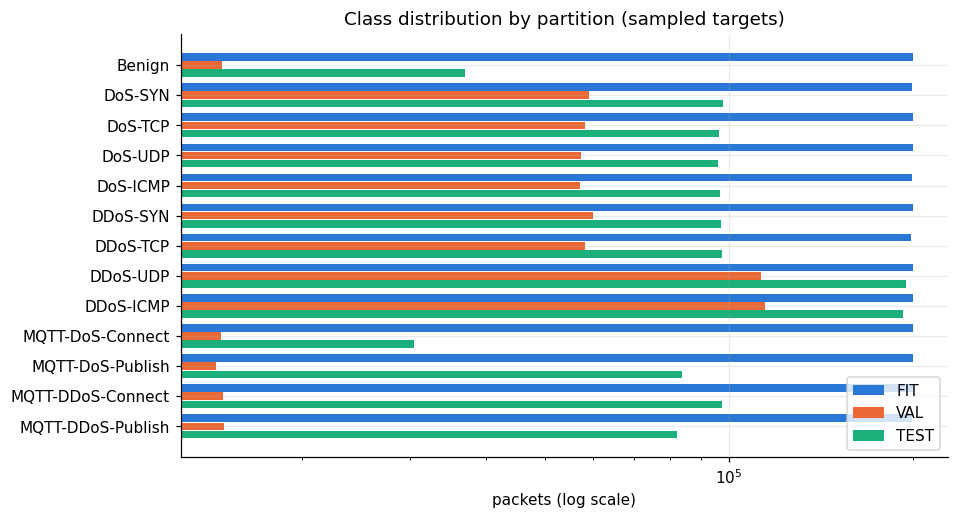


Shortcut evidence: capture time ranges overlap for 0 adjacent pair(s) out of 59. A model given the epoch timestamp could identify the capture (and therefore its label) without looking at traffic at all - timestamp and packet_no are excluded and tested in the §17 ablation.


,variant,part,start_utc,minutes
__file__,,,,
MQTT-DoS-Connect_Flood_train.pcap,MQTT-DoS-Connect,FIT,2023-08-28 18:26,6.9
MQTT-DoS-Connect_Flood_test.pcap,MQTT-DoS-Connect,TEST,2023-08-28 18:32,4.0
MQTT-DoS-Publish_Flood_train.pcap,MQTT-DoS-Publish,FIT,2023-08-29 17:19,8.7
MQTT-DoS-Publish_Flood_test.pcap,MQTT-DoS-Publish,TEST,2023-08-29 17:28,2.0
MQTT-DDoS-Publish_Flood_train.pcap,MQTT-DDoS-Publish,FIT,2023-08-29 19:57,8.1
MQTT-DDoS-Publish_Flood_test.pcap,MQTT-DDoS-Publish,TEST,2023-08-29 20:05,2.2
MQTT-DDoS-Connect_Flood_train.pcap,MQTT-DDoS-Connect,FIT,2023-08-29 20:19,8.8
MQTT-DDoS-Connect_Flood_test.pcap,MQTT-DDoS-Connect,TEST,2023-08-29 20:27,2.1
TCP_IP-DoS-TCP1_train.pcap,DoS-TCP,FIT,2023-08-30 16:08,57.1



Label conflicts (identical feature vectors with different labels) - a floor on any per-packet model's error:


,fit_conflicting_row_share,fit_min_error_floor,test_conflicting_row_share,test_min_error_floor
variant,0.0,0.0,0.0,0.0
subtype,0.0,0.0,0.0,0.0
family,0.0,0.0,0.0,0.0
binary,0.0,0.0,0.0,0.0


TEST packets whose exact feature vector also occurs in FIT: 0.0% (different captures, identical traffic - common in floods; reported, not hidden)


In [ ]:
SPLIT_TABLE = pd.DataFrame({r.upper(): pd.Series(np.bincount(PARTS[r]["y"], minlength=K), index=TRAIN_CLASSES)
                            for r in ("fit", "val", "test")})
display(SPLIT_TABLE)
missing = SPLIT_TABLE[(SPLIT_TABLE == 0).any(axis=1)]
if len(missing):
    print("WARNING - classes absent from a partition (their metrics are reported as undefined):\n", missing)

# ---- capture isolation ----
assert not set(META_test["__file__"]) & set(META_fit["__file__"]), "a test capture leaked into FIT"
assert not set(META_test["__file__"]) & set(META_val["__file__"]), "a test capture leaked into VAL"
assert set(FILES.loc[FILES.split == "test", "file"]) >= set(META_test["__file__"].astype(str))
print("No capture file is shared between TEST and FIT/VAL.")

# ---- temporal order + purge gap inside every training capture ----
bounds = []
for fn, g in pd.concat([META_fit.assign(r="fit"), META_val.assign(r="val")]).groupby("__file__", observed=True):
    lf, fv = g.loc[g.r == "fit", "__pkt__"], g.loc[g.r == "val", "__pkt__"]
    bounds.append({"file": fn, "last_fit_pkt": int(lf.max()) if len(lf) else -1,
                   "first_val_pkt": int(fv.min()) if len(fv) else -1})
BOUNDS = pd.DataFrame(bounds)
BOUNDS["gap_pkts"] = BOUNDS.first_val_pkt - BOUNDS.last_fit_pkt - 1
_b = BOUNDS[(BOUNDS.first_val_pkt >= 0) & (BOUNDS.last_fit_pkt >= 0)]
assert (_b.gap_pkts >= HISTORY_N).all(), "a VAL packet's history could reach a FIT packet"
print(f"Every training capture: FIT packets precede VAL packets; minimum gap {int(_b.gap_pkts.min()) if len(_b) else 'n/a'} "
      f"packets >= HISTORY_N ({HISTORY_N}), so no VAL packet's short or long history contains a FIT packet.")

# ---- off-protocol / eligibility report (never silent) ----
print("\nPer-capture assembly report (off-protocol packets are dropped as targets under the 'drop' policy):")
display(ASSEMBLY.drop(columns=["fid"]))
ASSEMBLY.to_csv(os.path.join(DIRS["reports"], "assembly_report.csv"), index=False)

# ---- class distribution plot ----
fig, ax = plt.subplots(figsize=(9, 5)); ypos = np.arange(K)
for i, r in enumerate(["FIT", "VAL", "TEST"]):
    ax.barh(ypos + (i - 1) * 0.27, SPLIT_TABLE[r].clip(lower=1), height=0.25, label=r, color=SERIES_COLORS[i])
ax.set_yticks(ypos, TRAIN_CLASSES); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("packets (log scale)"); ax.set_title("Class distribution by partition (sampled targets)"); ax.legend()
save_fig(fig, "class_distribution")

# ---- shortcut evidence: the epoch timestamp alone identifies the capture session ----
_all = pd.concat([META_fit.assign(part="FIT"), META_val.assign(part="VAL"), META_test.assign(part="TEST")])
ts_rng = (_all.groupby("__file__", observed=True)
          .agg(variant=("__variant__", "first"), part=("part", "first"), ts_min=("__ts__", "min"), ts_max=("__ts__", "max")))
ts_rng["start_utc"] = pd.to_datetime(ts_rng.ts_min, unit="s", utc=True).dt.strftime("%Y-%m-%d %H:%M")
ts_rng["minutes"] = ((ts_rng.ts_max - ts_rng.ts_min) / 60).round(1)
_sorted = ts_rng.sort_values("ts_min")
overlaps = int((_sorted.ts_min.to_numpy()[1:] < _sorted.ts_max.to_numpy()[:-1]).sum())
print(f"\nShortcut evidence: capture time ranges overlap for {overlaps} adjacent pair(s) out of {len(_sorted) - 1}. "
      "A model given the epoch timestamp could identify the capture (and therefore its label) without looking at "
      "traffic at all - timestamp and packet_no are excluded and tested in the §17 ablation.")
display(ts_rng[["variant", "part", "start_utc", "minutes"]].sort_values("start_utc"))
del _all

# ---- label conflicts: identical feature vectors carrying different labels ----
def row_hash(X):
    return pd.util.hash_pandas_object(pd.DataFrame(X, copy=False), index=False).to_numpy()
ROW_HASH = {p: row_hash(PARTS[p]["X"]) for p in ("fit", "test")}          # hashed once per partition
def conflict_floor(h, y, level):
    names, M = EVAL_LEVELS[level]
    g = pd.DataFrame({"h": h, "l": M.argmax(1)[y]}).groupby(["h", "l"]).size()
    per_h = g.groupby(level=0)
    conflicted = per_h.size()[per_h.size() > 1].index
    share = g[g.index.get_level_values(0).isin(conflicted)].sum() / len(y)
    floor = (per_h.sum() - per_h.max()).sum() / len(y)
    return share, floor
CONFLICTS = pd.DataFrame({f"{p}_{m}": {lv: conflict_floor(ROW_HASH[p], PARTS[p]["y"], lv)[i] for lv in EVAL_LEVELS}
                          for p in ("fit", "test") for i, m in enumerate(["conflicting_row_share", "min_error_floor"])}).round(4)
print("\nLabel conflicts (identical feature vectors with different labels) - a floor on any per-packet model's error:")
display(CONFLICTS)
CONFLICTS.to_csv(os.path.join(DIRS["reports"], "label_conflicts.csv"))
print(f"TEST packets whose exact feature vector also occurs in FIT: {np.isin(ROW_HASH['test'], ROW_HASH['fit']).mean():.1%} "
      "(different captures, identical traffic - common in floods; reported, not hidden)")
del ROW_HASH; free_memory()

## 10. Training framework, weighting schemes and baselines
Every model goes through the same machinery:

* **Weights.** One row = one packet (weight 1) × an optional class weight. Class weighting (`none` / `sqrt_balanced` /
  `balanced`) is tuned like any other hyper-parameter. For the neural networks it becomes the per-class weight of the
  cross-entropy loss. SMOTE is not used: interpolating between flood packets would create traffic that never occurs.
  VAL and TEST are never re-weighted or resampled.
* **Tuning set.** Searches train on a class-stratified draw of FIT (`TUNE_ROWS_PER_CLASS` per class) and score on the
  **full VAL** partition. Every finished trial is appended to `tuning/trials.csv` immediately; a re-run skips trials that
  already exist.
* **Final fit.** The best trial per model (VAL macro-F1, then worst-class recall, then benign false-alarm rate) is
  **refit on all FIT rows** and saved at once (`.joblib` pipeline, plus `.json` for XGBoost, `.txt` for LightGBM, `.pt`
  for PyTorch) with a `meta.json`. A re-run reloads it when the configuration is unchanged. Peak RAM/VRAM during
  training is recorded.
* **Evaluation.** One `evaluate()` computes every metric: accuracy, balanced accuracy, macro/weighted P-R-F1, per-class
  P-R-F1-support and one-vs-rest FPR, confusion matrix, OvR ROC-AUC, log-loss, multiclass Brier, top-label ECE, benign
  false-alarm rate, attack-missed-as-benign rate and the **DoS↔DDoS swap rate** (share of DoS/DDoS packets
  predicted as the other scale of the same protocol). Classes with no true rows are undefined (NaN) and excluded from
  macro averages.

In [ ]:
TRIALS_PATH = os.path.join(DIRS["tuning"], "trials.csv")
WEIGHT_SCHEMES = ["none", "sqrt_balanced", "balanced"]
SEQ_MODELS = ("birnn", "transformer")
MODEL_KIND = {m: ("sequence" if m in SEQ_MODELS else "tabular") for m in ["dummy"] + MODELS_TO_RUN}

def class_weight_vector(y, w, scheme):
    totals = np.bincount(y, weights=w, minlength=K).astype(float)
    cw, pres = np.ones(K), totals > 0
    if scheme in ("balanced", "sqrt_balanced"):
        cw[pres] = totals[pres].sum() / (pres.sum() * totals[pres])
        if scheme == "sqrt_balanced":
            cw = np.sqrt(cw)
    return cw

def apply_class_weighting(y, w, scheme):
    sw = w * class_weight_vector(y, w, scheme)[y]
    return sw * (w.sum() / sw.sum())

def draw_tuning_set(y, cap, seed):
    rng = np.random.default_rng(seed)
    idx = [rng.choice(np.flatnonzero(y == c), size=min(cap, int((y == c).sum())), replace=False)
           for c in range(K) if (y == c).any()]
    return np.sort(np.concatenate(idx))
TUNE_IDX = draw_tuning_set(y_fit, TUNE_ROWS_PER_CLASS, RANDOM_STATE)
print(f"Tuning set: {len(TUNE_IDX):,} FIT packets ({TUNE_ROWS_PER_CLASS:,} per class max)")

def full_proba(model, X):
    p = model.predict_proba(X)
    cls = np.asarray(getattr(model, "classes_", np.arange(p.shape[1])), dtype=int)
    if p.shape[1] == K and np.array_equal(cls, np.arange(K)):
        return p
    out = np.zeros((len(X), K)); out[:, cls] = p
    return out

def predict_windows(pred, seqrows, chunk=16_384):
    return np.concatenate([pred.predict_proba(get_windows(seqrows[a:a + chunk]))
                           for a in range(0, len(seqrows), chunk)]) if len(seqrows) else np.zeros((0, K))

def proba_of(name, model, part, idx=None):
    """Probabilities of any model on a partition ('fit' / 'val' / 'test'), optionally a subset of rows."""
    P = PARTS[part]
    if MODEL_KIND[name] == "sequence":
        rows = P["meta"]["__seqrow__"].to_numpy()
        return predict_windows(model, rows if idx is None else rows[idx])
    return full_proba(model, P["X"] if idx is None else P["X"][idx])

def ece_top_label(y, proba, w, n_bins=15):
    conf, correct = proba.max(1), (proba.argmax(1) == y).astype(float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    W = np.bincount(b, weights=w, minlength=n_bins)
    acc = np.bincount(b, weights=w * correct, minlength=n_bins)
    cf = np.bincount(b, weights=w * conf, minlength=n_bins)
    return float(np.abs(acc - cf).sum() / W.sum()), (W, acc, cf)

def dos_ddos_table(cm, names):
    """Per DoS/DDoS pair of the same protocol: how often each side is predicted as the other scale."""
    rows = []
    for a, nm in enumerate(names):
        p = dos_ddos_partner(nm)
        if p is None or p not in names:
            continue
        b = names.index(p); sa, sb = cm[a].sum(), cm[b].sum()
        rows.append({"pair": f"{nm} / {p}", "dos_support": sa, "ddos_support": sb,
                     "dos_as_ddos": cm[a, b] / sa if sa else np.nan, "ddos_as_dos": cm[b, a] / sb if sb else np.nan,
                     "swap_rate": (cm[a, b] + cm[b, a]) / (sa + sb) if sa + sb else np.nan})
    return pd.DataFrame(rows, columns=["pair", "dos_support", "ddos_support", "dos_as_ddos", "ddos_as_dos", "swap_rate"])

def evaluate(y, proba, w, names):
    L = len(names); labels = np.arange(L); pred = proba.argmax(1)
    support = np.bincount(y, weights=w, minlength=L); pres = support > 0
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=labels, sample_weight=w, zero_division=0)
    pred_w = np.bincount(pred, weights=w, minlength=L)
    cm = confusion_matrix(y, pred, labels=labels, sample_weight=w)
    tot = w.sum(); fp = cm.sum(0) - np.diag(cm); neg = tot - support
    per = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": support,
                        "fpr_ovr": np.where(neg > 0, fp / np.maximum(neg, 1e-12), np.nan), "predicted": pred_w}, index=names)
    per.loc[~pres, ["precision", "recall", "f1"]] = np.nan
    s = {"accuracy": float(np.average(pred == y, weights=w)), "balanced_accuracy": float(r[pres].mean()),
         "macro_precision": float(p[pres].mean()), "macro_recall": float(r[pres].mean()), "macro_f1": float(f[pres].mean()),
         "weighted_precision": float(np.average(p[pres], weights=support[pres])),
         "weighted_recall": float(np.average(r[pres], weights=support[pres])),
         "weighted_f1": float(np.average(f[pres], weights=support[pres])),
         "min_class_recall": float(r[pres].min()), "worst_class": names[int(np.where(pres, r, 9).argmin())],
         "n_classes_absent": int((~pres).sum()), "n_classes_never_predicted": int((pres & (pred_w == 0)).sum()),
         "log_loss": float(-np.average(np.log(np.clip(proba[np.arange(len(y)), y], 1e-15, 1)), weights=w)),
         "brier": float(np.average(((proba - np.eye(L)[y]) ** 2).sum(1), weights=w)),
         "ece": ece_top_label(y, proba, w)[0]}
    try:
        q = proba[:, pres]; q = q / np.clip(q.sum(1, keepdims=True), 1e-12, None)
        ymap = np.full(L, -1); ymap[pres] = np.arange(pres.sum()); yy = ymap[y]
        if pres.sum() == 2:
            s["roc_auc_ovr_macro"] = s["roc_auc_ovr_weighted"] = float(roc_auc_score(yy, q[:, 1], sample_weight=w))
        elif pres.sum() > 2:
            for avg in ("macro", "weighted"):
                s[f"roc_auc_ovr_{avg}"] = float(roc_auc_score(yy, q, multi_class="ovr", average=avg, sample_weight=w,
                                                              labels=np.arange(pres.sum())))
    except ValueError:
        s["roc_auc_ovr_macro"] = s["roc_auc_ovr_weighted"] = np.nan
    _sw = dos_ddos_table(cm, list(names))
    if len(_sw):                                     # share of DoS/DDoS packets assigned to the wrong attack scale
        s["dos_ddos_swap_rate"] = float((_sw.swap_rate * (_sw.dos_support + _sw.ddos_support)).sum()
                                        / max((_sw.dos_support + _sw.ddos_support).sum(), 1e-12))
    if "Benign" in names:
        bi = names.index("Benign"); att = labels != bi
        s["benign_false_alarm_rate"] = float((cm[bi].sum() - cm[bi, bi]) / support[bi]) if support[bi] else np.nan
        s["attack_missed_as_benign_rate"] = float(cm[att, bi].sum() / support[att].sum()) if support[att].sum() else np.nan
    return {"summary": s, "per_class": per, "cm": cm, "names": list(names)}

def evaluate_levels(y, proba, w):
    return {lv: evaluate(M.argmax(1)[y], proba @ M, w, names) for lv, (names, M) in EVAL_LEVELS.items()}

# ---------------- search spaces ----------------
SPACES = {
    "logreg":        {"C": [0.01, 0.1, 1.0, 10.0], "class_weighting": WEIGHT_SCHEMES},
    "decision_tree": {"max_depth": [8, 12, 16, 24, None], "min_samples_leaf": [1, 5, 20, 50],
                      "criterion": ["gini", "entropy"], "class_weighting": WEIGHT_SCHEMES},
    # depth / leaf limits keep a forest on millions of raw packets inside the RAM ceiling and the edge-memory budget
    "random_forest": {"n_estimators": [100, 200], "max_depth": [16, 24, 32], "min_samples_leaf": [2, 5, 10],
                      "max_features": ["sqrt", 0.3, 0.5], "max_samples": [0.05, 0.1, 0.25], "class_weighting": WEIGHT_SCHEMES},
    "adaboost":      {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0], "max_depth": [1, 2, 3],
                      "class_weighting": WEIGHT_SCHEMES},
    "xgboost":       {"max_depth": [4, 6, 8, 10], "learning_rate": [0.05, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0],
                      "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 10], "reg_lambda": [1, 5, 10],
                      "reg_alpha": [0, 0.5, 1], "gamma": [0, 0.5], "class_weighting": WEIGHT_SCHEMES},
    "lightgbm":      {"num_leaves": [31, 63, 127], "learning_rate": [0.05, 0.1, 0.2], "colsample_bytree": [0.6, 0.8, 1.0],
                      "subsample": [0.7, 0.85, 1.0], "min_child_samples": [10, 30, 100], "reg_lambda": [0, 1, 5],
                      "class_weighting": WEIGHT_SCHEMES},
    "birnn":         {"cell": ["lstm", "gru"], "hidden": [64, 128], "layers": [2], "dropout": [0.1, 0.2, 0.3],
                      "lr": [1e-3, 2e-3], "weight_decay": [1e-4, 1e-2], "class_weighting": WEIGHT_SCHEMES},
    "transformer":   {"d_model": [64, 96], "n_heads": [4], "n_layers": [2, 3], "ff_mult": [2, 4], "dropout": [0.1, 0.2],
                      "lr": [5e-4, 1e-3], "weight_decay": [1e-4, 1e-2], "class_weighting": WEIGHT_SCHEMES},
}

# AdaBoost: SAMME.R was deprecated in scikit-learn 1.4 and removed in 1.6; use it only where it still exists.
_ADA_PARAMS = inspect.signature(AdaBoostClassifier).parameters
def _samme_r_available():
    if "algorithm" not in _ADA_PARAMS:
        return False
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            AdaBoostClassifier(algorithm="SAMME.R", n_estimators=2).fit(np.random.rand(20, 2), np.arange(20) % 3)
        return True
    except Exception:
        return False
ADA_ALGORITHM = "SAMME.R" if _samme_r_available() else "SAMME"
ADA_KW = {"algorithm": ADA_ALGORITHM} if "algorithm" in _ADA_PARAMS else {}
print(f"AdaBoost algorithm: {ADA_ALGORITHM} (scikit-learn {sklearn.__version__}"
      f"{'' if ADA_ALGORITHM == 'SAMME.R' else ' - SAMME.R no longer exists, SAMME is used'})")

# FIX (cudaErrorNoDevice): a booster trained with device="cuda" stays GPU-bound inside its pickle, even after
# set_params(device="cpu"), so joblib.load() fails in any process / machine without a CUDA device (the benchmark
# subprocess hides the GPU on purpose). Round-tripping through XGBoost's native, device-free UBJSON format gives a
# booster that was never bound to a GPU. Only the early-stopping-selected rounds are kept, and the copy is verified
# to reproduce the original predictions.
def xgb_to_cpu(clf):
    booster = clf.get_booster()
    try:
        booster = booster[: int(booster.best_iteration) + 1]
    except Exception:
        pass
    raw = booster.save_raw("ubj")
    params = clf.get_params(); params["device"] = "cpu"
    new = xgb.XGBClassifier(**params)
    new.load_model(bytearray(raw))
    probe = np.random.default_rng(0).normal(size=(256, int(clf.n_features_in_))).astype(np.float32)
    if not np.allclose(clf.predict_proba(probe), new.predict_proba(probe), atol=1e-4):
        raise RuntimeError("xgb_to_cpu: the CPU copy does not reproduce the original predictions")
    return new

def fit_model(name, params, X, y, w, Xv=None, yv=None, wv=None):
    """Tabular estimators. Returns (fitted estimator, info)."""
    params = dict(params); scheme = params.pop("class_weighting", "none")
    sw = apply_class_weighting(y, w, scheme); info = {}
    if name == "dummy":
        m = DummyClassifier(strategy="prior").fit(X, y, sample_weight=sw)
    elif name == "logreg":
        m = Pipeline([("arcsinh", FunctionTransformer(np.arcsinh)), ("scale", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE, **params))])
        m.fit(X, y, clf__sample_weight=sw)
    elif name == "decision_tree":
        m = DecisionTreeClassifier(random_state=RANDOM_STATE, **params).fit(X, y, sample_weight=sw)
    elif name == "random_forest":
        m = RandomForestClassifier(n_jobs=N_JOBS, random_state=RANDOM_STATE, **params).fit(X, y, sample_weight=sw)
    elif name == "adaboost":
        depth = params.pop("max_depth")
        m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
                               random_state=RANDOM_STATE, **ADA_KW, **params).fit(X, y, sample_weight=sw)
    elif name == "xgboost":
        m = xgb.XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                              device=XGB_DEVICE, n_estimators=MAX_BOOST_ROUNDS, early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                              n_jobs=N_JOBS, random_state=RANDOM_STATE, **params)
        m.fit(X, y, sample_weight=sw, eval_set=[(Xv, yv)], sample_weight_eval_set=[wv], verbose=False)
        info["best_iteration"] = int(m.best_iteration)
        m.set_params(device="cpu")                      # portable CPU inference
    elif name == "lightgbm":
        m = lgb.LGBMClassifier(objective="multiclass", n_estimators=MAX_BOOST_ROUNDS, subsample_freq=1,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1, **params)
        ev = dict(eval_X=(Xv,), eval_y=(yv,)) if LGB_NEW_EVAL_API else dict(eval_set=[(Xv, yv)])
        m.fit(X, y, sample_weight=sw, eval_sample_weight=[wv], **ev,
              callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
        info["best_iteration"] = int(m.best_iteration_ or MAX_BOOST_ROUNDS)
    else:
        raise ValueError(name)
    return m, info

# ---------------- resumable search ----------------
def clean_params(p):
    return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}
def params_key(name, p):
    return name + "|" + json.dumps(clean_params(p), sort_keys=True)
def load_trials():
    return pd.read_csv(TRIALS_PATH) if os.path.exists(TRIALS_PATH) else pd.DataFrame(columns=["model", "key"])
def record_trial(row):
    pd.DataFrame([row]).to_csv(TRIALS_PATH, mode="a", header=not os.path.exists(TRIALS_PATH), index=False)

def train_any(name, params, fit_idx, epochs=None, samples_per_epoch=None, ckpt_path=None, ckpt_key=None):
    """Fit `name` on FIT rows `fit_idx` (early stopping / monitoring on VAL). Dispatches tabular vs sequence."""
    if MODEL_KIND[name] == "sequence":
        return fit_seq_model(name, params, fit_idx, epochs, samples_per_epoch, ckpt_path, ckpt_key)
    return fit_model(name, params, X_fit[fit_idx], y_fit[fit_idx], w_fit[fit_idx], X_val, y_val, w_val)

def run_search(name):
    if name == "lightgbm" and not HAS_LGBM:
        print("LightGBM not installed - skipped"); return
    if MODEL_KIND.get(name) == "sequence" and not USE_SEQ:
        print(f"{name}: sequence models unavailable - skipped"); return
    if name not in MODELS_TO_RUN:
        print(f"{name} not in MODELS_TO_RUN - skipped"); return
    done = set(load_trials().loc[lambda t: t["model"] == name, "key"])
    candidates = [clean_params(p) for p in ParameterSampler(SPACES[name], n_iter=N_ITER[name], random_state=RANDOM_STATE)]
    for i, params in enumerate(candidates, 1):
        key = params_key(name, params)
        if key in done:
            print(f"  [{i}/{len(candidates)}] already done - skipped"); continue
        mem_guard(f"{name} trial {i}")
        t0 = time.time()
        try:
            with PeakMemory() as pm:
                model, info = train_any(name, params, TUNE_IDX, SEQ_TUNE_EPOCHS, SEQ_TUNE_SAMPLES_PER_EPOCH)
        except MemoryError:
            free_memory(); print(f"  [{i}] out of memory with {params} - skipped"); continue
        fit_s = time.time() - t0
        ev_v = evaluate(y_val, proba_of(name, model, "val"), w_val, TRAIN_CLASSES)["summary"]
        ev_t = evaluate(y_fit[TUNE_IDX], proba_of(name, model, "fit", TUNE_IDX), w_fit[TUNE_IDX], TRAIN_CLASSES)["summary"]
        record_trial({"model": name, "key": key, "params": json.dumps(params, sort_keys=True), "fit_seconds": round(fit_s, 2),
                      "best_iteration": info.get("best_iteration", info.get("best_epoch", np.nan)),
                      "val_macro_f1": ev_v["macro_f1"], "val_balanced_accuracy": ev_v["balanced_accuracy"],
                      "val_min_class_recall": ev_v["min_class_recall"],
                      "val_benign_false_alarm_rate": ev_v.get("benign_false_alarm_rate", np.nan),
                      "val_log_loss": ev_v["log_loss"], "val_dos_ddos_swap_rate": ev_v.get("dos_ddos_swap_rate", np.nan),
                      "tune_macro_f1": ev_t["macro_f1"],
                      "overfit_gap_macro_f1": ev_t["macro_f1"] - ev_v["macro_f1"],
                      "peak_ram_mb": round(pm.peak_ram_mb, 1), "peak_vram_mb": round(pm.peak_vram_mb, 1),
                      "finished_utc": datetime.now(timezone.utc).isoformat()})
        print(f"  [{i}/{len(candidates)}] val macro-F1 {ev_v['macro_f1']:.4f} | tune {ev_t['macro_f1']:.4f} | {fit_s:.1f}s "
              f"| peak RAM {pm.peak_ram_mb:,.0f} MB | {params}")
        del model; free_memory()
    show = load_trials().loc[lambda t: t["model"] == name]
    if len(show):
        display(show.sort_values("val_macro_f1", ascending=False)
                [["val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate", "tune_macro_f1",
                  "overfit_gap_macro_f1", "fit_seconds", "best_iteration", "params"]].head(5))

def best_trial(name):
    t = load_trials().loc[lambda t: t["model"] == name]
    if not len(t):
        return None
    return t.sort_values(["val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate"],
                         ascending=[False, False, True]).iloc[0]

# ---------------- final refit on all FIT rows + immediate checkpoint ----------------
FINAL = {}
def model_artifact(name):
    mdir = os.path.join(DIRS["models"], name)
    return mdir, os.path.join(mdir, "model.pt" if MODEL_KIND[name] == "sequence" else "pipeline.joblib")

def load_artifact(name, path):
    if MODEL_KIND[name] == "sequence":
        pred = tm.TorchSequencePredictor.load(path, device=TORCH_DEVICE)
        return pred, None
    try:
        pipe = joblib.load(path)
    except Exception as e:                                    # FIX: GPU-bound XGBoost pickle on a runtime without CUDA
        if name == "xgboost" and "cuda" in str(e).lower():
            raise RuntimeError("The saved XGBoost pipeline is bound to a GPU and no CUDA device is visible. Run this "
                               "cell once on a GPU runtime (it converts and re-saves the file in CPU-portable form), "
                               "or delete the xgboost model folder to retrain.") from e
        raise
    if name == "xgboost":                                     # FIX: convert checkpoints written before this fix, once
        flag = os.path.join(os.path.dirname(path), "cpu_portable.flag")
        if not os.path.exists(flag):
            pipe.steps[-1] = (pipe.steps[-1][0], xgb_to_cpu(pipe.steps[-1][1]))
            tmp = path + ".tmp"
            joblib.dump(pipe, tmp, compress=3); os.replace(tmp, path)
            with open(flag, "w") as f:
                f.write("1")
            print("  xgboost checkpoint converted to a CPU-portable pipeline")
    return pipe.named_steps["clf"], pipe

def final_fit(name):
    if name != "dummy" and (name not in MODELS_TO_RUN or (MODEL_KIND[name] == "sequence" and not USE_SEQ)
                            or (name == "lightgbm" and not HAS_LGBM)):
        return
    mdir, art = model_artifact(name); os.makedirs(mdir, exist_ok=True)
    meta_path = os.path.join(mdir, "meta.json")
    if name == "dummy":
        params, key = {}, "dummy|{}"
    else:
        bt = best_trial(name)
        if bt is None:
            print(f"{name}: no finished trial - skipped"); return
        params, key = json.loads(bt["params"]), bt["key"]
    if os.path.exists(meta_path) and os.path.exists(art):
        with open(meta_path) as f:
            meta = json.load(f)
        if meta.get("key") == key:
            model, pipe = load_artifact(name, art)
            FINAL[name] = {"model": model, "pipeline": pipe, "meta": meta}
            print(f"{name:<14} reloaded checkpoint (val macro-F1 {meta['val']['macro_f1']:.4f})"); return
    print(f"{name:<14} refitting on all FIT rows ...", flush=True)
    mem_guard(f"final fit {name}")
    t0 = time.time()
    all_idx = np.arange(len(y_fit))
    with PeakMemory() as pm:
        model, info = train_any(name, params, all_idx, SEQ_EPOCHS, SEQ_SAMPLES_PER_EPOCH,
                                ckpt_path=os.path.join(mdir, "ckpt_last.pt"), ckpt_key=key + f"|final|{SEQ_EPOCHS}")
    fit_s = time.time() - t0
    if name == "xgboost":
        model = xgb_to_cpu(model)                             # FIX: never pickle a GPU-bound booster
    pipe = None
    if MODEL_KIND[name] == "sequence":
        model.save(art)
    else:
        pipe = Pipeline([("prep", PREP), ("clf", model)])
        joblib.dump(pipe, art, compress=3)
        if name == "xgboost":
            model.save_model(os.path.join(mdir, "model.json"))          # native, version-portable format
            with open(os.path.join(mdir, "cpu_portable.flag"), "w") as f:
                f.write("1")                                            # FIX: pipeline holds a CPU-born booster
        if name == "lightgbm":
            model.booster_.save_model(os.path.join(mdir, "model.txt"))
    rng = np.random.default_rng(RANDOM_STATE)
    sub = np.sort(rng.choice(len(y_fit), size=min(300_000, len(y_fit)), replace=False))
    ev_fit = evaluate(y_fit[sub], proba_of(name, model, "fit", sub), w_fit[sub], TRAIN_CLASSES)
    ev_val = evaluate(y_val, proba_of(name, model, "val"), w_val, TRAIN_CLASSES)
    meta = {"model": name, "kind": MODEL_KIND[name], "key": key, "params": params, "fit_seconds": round(fit_s, 1),
            "best_iteration": info.get("best_iteration", info.get("best_epoch")),
            "n_parameters": info.get("n_parameters"), "history": info.get("history"),
            "disk_mb": round(sum(os.path.getsize(os.path.join(mdir, f)) for f in os.listdir(mdir)
                                 if f in ("pipeline.joblib", "model.pt")) / 2**20, 3),
            "peak_train_ram_mb": round(pm.peak_ram_mb, 1),
            "peak_train_vram_mb": round(max(pm.peak_vram_mb - pm.base_vram_mb, info.get("peak_train_vram_mb", 0.0)), 1),
            "fit_rows": int(len(y_fit)), "fit": ev_fit["summary"], "val": ev_val["summary"],
            "saved_utc": datetime.now(timezone.utc).isoformat(), "versions": VERSIONS, "hardware": HARDWARE}
    with open(meta_path, "w") as f:
        json.dump(json_safe(meta), f, indent=2, default=float)
    ev_val["per_class"].to_csv(os.path.join(mdir, "val_per_class.csv"))
    ck = os.path.join(mdir, "ckpt_last.pt")
    if os.path.exists(ck):
        os.remove(ck)                                                  # the final model is saved; drop the epoch checkpoint
    FINAL[name] = {"model": model, "pipeline": pipe, "meta": meta}
    print(f"done in {fit_s:.0f}s | VAL macro-F1 {ev_val['summary']['macro_f1']:.4f} | peak RAM {pm.peak_ram_mb:,.0f} MB")
    free_memory()

# ---------------- baselines ----------------
print("Prior baseline (predicts class frequencies) - the floor every model must beat:")
final_fit("dummy")
print({k: round(v, 4) for k, v in FINAL["dummy"]["meta"]["val"].items() if k in ("accuracy", "macro_f1", "balanced_accuracy")})
print("\nLogistic regression (linear baseline, arcsinh + standardisation):")
run_search("logreg"); final_fit("logreg")
print("\nDecision tree (simple non-linear baseline):")
run_search("decision_tree"); final_fit("decision_tree")

Tuning set: 520,000 FIT packets (40,000 per class max)
AdaBoost algorithm: SAMME (scikit-learn 1.6.1 - SAMME.R no longer exists, SAMME is used)
Prior baseline (predicts class frequencies) - the floor every model must beat:
dummy          reloaded checkpoint (val macro-F1 0.0033)
{'accuracy': 0.0222, 'balanced_accuracy': 0.0769, 'macro_f1': 0.0033}

Logistic regression (linear baseline, arcsinh + standardisation):
  [1/4] already done - skipped
  [2/4] already done - skipped
  [3/4] already done - skipped
  [4/4] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
0,0.970335,0.885543,0.001216,0.977958,0.007623,154.43,NaN,"{""C"": 10.0, ""class_weighting"": ""sqrt_balanced""}"
1,0.970335,0.885543,0.001216,0.977958,0.007623,152.67,NaN,"{""C"": 10.0, ""class_weighting"": ""none""}"
3,0.969849,0.885259,0.000676,0.977643,0.007794,130.58,NaN,"{""C"": 1.0, ""class_weighting"": ""balanced""}"
2,0.964303,0.881469,0.000473,0.974597,0.010294,48.29,NaN,"{""C"": 0.01, ""class_weighting"": ""none""}"


logreg         reloaded checkpoint (val macro-F1 0.9701)

Decision tree (simple non-linear baseline):
  [1/8] already done - skipped
  [2/8] already done - skipped
  [3/8] already done - skipped
  [4/8] already done - skipped
  [5/8] already done - skipped
  [6/8] already done - skipped
  [7/8] already done - skipped
  [8/8] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
9,0.980005,0.889649,0.001081,0.988068,0.008064,14.48,NaN,"{""class_weighting"": ""sqrt_balanced"", ""criterion"": ""entropy"", ""max_depth"": 12..."
10,0.979102,0.904622,0.001689,0.992619,0.013516,15.97,NaN,"{""class_weighting"": ""sqrt_balanced"", ""criterion"": ""entropy"", ""max_depth"": 24..."
4,0.979003,0.888397,0.000473,0.986848,0.007845,12.44,NaN,"{""class_weighting"": ""sqrt_balanced"", ""criterion"": ""gini"", ""max_depth"": 12, ""..."
6,0.979003,0.888397,0.000473,0.986848,0.007845,12.33,NaN,"{""class_weighting"": ""none"", ""criterion"": ""gini"", ""max_depth"": 12, ""min_sampl..."
11,0.978787,0.892737,0.001284,0.986677,0.007890,14.63,NaN,"{""class_weighting"": ""none"", ""criterion"": ""gini"", ""max_depth"": 16, ""min_sampl..."


decision_tree  reloaded checkpoint (val macro-F1 0.9806)


## 11. Tree ensemble models — Random Forest and AdaBoost
**Random Forest** is the proposal's baseline detector. The search covers the number of trees, depth, leaf size,
features per split, the bootstrap sample fraction and class weighting. The CSV pipeline compressed duplicate rows; raw
packets are not compressed, so depth is capped (16–32), leaves hold at least 2 packets and each tree sees at most 25 % of
FIT. Fully grown trees on ~1M packets each could otherwise need several GB, more than the RAM ceiling allows and far
beyond an edge gateway's memory.

**AdaBoost** boosts shallow decision trees (depth 1–3). The specification asks for `SAMME.R`, but scikit-learn
deprecated it in 1.4 and **removed it in 1.6** (current Colab ships 1.6 or later). The notebook uses `SAMME.R` where it
still exists and falls back to `SAMME` otherwise; the algorithm used is printed in §10 and recorded in the bundle. Both
searches resume from `trials.csv`.

In [ ]:
print("Random Forest:")
run_search("random_forest"); final_fit("random_forest")
print(f"\nAdaBoost ({ADA_ALGORITHM}, shallow decision-tree base learners):")
run_search("adaboost"); final_fit("adaboost")

Random Forest:
  [1/6] already done - skipped
  [2/6] already done - skipped
  [3/6] already done - skipped
  [4/6] already done - skipped
  [5/6] already done - skipped
  [6/6] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
17,0.980884,0.891969,0.000878,0.988698,0.007814,149.33,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 32, ""max_features"": 0.3, ""max_s..."
12,0.980578,0.892520,0.000811,0.988095,0.007517,49.33,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 24, ""max_features"": 0.5, ""max_s..."
14,0.980188,0.892053,0.000811,0.987523,0.007335,251.93,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 24, ""max_features"": 0.5, ""max_s..."
13,0.978289,0.888948,0.000811,0.984999,0.006710,48.19,NaN,"{""class_weighting"": ""sqrt_balanced"", ""max_depth"": 24, ""max_features"": 0.5, ""..."
15,0.977461,0.887296,0.000743,0.984974,0.007513,32.03,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 32, ""max_features"": ""sqrt"", ""ma..."


random_forest  reloaded checkpoint (val macro-F1 0.9825)

AdaBoost (SAMME, shallow decision-tree base learners):
  [1/6] already done - skipped
  [2/6] already done - skipped
  [3/6] already done - skipped
  [4/6] already done - skipped
  [5/6] already done - skipped
  [6/6] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
20,0.951375,0.790499,0.007365,0.951122,-0.000253,292.61,NaN,"{""class_weighting"": ""none"", ""learning_rate"": 1.0, ""max_depth"": 2, ""n_estimat..."
21,0.924508,0.825903,0.137095,0.944712,0.020204,286.88,NaN,"{""class_weighting"": ""sqrt_balanced"", ""learning_rate"": 0.1, ""max_depth"": 2, ""..."
18,0.746735,0.000000,0.072230,0.760770,0.014036,145.53,NaN,"{""class_weighting"": ""sqrt_balanced"", ""learning_rate"": 0.1, ""max_depth"": 2, ""..."
22,0.594652,0.000000,0.241959,0.630030,0.035378,75.47,NaN,"{""class_weighting"": ""none"", ""learning_rate"": 1.0, ""max_depth"": 1, ""n_estimat..."
19,0.222103,0.000000,0.073041,0.193330,-0.028773,77.81,NaN,"{""class_weighting"": ""none"", ""learning_rate"": 0.1, ""max_depth"": 1, ""n_estimat..."


adaboost       reloaded checkpoint (val macro-F1 0.9652)


## 12. Gradient boosting models — XGBoost and LightGBM
**XGBoost**: `multi:softprob` with `mlogloss`, `tree_method="hist"` on **CUDA** when a GPU is present, early stopping on
VAL (never TEST) with a ceiling of `MAX_BOOST_ROUNDS`. After training the booster is switched to `device="cpu"`, so the
saved model runs on any CPU-only gateway. It is also saved in the native `.json` format, which loads across XGBoost
versions.

**LightGBM**: multiclass, leaf-wise growth, same early-stopping protocol; also saved natively as `.txt`.

In [ ]:
print(f"XGBoost (training device: {XGB_DEVICE}; inference: cpu):")
run_search("xgboost"); final_fit("xgboost")
print("\nLightGBM:")
run_search("lightgbm"); final_fit("lightgbm")

XGBoost (training device: cuda; inference: cpu):
  [1/10] already done - skipped
  [2/10] already done - skipped
  [3/10] already done - skipped
  [4/10] already done - skipped
  [5/10] already done - skipped
  [6/10] already done - skipped
  [7/10] already done - skipped
  [8/10] already done - skipped
  [9/10] already done - skipped
  [10/10] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
27,0.982751,0.899180,0.000135,0.991523,0.008771,37.08,277.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 0.6, ""gamma"": 0, ""learni..."
29,0.982660,0.896376,0.000068,0.990205,0.007546,22.73,146.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.6, ""gamma"": 0, ""l..."
25,0.982640,0.897561,0.000068,0.991198,0.008558,14.29,77.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 0.6, ""gamma"": 0, ""learning_r..."
32,0.982598,0.897511,0.000068,0.991774,0.009176,16.62,72.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 0.8, ""gamma"": 0, ""learni..."
30,0.982448,0.895224,0.000000,0.989637,0.007189,28.01,296.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 1.0, ""gamma"": 0.5, ""lear..."


xgboost        reloaded checkpoint (val macro-F1 0.9831)

LightGBM:
  [1/10] already done - skipped
  [2/10] already done - skipped
  [3/10] already done - skipped
  [4/10] already done - skipped
  [5/10] already done - skipped
  [6/10] already done - skipped
  [7/10] already done - skipped
  [8/10] already done - skipped
  [9/10] already done - skipped
  [10/10] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
43,0.982745,0.900850,0.000068,0.993724,0.010978,250.65,120.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 0.6, ""learning_rate"": 0...."
42,0.982598,0.898246,0.000000,0.990967,0.008369,129.73,67.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 0.8, ""learning_rate"": 0.1, ""..."
35,0.982471,0.900532,0.000068,0.992402,0.009931,186.94,105.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 1.0, ""learning_rate..."
36,0.982406,0.899581,0.000000,0.992545,0.010139,115.20,41.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.8, ""learning_rate..."
37,0.982403,0.899147,0.000068,0.992152,0.009749,130.37,59.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.8, ""learning_rate..."


lightgbm       reloaded checkpoint (val macro-F1 0.9830)


## 13. Deep learning sequence models — PyTorch BiLSTM/GRU and Transformer
Both networks read a window of the current packet plus the previous 19 (`CONTEXT_N × 47`: 39 per-packet header
features + the 8 long-horizon values of each step) and
predict the class of the current packet. The window ends at the current packet, so even the bidirectional RNN uses only
the present and the past.

* **BiRNN**: multi-layer bidirectional LSTM *or* GRU (the cell type is a hyper-parameter) → concatenated final forward
  and backward states → dropout → linear head → softmax.
* **Packet-sequence Transformer**: input projection → sinusoidal positional encoding → L = 2–3 pre-norm encoder blocks
  (multi-head self-attention + GELU feed-forward, LayerNorm) → final LayerNorm → global average pooling → dropout →
  linear head → softmax.
* **Input normalisation**: `arcsinh`, then standardisation with mean/std computed on **FIT packets only**, stored as
  buffers inside the model (the saved `.pt` takes raw features).

**Training guardrails**: batched `DataLoader` over the strided window view (§6), AMP (`torch.autocast` fp16 +
`GradScaler`) on CUDA, AdamW, per-step cosine-annealing learning rate, gradient clipping, class-weighted cross-entropy,
early stopping on **VAL loss** (patience `SEQ_PATIENCE`), batch tensors deleted after every step, and
`torch.cuda.empty_cache()` after every epoch and every model. Each epoch writes a resumable checkpoint, so a
disconnect resumes mid-training. Each epoch draws `SEQ_SAMPLES_PER_EPOCH` random FIT windows.

In [ ]:
%%writefile iomt_torch_models.py
"""PyTorch sequence detectors for IoMT packet windows: bidirectional RNN and packet-sequence Transformer.
Each window = the current packet + the previous (n_ctx - 1) packets of the same stream, SEQ_FEATURES per packet.
Input normalisation (arcsinh + standardisation with FIT statistics) lives inside the model as buffers, so a saved
model takes raw per-packet features and is self-contained."""
import math
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

try:                                   # torch >= 2.3
    from torch.amp import GradScaler as _GradScaler

    def make_scaler(enabled):
        return _GradScaler("cuda", enabled=enabled)
except ImportError:                    # older torch
    from torch.cuda.amp import GradScaler as _GradScaler

    def make_scaler(enabled):
        return _GradScaler(enabled=enabled)


def autocast(enabled):
    """Mixed precision on CUDA (fp16); a no-op context on CPU."""
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=enabled)


class InputNorm(nn.Module):
    def __init__(self, mu, sd):
        super().__init__()
        self.register_buffer("mu", torch.as_tensor(mu, dtype=torch.float32))
        self.register_buffer("sd", torch.as_tensor(sd, dtype=torch.float32))

    def forward(self, x):
        return (torch.asinh(x) - self.mu) / self.sd


class BiRNNClassifier(nn.Module):
    """Multi-layer bidirectional LSTM/GRU -> concat(final fwd, final bwd) -> dropout -> linear -> logits."""

    def __init__(self, n_features, n_classes, mu, sd, cell="lstm", hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.norm = InputNorm(mu, sd)
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_features, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                       dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):
        _, h = self.rnn(self.norm(x))
        h = h[0] if isinstance(h, tuple) else h                    # LSTM returns (h_n, c_n)
        z = torch.cat([h[-2], h[-1]], dim=1)                       # last layer: forward, backward
        return self.head(self.drop(z))


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div[: pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class PacketTransformer(nn.Module):
    """Input projection -> sinusoidal positions -> L pre-norm encoder blocks (multi-head attention + FFN)
    -> LayerNorm -> global average pooling over the window -> classification head."""

    def __init__(self, n_features, n_classes, mu, sd, d_model=64, n_heads=4, n_layers=2, ff_mult=2, dropout=0.1):
        super().__init__()
        self.norm = InputNorm(mu, sd)
        self.proj = nn.Linear(n_features, d_model)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward=ff_mult * d_model, dropout=dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.out_norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x):
        z = self.encoder(self.pos(self.proj(self.norm(x))))
        z = self.out_norm(z).mean(dim=1)
        return self.head(self.drop(z))


ARCHS = {"birnn": BiRNNClassifier, "transformer": PacketTransformer}


def build_model(arch, cfg, n_features, n_classes, mu, sd):
    return ARCHS[arch](n_features, n_classes, mu, sd, **cfg)


class TorchSequencePredictor:
    """Portable wrapper: picklable (state dict + spec), CPU by default, predict_proba on (n, n_ctx, F) windows."""
    kind = "sequence"

    def __init__(self, arch, cfg, n_features, n_classes, mu, sd, state_dict=None, device="cpu"):
        self.spec = {"arch": arch, "cfg": dict(cfg), "n_features": int(n_features), "n_classes": int(n_classes),
                     "mu": np.asarray(mu, np.float32).tolist(), "sd": np.asarray(sd, np.float32).tolist()}
        self._build(state_dict, device)

    def _build(self, state_dict, device):
        s = self.spec
        self.model = build_model(s["arch"], s["cfg"], s["n_features"], s["n_classes"], s["mu"], s["sd"])
        if state_dict is not None:
            self.model.load_state_dict(state_dict)
        self.device = device
        self.model.to(device).eval()
        self.classes_ = np.arange(s["n_classes"])

    def to(self, device):
        self.device = device
        self.model.to(device)
        return self

    @torch.no_grad()
    def predict_proba(self, windows, batch_size=4096):
        out = []
        use_amp = str(self.device).startswith("cuda")
        for a in range(0, len(windows), batch_size):
            xb = torch.from_numpy(np.ascontiguousarray(windows[a:a + batch_size], dtype=np.float32)).to(self.device)
            with autocast(use_amp):
                p = torch.softmax(self.model(xb).float(), dim=1)
            out.append(p.cpu().numpy().astype(np.float64))
            del xb, p
        return np.concatenate(out) if out else np.zeros((0, self.spec["n_classes"]))

    def save(self, path):
        torch.save({"spec": self.spec, "state_dict": {k: v.cpu() for k, v in self.model.state_dict().items()}}, path)

    @classmethod
    def load(cls, path, device="cpu"):
        ck = torch.load(path, map_location="cpu", weights_only=False)
        s = ck["spec"]
        return cls(s["arch"], s["cfg"], s["n_features"], s["n_classes"], s["mu"], s["sd"], ck["state_dict"], device)

    def __getstate__(self):
        return {"spec": self.spec, "state_dict": {k: v.cpu() for k, v in self.model.state_dict().items()}}

    def __setstate__(self, st):
        self.spec = st["spec"]
        self._build(st["state_dict"], "cpu")


def n_parameters(model):
    return sum(p.numel() for p in model.parameters())


def train_sequence_model(model, train_loader_fn, val_loader, class_weight, device, epochs, lr, weight_decay,
                         patience, use_amp, ckpt_path=None, ckpt_key=None, log=print):
    """AdamW + per-step cosine annealing + AMP; early stopping on weighted VAL loss; resumable per-epoch checkpoint.
    train_loader_fn(epoch) -> DataLoader yielding (x, y, w) batches. Returns (model, info)."""
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = len(train_loader_fn(0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, epochs * steps))
    scaler = make_scaler(use_amp)
    cw = torch.as_tensor(class_weight, dtype=torch.float32, device=device)
    start_epoch, best_loss, best_state, best_epoch, bad, history = 0, float("inf"), None, -1, 0, []
    if ckpt_path and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        if ck.get("key") == ckpt_key:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            # A checkpoint written with AMP off (CPU runtime / GPU not attached) stores an empty scaler state;
            # an enabled GradScaler refuses to load it. Resume the weights/optimiser anyway and start a fresh scaler.
            sc_state = ck.get("scaler") or {}
            if scaler.is_enabled() and sc_state:
                scaler.load_state_dict(sc_state)
            elif scaler.is_enabled():
                log("    checkpoint was saved with AMP off -> fresh GradScaler")
            start_epoch, best_loss, best_epoch, bad, history = (ck["epoch"] + 1, ck["best_loss"], ck["best_epoch"],
                                                                 ck["bad"], ck["history"])
            best_state = ck["best_state"]
            log(f"    resumed from epoch {ck['epoch'] + 1}")
    if device.startswith("cuda"):
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for epoch in range(start_epoch, epochs):
        if bad >= patience:
            break
        model.train()
        tl, tw = 0.0, 0.0
        for xb, yb, wb in train_loader_fn(epoch):
            xb, yb, wb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True), wb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast(use_amp):
                logits = model(xb)
            loss_i = F.cross_entropy(logits.float(), yb, reduction="none")
            sw = wb * cw[yb]
            loss = (loss_i * sw).sum() / sw.sum().clamp_min(1e-12)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tl += float(loss.detach()) * float(sw.sum()); tw += float(sw.sum())
            del xb, yb, wb, logits, loss_i, loss, sw
        vl = evaluate_loss(model, val_loader, device, use_amp)
        history.append({"epoch": epoch, "train_loss": tl / max(tw, 1e-12), "val_loss": vl, "lr": sched.get_last_lr()[0]})
        improved = vl < best_loss - 1e-5
        if improved:
            best_loss, best_epoch, bad = vl, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        log(f"    epoch {epoch + 1}/{epochs}  train {history[-1]['train_loss']:.4f}  val {vl:.4f}"
            f"{'  *' if improved else ''}  ({time.time() - t0:.0f}s)")
        if ckpt_path:
            torch.save({"key": ckpt_key, "epoch": epoch, "model": model.state_dict(), "opt": opt.state_dict(),
                        "sched": sched.state_dict(), "scaler": scaler.state_dict(), "amp": bool(use_amp), "best_loss": best_loss,
                        "best_epoch": best_epoch, "bad": bad, "history": history, "best_state": best_state},
                       ckpt_path + ".tmp")
            os.replace(ckpt_path + ".tmp", ckpt_path)
        if device.startswith("cuda"):
            torch.cuda.empty_cache()
    if best_state is not None:
        model.load_state_dict(best_state)
    info = {"best_epoch": best_epoch, "best_val_loss": best_loss, "history": history,
            "train_seconds": time.time() - t0, "n_parameters": n_parameters(model),
            "peak_train_vram_mb": (torch.cuda.max_memory_allocated() / 2**20) if device.startswith("cuda") else 0.0}
    model.eval()
    if device.startswith("cuda"):
        torch.cuda.empty_cache()
    return model, info


@torch.no_grad()
def evaluate_loss(model, loader, device, use_amp):
    model.eval()
    tot, wt = 0.0, 0.0
    for xb, yb, wb in loader:
        xb, yb, wb = xb.to(device), yb.to(device), wb.to(device)
        with autocast(use_amp):
            logits = model(xb)
        l = F.cross_entropy(logits.float(), yb, reduction="none")
        tot += float((l * wb).sum()); wt += float(wb.sum())
        del xb, yb, wb, logits, l
    return tot / max(wt, 1e-12)

Writing iomt_torch_models.py


Sequence models on cuda (AMP on) | window 20 x 47

Bidirectional RNN (LSTM / GRU):
  [1/3] already done - skipped
  [2/3] already done - skipped
  [3/3] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
46,0.979641,0.889482,0.0,0.983958,0.004317,382.17,2.0,"{""cell"": ""gru"", ""class_weighting"": ""none"", ""dropout"": 0.2, ""hidden"": 64, ""la..."
44,0.979120,0.889699,0.0,0.983508,0.004388,331.50,2.0,"{""cell"": ""gru"", ""class_weighting"": ""sqrt_balanced"", ""dropout"": 0.3, ""hidden""..."
45,0.978855,0.891369,0.0,0.983850,0.004995,343.68,3.0,"{""cell"": ""lstm"", ""class_weighting"": ""none"", ""dropout"": 0.3, ""hidden"": 64, ""l..."


birnn          reloaded checkpoint (val macro-F1 0.9821)

Packet-sequence Transformer:
  [1/3] already done - skipped
  [2/3] already done - skipped
  [3/3] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
47,0.979959,0.890234,0.0,0.984140,0.004181,353.40,3.0,"{""class_weighting"": ""none"", ""d_model"": 96, ""dropout"": 0.1, ""ff_mult"": 4, ""lr..."
49,0.978764,0.889850,0.0,0.983356,0.004592,1156.14,3.0,"{""class_weighting"": ""sqrt_balanced"", ""d_model"": 64, ""dropout"": 0.1, ""ff_mult..."
48,0.973539,0.889649,0.0,0.979955,0.006417,367.60,1.0,"{""class_weighting"": ""balanced"", ""d_model"": 64, ""dropout"": 0.1, ""ff_mult"": 4,..."


transformer    reloaded checkpoint (val macro-F1 0.9823)


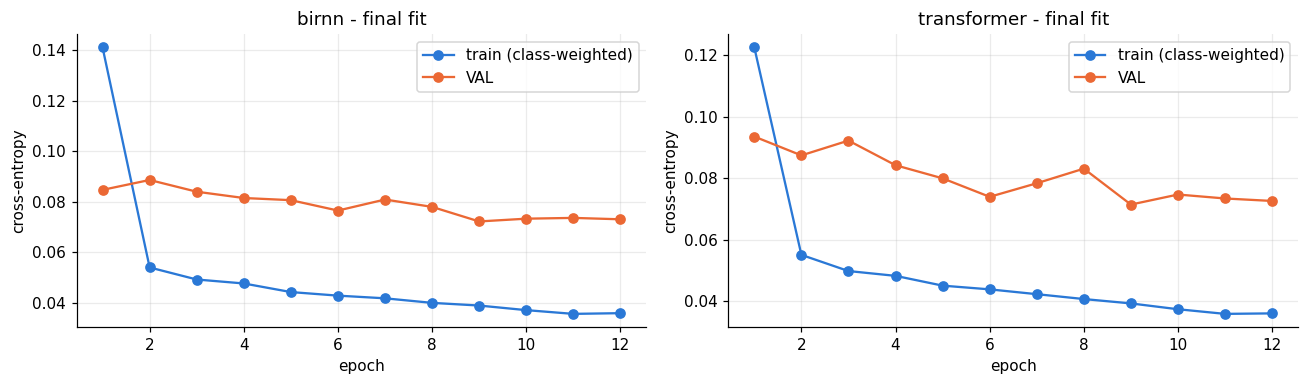

[after sequence models] RAM 7,174 MB (system avail 6,734 MB) | VRAM 574 MB


In [ ]:
if USE_SEQ:
    import iomt_torch_models as tm
    importlib.reload(tm)
    # normalisation statistics from FIT packets only (arcsinh space)
    _rows = np.sort(np.random.default_rng(RANDOM_STATE).choice(
        META_fit["__seqrow__"].to_numpy(), size=min(200_000, len(META_fit)), replace=False))
    _A = np.arcsinh(np.asarray(SEQ_STORE[_rows], dtype=np.float64))
    SEQ_MU, SEQ_SD = _A.mean(0).astype(np.float32), _A.std(0).astype(np.float32)
    SEQ_SD[SEQ_SD < 1e-6] = 1.0
    del _A, _rows
    _es = np.random.default_rng(RANDOM_STATE + 1)
    VAL_ES_IDX = np.sort(_es.choice(len(y_val), size=min(200_000, len(y_val)), replace=False))   # early-stopping subset

    def fit_seq_model(name, params, fit_idx, epochs, samples_per_epoch, ckpt_path=None, ckpt_key=None):
        p = dict(params); scheme = p.pop("class_weighting", "none"); lr = p.pop("lr"); wd = p.pop("weight_decay")
        seed_everything(RANDOM_STATE)
        net = tm.build_model(name, p, F_SEQ, K, SEQ_MU, SEQ_SD)
        y_tr = y_fit[fit_idx]
        cw = class_weight_vector(y_tr, w_fit[fit_idx], scheme)
        train_ds = WindowDataset(META_fit["__seqrow__"].to_numpy()[fit_idx], y_tr)
        val_ds = WindowDataset(META_val["__seqrow__"].to_numpy()[VAL_ES_IDX], y_val[VAL_ES_IDX])
        loader_fn = lambda e: make_loader(train_ds, SEQ_BATCH, True, seed=RANDOM_STATE + e, num_samples=samples_per_epoch)
        val_loader = make_loader(val_ds, SEQ_BATCH * 4, False)
        net, info = tm.train_sequence_model(net, loader_fn, val_loader, cw, TORCH_DEVICE, epochs, lr, wd, SEQ_PATIENCE,
                                            USE_AMP and HAS_CUDA, ckpt_path=ckpt_path, ckpt_key=ckpt_key)
        pred = tm.TorchSequencePredictor(name, p, F_SEQ, K, SEQ_MU, SEQ_SD,
                                         {k: v.detach().cpu() for k, v in net.state_dict().items()}, device=TORCH_DEVICE)
        del net; free_memory()
        return pred, info

    print(f"Sequence models on {TORCH_DEVICE} (AMP {'on' if USE_AMP and HAS_CUDA else 'off'}) | window {CONTEXT_N} x {F_SEQ}")
    print("\nBidirectional RNN (LSTM / GRU):")
    run_search("birnn"); final_fit("birnn")
    print("\nPacket-sequence Transformer:")
    run_search("transformer"); final_fit("transformer")

    hist = {n: FINAL[n]["meta"].get("history") for n in SEQ_MODELS if n in FINAL and FINAL[n]["meta"].get("history")}
    if hist:
        fig, axes = plt.subplots(1, len(hist), figsize=(6 * len(hist), 3.6), squeeze=False)
        for ax, (n, h) in zip(axes[0], hist.items()):
            h = pd.DataFrame(h)
            ax.plot(h.epoch + 1, h.train_loss, "o-", label="train (class-weighted)", color=SERIES_COLORS[0])
            ax.plot(h.epoch + 1, h.val_loss, "o-", label="VAL", color=SERIES_COLORS[1])
            ax.set_title(f"{n} - final fit"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.legend()
        fig.tight_layout(); save_fig(fig, "sequence_training_curves")
    print(mem_status("after sequence models"))
else:
    print("Sequence models skipped (PyTorch unavailable or not in MODELS_TO_RUN).")

## 14. Multi-criteria model selection framework
A model is **not** selected on F1 alone. Every final model is measured on three axes:

1. **Predictive quality (VAL, variant level):** macro-F1, worst-class recall, benign false-alarm rate.
2. **Inference latency (CPU, the portable deployment target):** single-packet p50/p95 (ms), 1,000-packet batch p50/p95
   (ms) and throughput (packets/s).
3. **Resource footprint:** peak RAM while loading the model and predicting a 10k batch (MB above an identical
   imports-only baseline), peak training VRAM, peak GPU inference VRAM (sequence models), and size on disk.

Latency and memory are measured in a **fresh subprocess per model**: every model gets a clean interpreter and the same
thread count, the model is loaded from its saved artifact (as at deployment), and the imports-only baseline is
subtracted. In-process numbers would be polluted by everything else the notebook holds.

$$\text{Score} = w_1\cdot\text{MacroF1}_{\text{VAL}} + w_2\left(1-\frac{\text{Latency}}{\text{Latency}_{\max}}\right) + w_3\left(1-\frac{\text{Memory}}{\text{Memory}_{\max}}\right),\quad (w_1,w_2,w_3)=(0.6,0.2,0.2)$$

The maxima are taken over the candidate models (the prior baseline is benchmarked but never selected). Latency =
`LATENCY_METRIC` (default: p95 of a 1,000-packet batch) and Memory = `MEMORY_METRIC` (default: peak model RAM). The
highest score wins (ties: macro-F1, then worst-class recall). **`MANUAL_SELECTION`** in §3 overrides the winner. The
full table is repeated in §20.

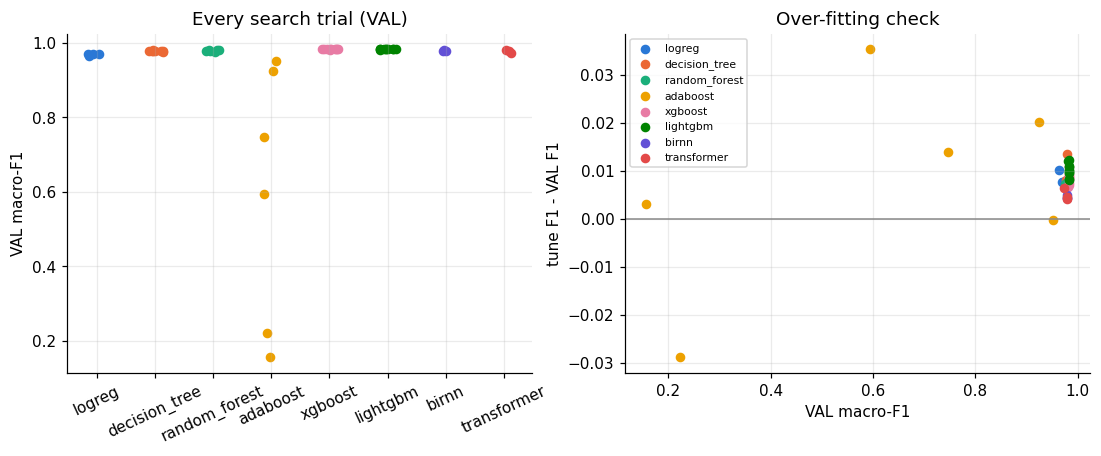

,kind,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,val_dos_ddos_swap_rate,batch1k_p95_ms,single_p95_ms,throughput_pps,peak_ram_mb,peak_train_vram_mb,disk_mb,f1_term,latency_term,memory_term,composite_score
model,,,,,,,,,,,,,,,
decision_tree,tabular,0.9806,0.8936,0.0016,0.0227,3.5928,3.6268,812165.8547,17.0000,0.0,0.106,0.5884,0.1966,0.1949,0.9798
logreg,tabular,0.9701,0.8859,0.0010,0.0379,15.9943,5.6214,301698.8876,27.4609,0.0,0.011,0.5821,0.1848,0.1917,0.9586
adaboost,tabular,0.9652,0.8839,0.0022,0.0359,39.9130,37.2856,71853.6133,20.6680,0.0,0.074,0.5791,0.1620,0.1938,0.9349
xgboost,tabular,0.9831,0.8983,0.0001,0.0209,102.2531,6.8013,8271.4272,123.3945,968.0,7.968,0.5898,0.1026,0.1629,0.8553
lightgbm,tabular,0.9830,0.8982,0.0000,0.0210,140.3039,4.6899,8341.0283,55.5938,0.0,7.739,0.5898,0.0663,0.1833,0.8394
birnn,sequence,0.9821,0.8949,0.0000,0.0224,165.9882,24.5032,5975.3823,310.4844,310.0,0.463,0.5893,0.0419,0.1065,0.7377
random_forest,tabular,0.9825,0.8945,0.0007,0.0214,83.1399,59.7428,52568.3998,664.4688,0.0,59.146,0.5895,0.1208,0.0000,0.7103
transformer,sequence,0.9823,0.8941,0.0000,0.0222,209.9451,1.8318,4355.9324,359.1797,584.0,1.073,0.5894,0.0000,0.0919,0.6813
dummy,tabular,0.0033,0.0000,1.0000,0.0234,3.3855,2.9523,866510.8045,14.8477,0.0,0.002,NaN,NaN,NaN,NaN


Composite winner: decision_tree | SELECTED = decision_tree (composite) | weights {'macro_f1': 0.6, 'latency': 0.2, 'memory': 0.2} | latency = batch1k_p95_ms, memory = peak_ram_mb


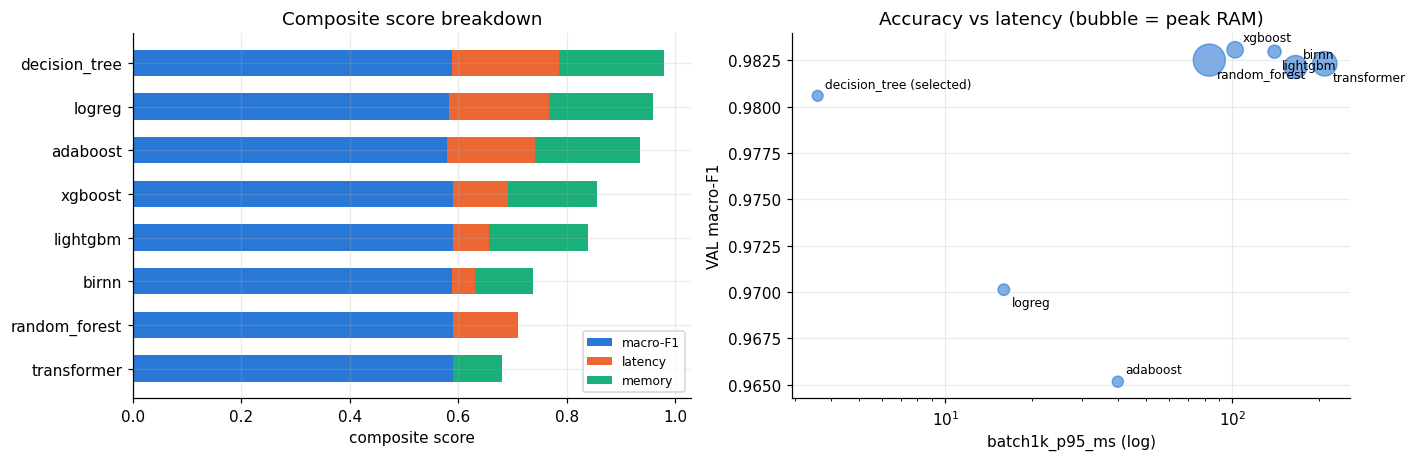

In [ ]:
# ---- tuning overview ----
trials = load_trials()
if len(trials):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    names_t = [m for m in MODELS_TO_RUN if m in set(trials["model"])]
    for i, m in enumerate(names_t):
        t = trials[trials["model"] == m]
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(t))
        axes[0].scatter(np.full(len(t), i) + jitter, t["val_macro_f1"], s=28, color=SERIES_COLORS[i % 9], label=m)
        axes[1].scatter(t["val_macro_f1"], t["overfit_gap_macro_f1"], s=28, color=SERIES_COLORS[i % 9], label=m)
    axes[0].set_xticks(range(len(names_t)), names_t, rotation=25); axes[0].set_ylabel("VAL macro-F1")
    axes[0].set_title("Every search trial (VAL)")
    axes[1].set_xlabel("VAL macro-F1"); axes[1].set_ylabel("tune F1 - VAL F1"); axes[1].legend(fontsize=7)
    axes[1].set_title("Over-fitting check"); axes[1].axhline(0, color="#888", lw=1)
    save_fig(fig, "tuning_trials")

# ---- benchmark harness: one clean subprocess per model ----
BENCH_SCRIPT = os.path.join(DIRS["bench"], "bench_model.py")
with open(BENCH_SCRIPT, "w") as f:
    f.write(r"""
import argparse, json, os, sys, time, threading
ap = argparse.ArgumentParser()
ap.add_argument("--kind"); ap.add_argument("--model", default=""); ap.add_argument("--input")
ap.add_argument("--repeats", type=int); ap.add_argument("--threads", type=int); ap.add_argument("--device", default="cpu")
ap.add_argument("--module-dir"); ap.add_argument("--baseline", action="store_true")
a = ap.parse_args()
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[v] = str(a.threads)
if a.device == "cpu":
    os.environ["CUDA_VISIBLE_DEVICES"] = ""
sys.path.insert(0, a.module_dir)
import numpy as np, psutil
proc = psutil.Process(); peak = [proc.memory_info().rss]; stop = threading.Event()
def sampler():
    while not stop.is_set():
        peak[0] = max(peak[0], proc.memory_info().rss); stop.wait(0.002)
th = threading.Thread(target=sampler, daemon=True); th.start()
if a.kind == "tabular":
    import joblib, pandas as pd, sklearn, xgboost, iomt_runtime
    try:
        import lightgbm
    except Exception:
        pass
    X = pd.read_parquet(a.input)
    take = lambda i, j: X.iloc[i:j]
else:
    import torch, iomt_torch_models as tm, iomt_runtime
    torch.set_num_threads(a.threads)
    X = np.load(a.input)
    take = lambda i, j: X[i:j]
base = proc.memory_info().rss
out = {"baseline_rss_mb": base / 2**20}
if not a.baseline:
    t0 = time.perf_counter()
    if a.kind == "tabular":
        model = joblib.load(a.model); f = model.predict_proba
    else:
        model = tm.TorchSequencePredictor.load(a.model, device=a.device); f = model.predict_proba
    out["load_ms"] = (time.perf_counter() - t0) * 1e3
    n = len(X); f(take(0, 1)); f(take(0, min(1000, n)))                    # warm-up
    if a.device != "cpu":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    lat = []
    for r in range(a.repeats):
        i = (r * 37) % n; t0 = time.perf_counter(); f(take(i, i + 1)); lat.append((time.perf_counter() - t0) * 1e3)
    bl = []
    for r in range(max(10, a.repeats // 10)):
        i = (r * 997) % max(1, n - 1000); t0 = time.perf_counter(); f(take(i, i + 1000)); bl.append((time.perf_counter() - t0) * 1e3)
    t0 = time.perf_counter(); f(take(0, n)); tput = n / (time.perf_counter() - t0)
    out.update(single_p50_ms=float(np.percentile(lat, 50)), single_p95_ms=float(np.percentile(lat, 95)),
               batch1k_p50_ms=float(np.percentile(bl, 50)), batch1k_p95_ms=float(np.percentile(bl, 95)),
               throughput_pps=float(tput))
    if a.device != "cpu":
        out["peak_infer_vram_mb"] = torch.cuda.max_memory_allocated() / 2**20
stop.set(); th.join()
out["peak_rss_mb"] = max(peak[0], proc.memory_info().rss) / 2**20
print("BENCH_JSON " + json.dumps(out))
""")

BENCH_TAB_INPUT = os.path.join(DIRS["bench"], "bench_input_tabular.parquet")
_bidx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(y_val), size=min(BENCH_ROWS, len(y_val)), replace=False))
pd.DataFrame(X_val[_bidx], columns=FEATURES).to_parquet(BENCH_TAB_INPUT, index=False)
BENCH_SEQ_INPUT = os.path.join(DIRS["bench"], "bench_input_windows.npy")
if USE_SEQ:
    np.save(BENCH_SEQ_INPUT, get_windows(META_val["__seqrow__"].to_numpy()[_bidx]))

def _run_bench(kind, model_path="", device="cpu", baseline=False):
    cmd = [sys.executable, BENCH_SCRIPT, "--kind", kind, "--input", BENCH_TAB_INPUT if kind == "tabular" else BENCH_SEQ_INPUT,
           "--repeats", str(BENCH_REPEATS), "--threads", str(N_JOBS), "--device", device, "--module-dir", RUNTIME_DIR]
    cmd += ["--baseline"] if baseline else ["--model", model_path]
    res = subprocess.run(cmd, capture_output=True, text=True, timeout=3600)
    line = [l for l in res.stdout.splitlines() if l.startswith("BENCH_JSON ")]
    if res.returncode != 0 or not line:
        raise RuntimeError(f"benchmark failed for {model_path or kind}:\n{res.stderr[-2000:]}")
    return json.loads(line[-1][len("BENCH_JSON "):])

BENCH_BASELINE = {k: _run_bench(k, baseline=True) for k in ({"tabular", "sequence"} if USE_SEQ else {"tabular"})}
BENCH = {}
for name, fm in FINAL.items():
    mdir, art = model_artifact(name)
    bkey = json.dumps({"model": fm["meta"]["key"], "repeats": BENCH_REPEATS, "rows": BENCH_ROWS, "threads": N_JOBS,
                       "hw": HARDWARE}, sort_keys=True)
    bpath = os.path.join(mdir, "bench.json")
    if os.path.exists(bpath) and json.load(open(bpath)).get("bkey") == bkey:
        BENCH[name] = json.load(open(bpath)); continue
    kind = MODEL_KIND[name]
    r = _run_bench(kind, art, "cpu")
    r["peak_ram_mb"] = max(1.0, r["peak_rss_mb"] - BENCH_BASELINE[kind]["peak_rss_mb"])
    r["peak_infer_vram_mb"] = 0.0
    if kind == "sequence" and HAS_CUDA:
        g = _run_bench(kind, art, "cuda")
        r.update(gpu_single_p50_ms=g["single_p50_ms"], gpu_batch1k_p50_ms=g["batch1k_p50_ms"],
                 peak_infer_vram_mb=g.get("peak_infer_vram_mb", 0.0))
    r["bkey"] = bkey
    with open(bpath, "w") as f:
        json.dump(r, f, indent=2)
    BENCH[name] = r
    print(f"  benchmarked {name:<14} single p50 {r['single_p50_ms']:.2f} ms | 1k-batch p95 {r['batch1k_p95_ms']:.1f} ms "
          f"| {r['throughput_pps']:,.0f} pkt/s | RAM {r['peak_ram_mb']:,.0f} MB")

# ---- assemble the multi-criteria table ----
rows = []
for name, fm in FINAL.items():
    m, v, b = fm["meta"], fm["meta"]["val"], BENCH[name]
    rows.append({"model": name, "kind": MODEL_KIND[name], "val_macro_f1": v["macro_f1"],
                 "val_min_class_recall": v["min_class_recall"], "val_worst_class": v["worst_class"],
                 "val_benign_false_alarm_rate": v.get("benign_false_alarm_rate"), "val_ece_raw": v["ece"],
                 "val_dos_ddos_swap_rate": v.get("dos_ddos_swap_rate", np.nan),
                 "single_p50_ms": b["single_p50_ms"], "single_p95_ms": b["single_p95_ms"],
                 "batch1k_p50_ms": b["batch1k_p50_ms"], "batch1k_p95_ms": b["batch1k_p95_ms"],
                 "throughput_pps": b["throughput_pps"], "peak_ram_mb": b["peak_ram_mb"],
                 "peak_infer_vram_mb": b.get("peak_infer_vram_mb", 0.0), "peak_train_vram_mb": m["peak_train_vram_mb"],
                 "peak_train_ram_mb": m["peak_train_ram_mb"], "disk_mb": m["disk_mb"], "fit_seconds": m["fit_seconds"],
                 "fit_macro_f1": m["fit"]["macro_f1"]})
SELECTION = pd.DataFrame(rows).set_index("model")

def composite_scores(table, weights=SCORE_WEIGHTS, lat_col=LATENCY_METRIC, mem_col=MEMORY_METRIC):
    cand = table.drop(index=[i for i in table.index if i == "dummy"])
    lat, mem = cand[lat_col].clip(lower=1e-9), cand[mem_col].clip(lower=1e-9)
    out = pd.DataFrame({"f1_term": weights["macro_f1"] * cand["val_macro_f1"],
                        "latency_term": weights["latency"] * (1 - lat / lat.max()),
                        "memory_term": weights["memory"] * (1 - mem / mem.max())})
    out["composite_score"] = out.sum(axis=1)
    return out
SCORES = composite_scores(SELECTION)
SELECTION = SELECTION.join(SCORES)
SELECTION = SELECTION.sort_values(["composite_score", "val_macro_f1", "val_min_class_recall"], ascending=False, na_position="last")
SELECTION["rank"] = SELECTION["composite_score"].rank(ascending=False, method="first")
AUTO_SELECTED = SCORES.sort_values(["composite_score"], ascending=False).index[0]
if MANUAL_SELECTION:
    if MANUAL_SELECTION not in FINAL or MANUAL_SELECTION == "dummy":
        raise ValueError(f"MANUAL_SELECTION={MANUAL_SELECTION!r} is not a trained model. Options: "
                         f"{[n for n in FINAL if n != 'dummy']}")
    SELECTED, SELECTION_MODE = MANUAL_SELECTION, "manual"
else:
    SELECTED, SELECTION_MODE = AUTO_SELECTED, "composite"
SELECTION.to_csv(os.path.join(DIRS["reports"], "model_selection_multicriteria.csv"))
show_cols = ["kind", "val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate", "val_dos_ddos_swap_rate",
             LATENCY_METRIC,
             "single_p95_ms", "throughput_pps", "peak_ram_mb", "peak_train_vram_mb", "disk_mb",
             "f1_term", "latency_term", "memory_term", "composite_score"]
display(SELECTION[show_cols].round(4))
print(f"Composite winner: {AUTO_SELECTED} | SELECTED = {SELECTED} ({SELECTION_MODE}) | weights {SCORE_WEIGHTS} | "
      f"latency = {LATENCY_METRIC}, memory = {MEMORY_METRIC}")

# ---- plots: score breakdown and the F1 / latency / memory trade-off ----
cand = SELECTION.dropna(subset=["composite_score"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
left = np.zeros(len(cand))
for i, (col, lab) in enumerate([("f1_term", "macro-F1"), ("latency_term", "latency"), ("memory_term", "memory")]):
    axes[0].barh(cand.index, cand[col], left=left, color=SERIES_COLORS[i], label=lab, height=0.6); left += cand[col].to_numpy()
axes[0].invert_yaxis(); axes[0].set_xlabel("composite score"); axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Composite score breakdown")
sz = 40 + 400 * cand["peak_ram_mb"] / cand["peak_ram_mb"].max()
axes[1].scatter(cand[LATENCY_METRIC], cand["val_macro_f1"], s=sz, color=SERIES_COLORS[0], alpha=0.6)
for k, (n, r) in enumerate(cand.sort_values(LATENCY_METRIC).iterrows()):
    axes[1].annotate(n + (" (selected)" if n == SELECTED else ""), (r[LATENCY_METRIC], r["val_macro_f1"]), fontsize=8,
                     xytext=(5, 6 if k % 2 == 0 else -11), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel(f"{LATENCY_METRIC} (log)"); axes[1].set_ylabel("VAL macro-F1")
axes[1].set_title("Accuracy vs latency (bubble = peak RAM)")
fig.tight_layout(); save_fig(fig, "model_selection_tradeoff")

## 15. Post-hoc probability calibration
The Controller routes on confidence, so the selected model gets a **Platt-scaling** calibrator
(`CalibratedClassifierCV(method="sigmoid")`) fitted on **VAL only**. To work identically for tabular and sequence
models, the calibrator operates on the model's probability vector: a pass-through estimator exposes log-probabilities
as its decision function, and a sigmoid is fitted per class (one-vs-rest), then renormalised.

VAL is also used for early stopping and selection, so an ECE measured on the same VAL rows would flatter the
calibrator. The reliability diagram below is therefore **cross-fitted**: the calibrator is fitted on one half of each
capture's VAL block and scored on the other half, both ways. The final calibrator is fitted on all of VAL. Its TEST
calibration is reported in §16.

Calibrator reloaded


,raw,calibrated (cross-fitted)
ece,0.012828,0.0104
log_loss,0.137347,0.101992
brier,0.036497,0.036705
macro_f1,0.980585,0.980824
accuracy,0.977128,0.977209


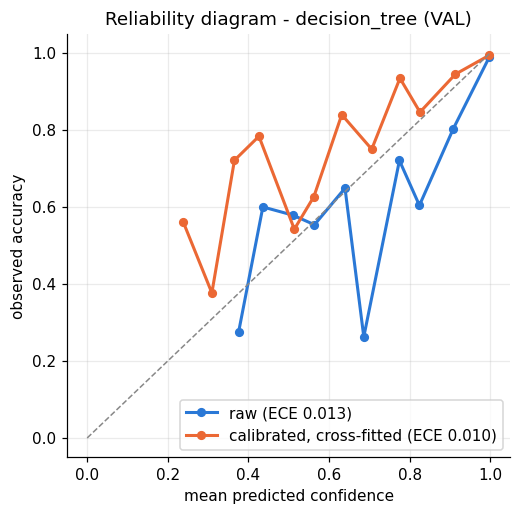

In [ ]:
def make_calibrator():
    base = rt.ProbaPassthrough(n_classes=K).fit()
    if FrozenEstimator is not None:
        return CalibratedClassifierCV(FrozenEstimator(base), method=CALIBRATION_METHOD)
    return CalibratedClassifierCV(base, method=CALIBRATION_METHOD, cv="prefit")

def fit_calibrator(P, y, w):
    cal = make_calibrator()
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=".*does not appear to accept sample_weight.*")
        warnings.filterwarnings("ignore", message=".*FrozenEstimator.*")
        cal.fit(P, y, sample_weight=w)
    return cal

SEL_MODEL = FINAL[SELECTED]["model"]
P_VAL_SEL = proba_of(SELECTED, SEL_MODEL, "val")

# cross-fitted (honest) VAL calibration estimate: halves split by packet order inside each capture
_half = (META_val.groupby("__file__", observed=True)["__pkt__"].rank(pct=True) > 0.5).to_numpy()
P_VAL_XFIT = np.zeros_like(P_VAL_SEL)
for hold in (False, True):
    tr, te = _half != hold, _half == hold
    if tr.sum() and te.sum() and len(np.unique(y_val[tr])) == K:
        P_VAL_XFIT[te] = fit_calibrator(P_VAL_SEL[tr], y_val[tr], w_val[tr]).predict_proba(P_VAL_SEL[te])
    else:
        P_VAL_XFIT[te] = P_VAL_SEL[te]

cal_path = os.path.join(DIRS["models"], SELECTED, f"calibrator_{CALIBRATION_METHOD}.joblib")
cal_key = FINAL[SELECTED]["meta"]["key"] + "|" + CALIBRATION_METHOD
if os.path.exists(cal_path) and joblib.load(cal_path)["key"] == cal_key:
    CALIBRATOR = joblib.load(cal_path)["calibrator"]; print("Calibrator reloaded")
else:
    CALIBRATOR = fit_calibrator(P_VAL_SEL, y_val, w_val)
    joblib.dump({"key": cal_key, "calibrator": CALIBRATOR}, cal_path, compress=3)
    print(f"Calibrator ({CALIBRATION_METHOD}) fitted on VAL ({len(y_val):,} packets) and saved")

CAL_VAL = {"raw": evaluate(y_val, P_VAL_SEL, w_val, TRAIN_CLASSES)["summary"],
           "calibrated (cross-fitted)": evaluate(y_val, P_VAL_XFIT, w_val, TRAIN_CLASSES)["summary"]}
display(pd.DataFrame(CAL_VAL).loc[["ece", "log_loss", "brier", "macro_f1", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(5.2, 5))
for i, (lab, p) in enumerate([("raw", P_VAL_SEL), ("calibrated, cross-fitted", P_VAL_XFIT)]):
    e, (W, acc, cf) = ece_top_label(y_val, p, w_val); m = W > 0
    ax.plot(cf[m] / W[m], acc[m] / W[m], "o-", ms=5, lw=2, color=SERIES_COLORS[i], label=f"{lab} (ECE {e:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#888", lw=1)
ax.set_xlabel("mean predicted confidence"); ax.set_ylabel("observed accuracy")
ax.set_title(f"Reliability diagram - {SELECTED} (VAL)"); ax.legend()
save_fig(fig, f"reliability_val_{SELECTED}")

## 16. Final evaluation on held-out test PCAPs
Run **once**, after every decision above was made on VAL. All models are scored so the comparison is complete, but the
**selected, calibrated** model is the headline result. Metrics are reported at all four label levels: accuracy,
balanced accuracy, macro/weighted F1, worst-class recall, ROC-AUC, benign false-alarm rate, attacks missed as benign,
log-loss, Brier score and ECE. TEST keeps the class proportions of the extracted captures (no rebalancing).

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


TEST - variant level (13 classes):


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,min_class_recall,worst_class,roc_auc_ovr_macro,benign_false_alarm_rate,attack_missed_as_benign_rate,log_loss,brier,ece,dos_ddos_swap_rate,n_classes_never_predicted
model,,,,,,,,,,,,,,,,
dummy,0.0645,0.0769,0.0050,0.0769,0.0093,0.0078,0.0000,Benign,0.5000,1.0000,0.0000,2.5650,0.9231,0.0126,0.0652,12
logreg,0.9153,0.9122,0.9319,0.9122,0.8908,0.9023,0.1200,MQTT-DDoS-Publish,0.9885,0.0027,0.0015,0.5611,0.1632,0.0717,0.0847,0
decision_tree,0.9084,0.8994,0.9327,0.8994,0.8835,0.8941,0.1157,MQTT-DDoS-Publish,0.9876,0.0017,0.0015,0.9172,0.1619,0.0722,0.0919,0
random_forest,0.9054,0.8966,0.9349,0.8966,0.8810,0.8904,0.1128,MQTT-DDoS-Publish,0.9714,0.0004,0.0015,1.5890,0.1611,0.0606,0.0955,0
adaboost,0.9146,0.9089,0.9296,0.9089,0.8886,0.9005,0.1021,MQTT-DDoS-Publish,0.9847,0.0023,0.0014,2.5544,0.9215,0.8368,0.0849,0
xgboost,0.9069,0.8977,0.9367,0.8977,0.8838,0.8927,0.1307,MQTT-DDoS-Publish,0.9784,0.0002,0.0012,0.6506,0.1600,0.0655,0.0944,0
lightgbm,0.9053,0.8958,0.9359,0.8958,0.8812,0.8903,0.1185,MQTT-DDoS-Publish,0.9724,0.0001,0.0013,0.6127,0.1640,0.0682,0.0960,0
birnn,0.9089,0.9028,0.9341,0.9028,0.8856,0.8954,0.1234,MQTT-DDoS-Publish,0.9766,0.0002,0.0014,0.7329,0.1627,0.0653,0.0921,0
transformer,0.9032,0.8971,0.9300,0.8971,0.8799,0.8891,0.1183,MQTT-DDoS-Publish,0.9500,0.0001,0.0015,0.8086,0.1674,0.0660,0.0978,0



subtype level:


,accuracy,balanced_accuracy,macro_f1,weighted_f1,min_class_recall,benign_false_alarm_rate,log_loss,brier,ece
model,,,,,,,,,
dummy,0.0983,0.1429,0.0256,0.0176,0.0000,1.0000,1.8917,0.8446,0.0557
logreg,0.9977,0.9972,0.9945,0.9977,0.9947,0.0027,0.0188,0.0044,0.0009
decision_tree,0.9977,0.9975,0.9947,0.9978,0.9948,0.0017,0.0393,0.0042,0.0018
random_forest,0.9983,0.9983,0.9955,0.9983,0.9953,0.0004,0.0219,0.0033,0.0010
adaboost,0.9682,0.8530,0.8400,0.9545,0.0000,1.0000,1.8825,0.8419,0.8130
xgboost,0.9986,0.9986,0.9963,0.9986,0.9957,0.0002,0.0080,0.0025,0.0008
lightgbm,0.9985,0.9985,0.9960,0.9985,0.9957,0.0001,0.0090,0.0027,0.0002
birnn,0.9984,0.9984,0.9958,0.9984,0.9952,0.0002,0.0096,0.0029,0.0012
transformer,0.9982,0.9983,0.9954,0.9982,0.9951,0.0001,0.0113,0.0033,0.0012



family level:


... (9 outputs left out)


=== decision_tree+calibrated - TEST classification report (binary) ===


,precision,recall,f1,support,fpr_ovr,predicted
Benign,0.9533,0.9909,0.9717,36960.0,0.0014,38416.0
Attack,0.9997,0.9986,0.9992,1262684.0,0.0091,1261228.0



=== decision_tree+calibrated - DoS vs DDoS per protocol on TEST (wrong-scale shares) ===


,pair,dos_support,ddos_support,dos_as_ddos,ddos_as_dos,swap_rate
0,DoS-SYN / DDoS-SYN,97732.0,96919.0,0.0083,0.0571,0.0326
1,DoS-TCP / DDoS-TCP,96464.0,97429.0,0.0097,0.0006,0.0051
2,DoS-UDP / DDoS-UDP,95821.0,194788.0,0.0024,0.0670,0.0457
3,DoS-ICMP / DDoS-ICMP,96819.0,192730.0,0.5638,0.0035,0.1908
4,MQTT-DoS-Connect / MQTT-DDoS-Connect,30529.0,97273.0,0.0004,0.0001,0.0002
5,MQTT-DoS-Publish / MQTT-DDoS-Publish,83832.0,82348.0,0.0003,0.8793,0.4359


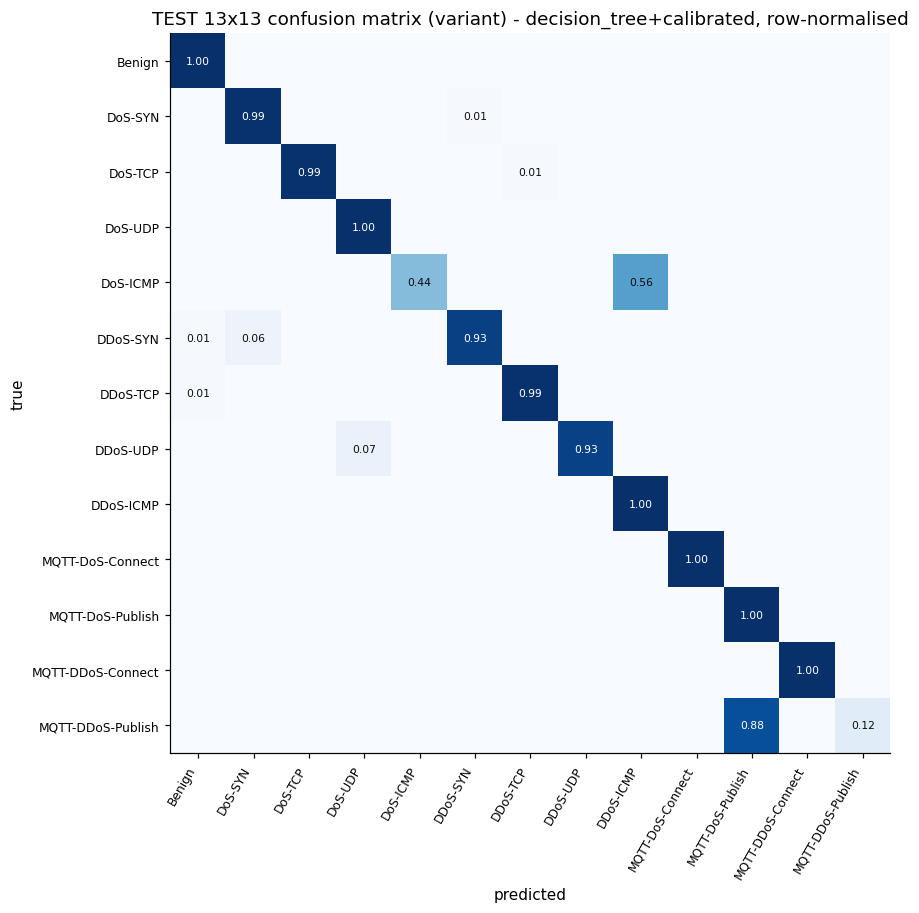

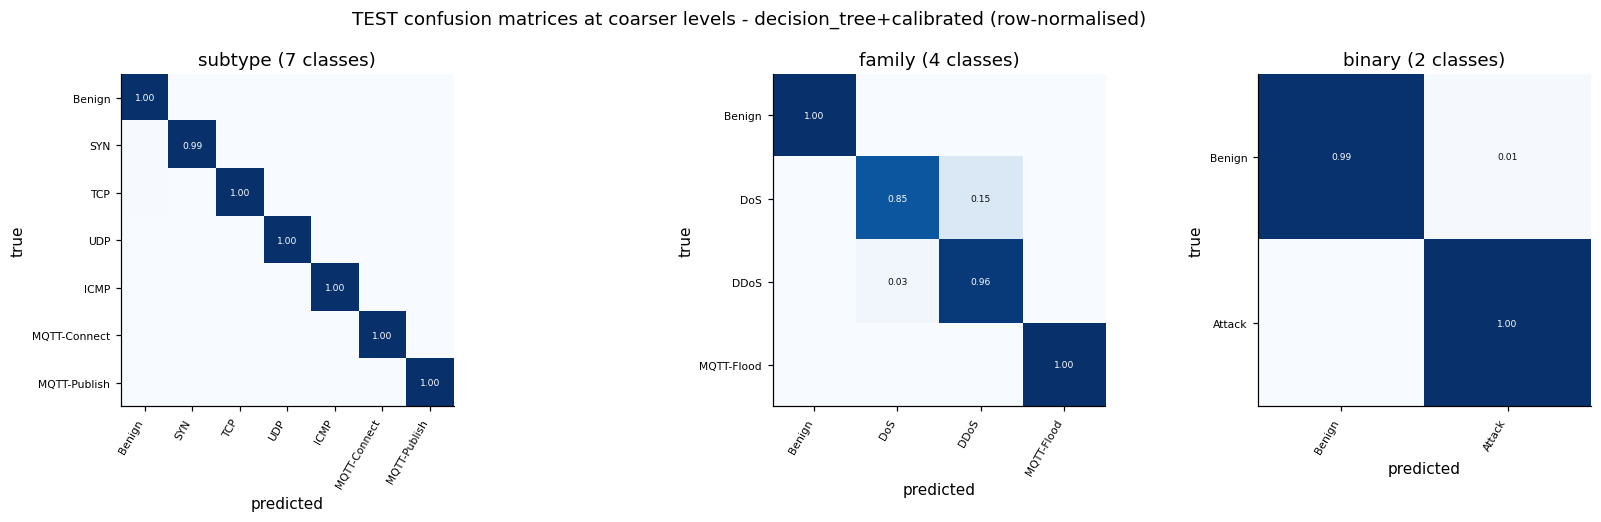

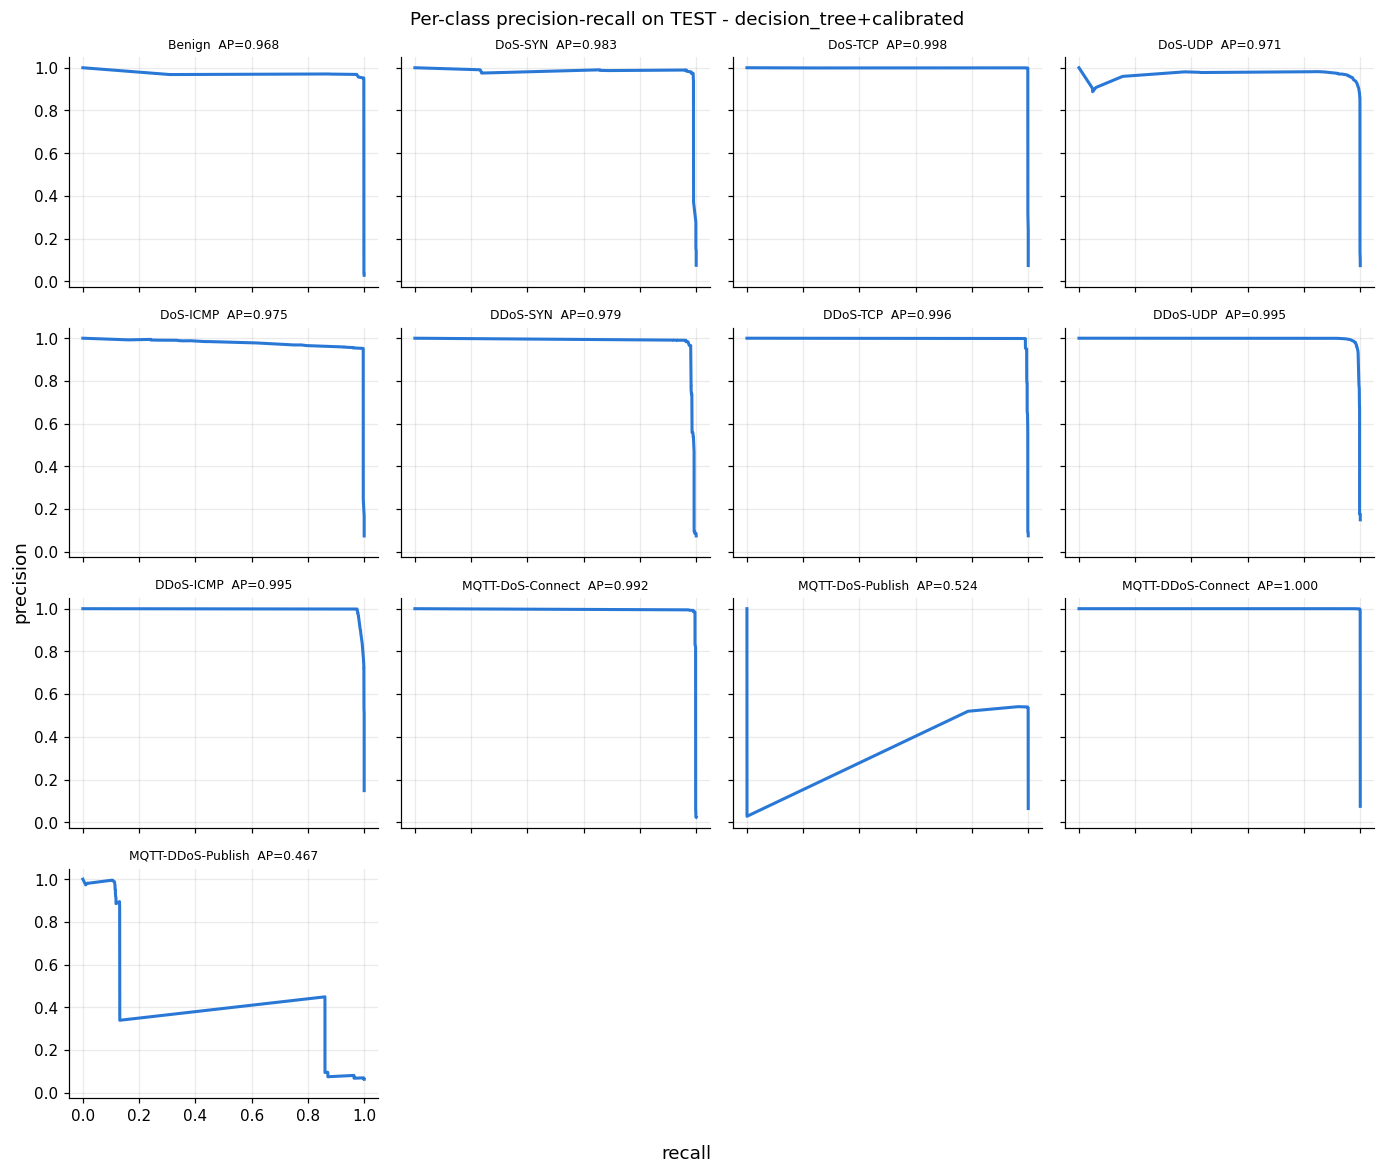

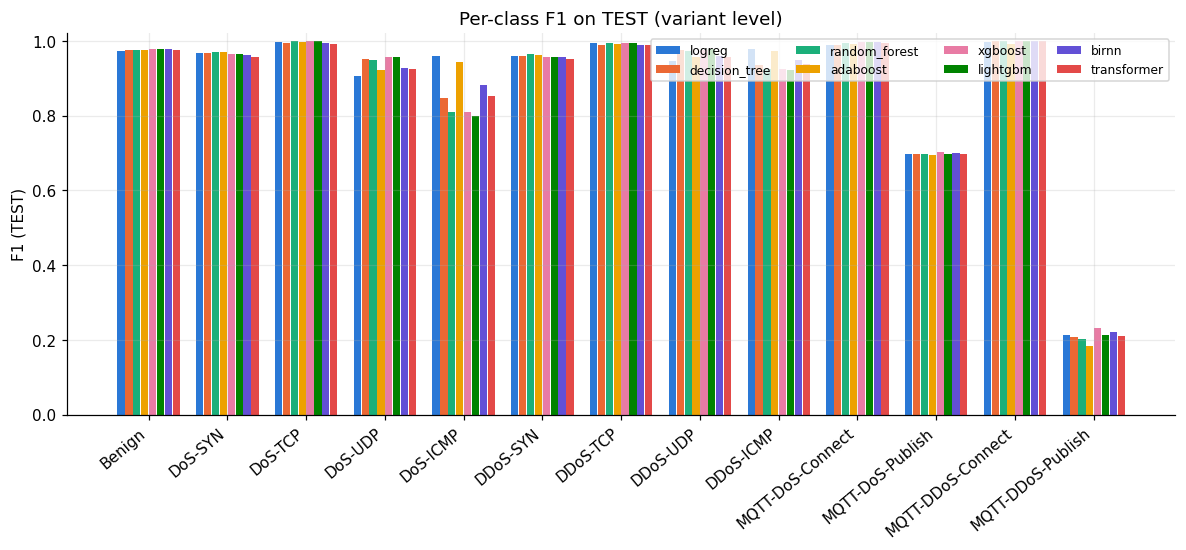

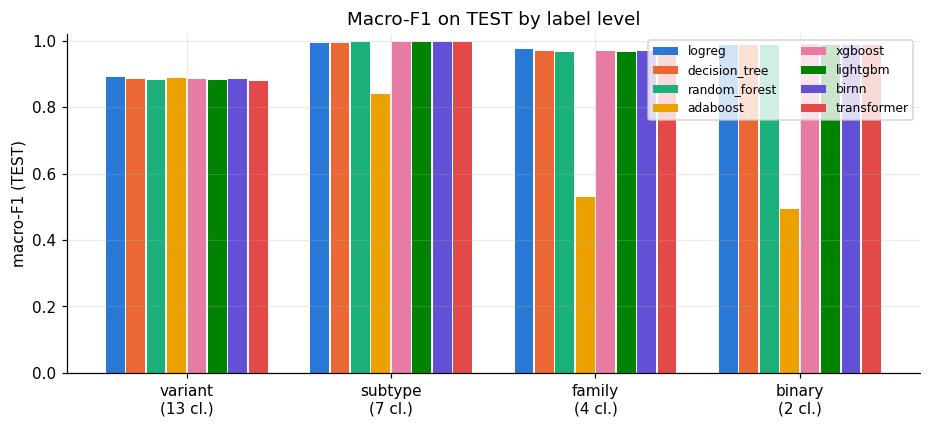

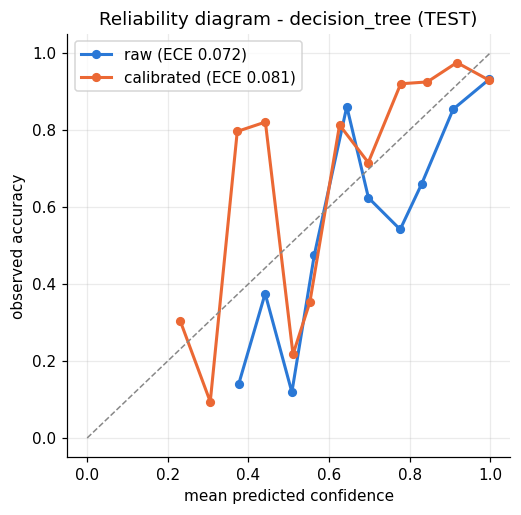

In [ ]:
TEST_RESULTS, TEST_PROBA = {}, {}
for name, f in FINAL.items():
    mem_guard(f"test {name}")
    t0 = time.time(); p = proba_of(name, f["model"], "test"); secs = time.time() - t0
    TEST_RESULTS[name] = evaluate_levels(y_test, p, w_test)
    TEST_RESULTS[name]["_predict_seconds"] = secs
    if name == SELECTED:
        TEST_PROBA["raw"] = p
    del p; free_memory()
TEST_PROBA["calibrated"] = CALIBRATOR.predict_proba(TEST_PROBA["raw"])
SEL_CAL = f"{SELECTED}+calibrated"
TEST_RESULTS[SEL_CAL] = evaluate_levels(y_test, TEST_PROBA["calibrated"], w_test)

cols = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "min_class_recall",
        "worst_class", "roc_auc_ovr_macro", "benign_false_alarm_rate", "attack_missed_as_benign_rate", "log_loss", "brier",
        "ece", "dos_ddos_swap_rate", "n_classes_never_predicted"]
TEST_TABLE = pd.DataFrame([{"model": n, "level": lv, **{c: r[lv]["summary"].get(c) for c in cols}}
                           for n, r in TEST_RESULTS.items() for lv in EVAL_LEVELS]).set_index(["level", "model"])
TEST_TABLE.to_csv(os.path.join(DIRS["reports"], "test_metrics_all_models.csv"))
print(f"TEST - {TRAIN_LEVEL} level ({K} classes):")
display(TEST_TABLE.loc[TRAIN_LEVEL].round(4))
for lv in list(EVAL_LEVELS)[1:]:
    print(f"\n{lv} level:")
    display(TEST_TABLE.loc[lv][["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "min_class_recall",
                                "benign_false_alarm_rate", "log_loss", "brier", "ece"]].round(4))
with open(os.path.join(DIRS["reports"], "test_results_full.json"), "w") as f:
    json.dump(json_safe({n: {lv: r[lv] for lv in EVAL_LEVELS} for n, r in TEST_RESULTS.items()}), f, default=str)

sel_res = TEST_RESULTS[SEL_CAL]
for lv in EVAL_LEVELS:
    print(f"\n=== {SEL_CAL} - TEST classification report ({lv}) ===")
    display(sel_res[lv]["per_class"].round(4))
    sel_res[lv]["per_class"].to_csv(os.path.join(DIRS["reports"], f"test_per_class_{lv}_{SELECTED}.csv"))

if TRAIN_LEVEL == "variant":
    DOS_DDOS_TEST = dos_ddos_table(sel_res["variant"]["cm"], sel_res["variant"]["names"])
    print(f"\n=== {SEL_CAL} - DoS vs DDoS per protocol on TEST (wrong-scale shares) ===")
    display(DOS_DDOS_TEST.round(4))
    DOS_DDOS_TEST.to_csv(os.path.join(DIRS["reports"], f"test_dos_ddos_{SELECTED}.csv"), index=False)

def plot_cm(ax, cm, names, title, fs=7):
    cmn = cm / np.clip(cm.sum(1, keepdims=True), 1e-12, None)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=fs)
    ax.set_yticks(range(len(names)), names, fontsize=fs)
    for i in range(len(names)):
        for j in range(len(names)):
            if cmn[i, j] >= 0.005:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=fs - 1,
                        color="white" if cmn[i, j] > 0.6 else "#0b0b0b")
    ax.set_title(title); ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)

fig, ax = plt.subplots(figsize=(9.5, 8.5))
plot_cm(ax, sel_res[TRAIN_LEVEL]["cm"], sel_res[TRAIN_LEVEL]["names"],
        f"TEST {K}x{K} confusion matrix ({TRAIN_LEVEL}) - {SEL_CAL}, row-normalised", fs=8)
save_fig(fig, f"confusion_matrix_{TRAIN_LEVEL}_{SELECTED}")
coarse = list(EVAL_LEVELS)[1:]
if coarse:
    fig, axes = plt.subplots(1, len(coarse), figsize=(5.2 * len(coarse), 4.8),
                             gridspec_kw={"width_ratios": [len(EVAL_LEVELS[lv][0]) + 3 for lv in coarse]})
    for ax, lv in zip(np.atleast_1d(axes), coarse):
        plot_cm(ax, sel_res[lv]["cm"], sel_res[lv]["names"], f"{lv} ({len(EVAL_LEVELS[lv][0])} classes)")
    fig.suptitle(f"TEST confusion matrices at coarser levels - {SEL_CAL} (row-normalised)"); fig.tight_layout()
    save_fig(fig, f"confusion_matrices_coarse_{SELECTED}")

# ---- per-class precision-recall curves (calibrated selected model) ----
pc = TEST_PROBA["calibrated"]; ncol = 4; nrow = int(np.ceil(K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.7 * nrow), sharex=True, sharey=True, squeeze=False)
for c, ax in zip(range(K), axes.ravel()):
    yt = (y_test == c).astype(int)
    if yt.sum() == 0:
        ax.set_title(f"{TRAIN_CLASSES[c]} (absent)", fontsize=8); continue
    pr, rc, _ = precision_recall_curve(yt, pc[:, c], sample_weight=w_test)
    ap = average_precision_score(yt, pc[:, c], sample_weight=w_test)
    ax.plot(rc, pr, color=SERIES_COLORS[0], lw=2); ax.set_title(f"{TRAIN_CLASSES[c]}  AP={ap:.3f}", fontsize=8)
for ax in axes.ravel()[K:]:
    ax.axis("off")
fig.supxlabel("recall"); fig.supylabel("precision"); fig.suptitle(f"Per-class precision-recall on TEST - {SEL_CAL}")
fig.tight_layout(); save_fig(fig, f"pr_curves_{SELECTED}")

# ---- per-class F1 and macro-F1 by level across models ----
models_cmp = [n for n in FINAL if n != "dummy"]
f1s = pd.DataFrame({n: TEST_RESULTS[n][TRAIN_LEVEL]["per_class"]["f1"] for n in models_cmp})
fig, ax = plt.subplots(figsize=(13, 4.5)); width = 0.8 / len(models_cmp); xs = np.arange(len(f1s))
for i, n in enumerate(models_cmp):
    ax.bar(xs + i * width - 0.4 + width / 2, f1s[n].fillna(0), width=width * 0.92, label=n, color=SERIES_COLORS[i % 9])
ax.set_xticks(xs, f1s.index, rotation=40, ha="right"); ax.set_ylim(0, 1.02); ax.set_ylabel("F1 (TEST)")
ax.set_title(f"Per-class F1 on TEST ({TRAIN_LEVEL} level)"); ax.legend(ncol=4, fontsize=8)
save_fig(fig, "per_class_f1_models")
fig, ax = plt.subplots(figsize=(10, 4)); lvls = list(EVAL_LEVELS); xs = np.arange(len(lvls))
for i, n in enumerate(models_cmp):
    ax.bar(xs + i * width - 0.4 + width / 2, [TEST_RESULTS[n][lv]["summary"]["macro_f1"] for lv in lvls],
           width=width * 0.92, label=n, color=SERIES_COLORS[i % 9])
ax.set_xticks(xs, [f"{lv}\n({len(EVAL_LEVELS[lv][0])} cl.)" for lv in lvls]); ax.set_ylim(0, 1.02)
ax.set_ylabel("macro-F1 (TEST)"); ax.set_title("Macro-F1 on TEST by label level"); ax.legend(fontsize=8, ncol=2)
save_fig(fig, "macro_f1_by_level")

# ---- reliability on TEST, raw vs calibrated ----
fig, ax = plt.subplots(figsize=(5.2, 5))
for i, (lab, p) in enumerate(TEST_PROBA.items()):
    e, (W, acc, cf) = ece_top_label(y_test, p, w_test); m = W > 0
    ax.plot(cf[m] / W[m], acc[m] / W[m], "o-", ms=5, lw=2, color=SERIES_COLORS[i], label=f"{lab} (ECE {e:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#888", lw=1)
ax.set_xlabel("mean predicted confidence"); ax.set_ylabel("observed accuracy")
ax.set_title(f"Reliability diagram - {SELECTED} (TEST)"); ax.legend()
save_fig(fig, f"reliability_test_{SELECTED}")

## 17. Robustness, feature importance and shortcut ablation
1. **Gap table**: FIT vs VAL vs TEST macro-F1. FIT→VAL measures fit against later traffic of the same captures;
   VAL→TEST measures transfer to unseen capture sessions.
2. **Error analysis**: most frequent confusions, minority-class behaviour, and the achieved error compared with the
   label-conflict floor from §9.
3. **Permutation importance on VAL** (drop in macro-F1 when one feature is shuffled; for sequence models the feature is
   shuffled across windows at every time step), plus model-native importance for tree models.
4. **Shortcut ablation**: the same configuration retrained on (a) clean features, (b) clean features + `timestamp` +
   `packet_no`, (c) `timestamp` + `packet_no` only, on an identical class-stratified sample. If (c) scores far above the
   prior baseline, those columns identify the *capture* rather than the attack.
5. **Leave-capture-out (LCO)**: for classes recorded in several training sessions, one whole session is held out, the
   configuration is retrained without it, and recall on the unseen session is compared with in-capture VAL recall.

6. **DoS↔DDoS before / after**: the ablation model is retrained on one class-stratified sample with (a) header
   features only, (b) header + 20-packet context (the previous design) and (c) the deployed set with the long-horizon
   features, and scored on VAL and TEST: variant / subtype / family macro-F1 and the DoS↔DDoS swap rate, overall and per
   protocol pair. Only the feature set changes between (b) and (c), so the difference is the effect of the fix.

Retraining a deep model several times would cost much more GPU time without telling us more about the *features*. So
(4), (5) and (6) use the selected model when it is tabular, and otherwise the best-scoring tabular model (stated in the
output).

Macro-F1 by partition (variant level):


,FIT (sample),VAL,TEST,FIT-VAL,VAL-TEST (capture shift)
dummy,0.0110,0.0033,0.0093,0.0076,-0.0060
logreg,0.9782,0.9701,0.8908,0.0081,0.0793
decision_tree,0.9874,0.9806,0.8835,0.0068,0.0971
random_forest,0.9905,0.9825,0.8810,0.0080,0.1016
adaboost,0.9710,0.9652,0.8886,0.0059,0.0766
xgboost,0.9910,0.9831,0.8838,0.0080,0.0992
lightgbm,0.9915,0.9830,0.8812,0.0085,0.1018
birnn,0.9863,0.9821,0.8856,0.0042,0.0965
transformer,0.9865,0.9823,0.8799,0.0042,0.1024


7 of the 10 most frequent confusions are DoS<->DDoS of the same protocol | overall TEST swap rate 0.1175
Most frequent confusions (TEST, calibrated selected model):


,true,predicted,packets,share_of_true_class,dos_ddos_pair
66,MQTT-DDoS-Publish,MQTT-DoS-Publish,72406,0.8793,True
21,DoS-ICMP,DDoS-ICMP,54584,0.5638,True
38,DDoS-UDP,DoS-UDP,13049,0.0670,True
23,DDoS-SYN,DoS-SYN,5531,0.0571,True
13,DoS-TCP,DDoS-TCP,935,0.0097,True
31,DDoS-TCP,Benign,908,0.0093,False
7,DoS-SYN,DDoS-SYN,813,0.0083,True
22,DDoS-SYN,Benign,781,0.0081,False
43,DDoS-ICMP,DoS-ICMP,676,0.0035,True
65,MQTT-DDoS-Publish,MQTT-DoS-Connect,270,0.0033,False


Error vs. irreducible label-conflict floor:


,test_error,label_conflict_floor,macro_f1,error_above_floor
level,,,,
variant,0.1164,0.0,0.8584,0.1164
subtype,0.0023,0.0,0.9947,0.0023
family,0.0601,0.0,0.9514,0.0601
binary,0.0016,0.0,0.9854,0.0016


Classes from smallest to largest training support:


,fit_rows,support,precision,recall,f1,fpr_ovr
DDoS-TCP,198963,97429.0,0.9899,0.9900,0.9899,0.0008
DoS-ICMP,199712,96819.0,0.9842,0.4362,0.6045,0.0006
DoS-SYN,199727,97732.0,0.9459,0.9901,0.9675,0.0046
MQTT-DDoS-Publish,199736,82348.0,0.9641,0.1157,0.2066,0.0003
DoS-TCP,199822,96464.0,0.9993,0.9901,0.9946,0.0001
DoS-UDP,199827,95821.0,0.8796,0.9974,0.9348,0.0109
DDoS-ICMP,199908,192730.0,0.7787,0.9965,0.8742,0.0493
DDoS-SYN,200122,96919.0,0.9904,0.9339,0.9613,0.0007
Benign,200150,36960.0,0.9520,0.9986,0.9748,0.0015
DDoS-UDP,200172,194788.0,0.9987,0.9330,0.9647,0.0002


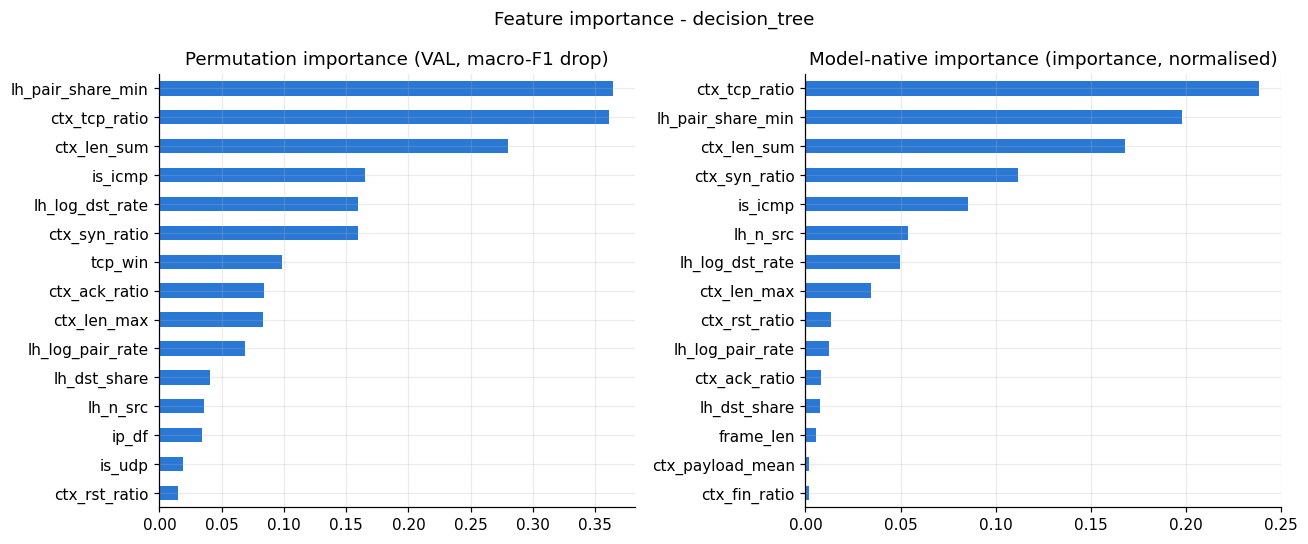

Top features (reported in the bundle): ['lh_pair_share_min', 'ctx_tcp_ratio', 'ctx_len_sum', 'is_icmp', 'lh_log_dst_rate']


In [ ]:
# ---- 1. gap table ----
GAPS = pd.DataFrame({n: {"FIT (sample)": f["meta"]["fit"]["macro_f1"], "VAL": f["meta"]["val"]["macro_f1"],
                         "TEST": TEST_RESULTS[n][TRAIN_LEVEL]["summary"]["macro_f1"]} for n, f in FINAL.items()}).T
GAPS["FIT-VAL"] = GAPS.iloc[:, 0] - GAPS["VAL"]
GAPS["VAL-TEST (capture shift)"] = GAPS["VAL"] - GAPS["TEST"]
print(f"Macro-F1 by partition ({TRAIN_LEVEL} level):"); display(GAPS.round(4))
GAPS.to_csv(os.path.join(DIRS["reports"], "generalization_gaps.csv"))

# ---- 2. error analysis ----
res = TEST_RESULTS[SEL_CAL][TRAIN_LEVEL]; cm, names = res["cm"], res["names"]
TOP_CONFUSIONS = pd.DataFrame([{"true": names[i], "predicted": names[j], "packets": int(cm[i, j]),
                                "share_of_true_class": cm[i, j] / max(cm[i].sum(), 1e-12)}
                               for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0])
if len(TOP_CONFUSIONS):
    TOP_CONFUSIONS = TOP_CONFUSIONS.sort_values("packets", ascending=False).head(12)
    TOP_CONFUSIONS["dos_ddos_pair"] = [dos_ddos_partner(t) == p or dos_ddos_partner(p) == t
                                       for t, p in zip(TOP_CONFUSIONS["true"], TOP_CONFUSIONS["predicted"])]
    print(f"{int(TOP_CONFUSIONS.dos_ddos_pair.head(10).sum())} of the 10 most frequent confusions are DoS<->DDoS of the "
          f"same protocol | overall TEST swap rate {res['summary'].get('dos_ddos_swap_rate', float('nan')):.4f}")
    print("Most frequent confusions (TEST, calibrated selected model):"); display(TOP_CONFUSIONS.round(4))
    TOP_CONFUSIONS.to_csv(os.path.join(DIRS["reports"], "top_confusions.csv"), index=False)
FLOORS = pd.DataFrame([{"level": lv, "test_error": 1 - TEST_RESULTS[SEL_CAL][lv]["summary"]["accuracy"],
                        "label_conflict_floor": CONFLICTS.loc[lv, "test_min_error_floor"],
                        "macro_f1": TEST_RESULTS[SEL_CAL][lv]["summary"]["macro_f1"]} for lv in EVAL_LEVELS]).set_index("level")
FLOORS["error_above_floor"] = FLOORS.test_error - FLOORS.label_conflict_floor
print("Error vs. irreducible label-conflict floor:"); display(FLOORS.round(4))
FLOORS.to_csv(os.path.join(DIRS["reports"], "error_vs_floor.csv"))
minority = res["per_class"].join(SPLIT_TABLE["FIT"].rename("fit_rows")).sort_values("fit_rows")
print("Classes from smallest to largest training support:")
display(minority[["fit_rows", "support", "precision", "recall", "f1", "fpr_ovr"]].round(4))

# ---- 3. permutation importance (VAL) ----
def permutation_drop(name, model, idx, n_repeats=2, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y = y_val[idx]; w = np.ones(len(idx))
    if MODEL_KIND[name] == "sequence":
        Wn = get_windows(META_val["__seqrow__"].to_numpy()[idx]); feats = rt.SEQ_FEATURES
        predict = lambda Z: model.predict_proba(Z)
    else:
        Wn = X_val[idx]; feats = FEATURES
        predict = lambda Z: full_proba(model, Z)
    base = evaluate(y, predict(Wn), w, TRAIN_CLASSES)["summary"]["macro_f1"]
    drops = {}
    for j, feat in enumerate(feats):
        d = []
        for _ in range(n_repeats):
            Zp = Wn.copy(); perm = rng.permutation(len(idx))
            Zp[..., j] = Wn[perm][..., j]
            d.append(base - evaluate(y, predict(Zp), w, TRAIN_CLASSES)["summary"]["macro_f1"])
        drops[feat] = float(np.mean(d))
    return pd.Series(drops, name="macro-F1 drop").sort_values(ascending=False)

def native_importance(model):
    if isinstance(model, Pipeline):
        return pd.Series(np.abs(model.named_steps["clf"].coef_).mean(0), index=FEATURES, name="mean |coef|")
    if HAS_LGBM and isinstance(model, lgb.LGBMClassifier):
        return pd.Series(model.booster_.feature_importance("gain"), index=FEATURES, name="gain")
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=FEATURES, name="importance")
    return None

pidx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(y_val), size=min(PERMUTATION_ROWS, len(y_val)), replace=False))
PERM_IMP = permutation_drop(SELECTED, SEL_MODEL, pidx)
NATIVE_IMP = native_importance(SEL_MODEL) if MODEL_KIND[SELECTED] == "tabular" else None
TOP_FEATURES = PERM_IMP.head(5).index.tolist()
imp = pd.DataFrame({"permutation_macro_f1_drop": PERM_IMP})
if NATIVE_IMP is not None:
    imp[f"native_{NATIVE_IMP.name}"] = NATIVE_IMP / NATIVE_IMP.sum()
imp.to_csv(os.path.join(DIRS["reports"], f"feature_importance_{SELECTED}.csv"))
fig, axes = plt.subplots(1, 2 if NATIVE_IMP is not None else 1, figsize=(12, 5), squeeze=False)
PERM_IMP.head(15)[::-1].plot.barh(ax=axes[0, 0], color=SERIES_COLORS[0])
axes[0, 0].set_title("Permutation importance (VAL, macro-F1 drop)")
if NATIVE_IMP is not None:
    (NATIVE_IMP / NATIVE_IMP.sum()).sort_values().tail(15).plot.barh(ax=axes[0, 1], color=SERIES_COLORS[0])
    axes[0, 1].set_title(f"Model-native importance ({NATIVE_IMP.name}, normalised)")
fig.suptitle(f"Feature importance - {SELECTED}"); fig.tight_layout(); save_fig(fig, f"feature_importance_{SELECTED}")
print("Top features (reported in the bundle):", TOP_FEATURES)

Ablation / leave-capture-out model: decision_tree
Ablation reloaded


macro_f1_variant         macro_f1_binary         accuracy        
partition                                     TEST     VAL            TEST     VAL     TEST     VAL
feature_set                                                                                        
(a) clean features (deployed)               0.8831  0.9803          0.9939  0.9988   0.8998  0.9786
(b) clean + timestamp + packet_no           0.8562  1.0000          1.0000  1.0000   0.8821  1.0000
(c) timestamp + packet_no only              0.8562  1.0000          1.0000  1.0000   0.8821  1.0000

Read: shortcut columns typically score very high on VAL (same capture sessions as FIT) and collapse on TEST (new sessions recorded at other times). That pattern means they identify the capture, not the attack - which is why timestamp and packet_no are excluded from the deployed detector.
Leave-capture-out reloaded


,class,held_out_capture,packets,recall_unseen_capture,recall_in_capture_VAL,most_common_error,subtype_recall_unseen_capture
0,DoS-SYN,TCP_IP-DoS-SYN4,65295,0.9216,0.9935,DDoS-SYN,0.9990
1,DoS-TCP,TCP_IP-DoS-TCP4,64198,0.6355,0.9917,DDoS-TCP,0.9952
2,DoS-UDP,TCP_IP-DoS-UDP4,62459,0.9898,0.9934,DDoS-UDP,0.9982
3,DoS-ICMP,TCP_IP-DoS-ICMP4,64163,0.9646,0.9836,DDoS-ICMP,0.9999
4,DDoS-SYN,TCP_IP-DDoS-SYN4,65519,0.8871,0.8936,DoS-SYN,0.9952
5,DDoS-TCP,TCP_IP-DDoS-TCP4,64330,0.9883,0.9406,DoS-TCP,0.9974
6,DDoS-UDP,TCP_IP-DDoS-UDP8,39197,0.9999,0.9992,DoS-UDP,1.0000
7,DDoS-ICMP,TCP_IP-DDoS-ICMP8,38913,0.9483,0.9777,DoS-ICMP,0.9999


DoS/DDoS before-after reloaded
DoS/DDoS before vs after - decision_tree, identical class-stratified sample (20,000/class), same hyper-parameters; only the feature set changes:


n_features  macro_f1_variant  macro_f1_subtype  macro_f1_family  dos_ddos_swap_rate
partition feature_set                                                                                                                               
TEST      (a) header only                                                34            0.5168            0.9747           0.6971              0.4574
          (b) + 20-packet context (previous design)                      61            0.7961            0.9950           0.8817              0.2103
          (c) + long-horizon attacker-count features (deployed)          69            0.8802            0.9960           0.9696              0.1080
VAL       (a) header only                                                34            0.6807            0.9768           0.7878              0.3329
          (b) + 20-packet context (previous design)                      61            0.8687            0.9967           0.9073              0.1459
          (c) + long-horizon attacker-count features (deployed)          69            0.9810            0.9981           0.9848              0.0203

Per protocol pair on TEST (share of the pair's true packets assigned to the wrong scale):


feature_set,(a) header only,(b) + 20-packet context (previous design),(c) + long-horizon attacker-count features (deployed)
pair,,,
DoS-SYN / DDoS-SYN,0.7040,0.3188,0.0460
DoS-TCP / DDoS-TCP,0.5437,0.2352,0.0062
DoS-UDP / DDoS-UDP,0.4324,0.1291,0.0316
DoS-ICMP / DDoS-ICMP,0.4649,0.2192,0.1262
MQTT-DoS-Connect / MQTT-DDoS-Connect,0.2000,0.0564,0.0004
MQTT-DoS-Publish / MQTT-DDoS-Publish,0.3998,0.3029,0.4376


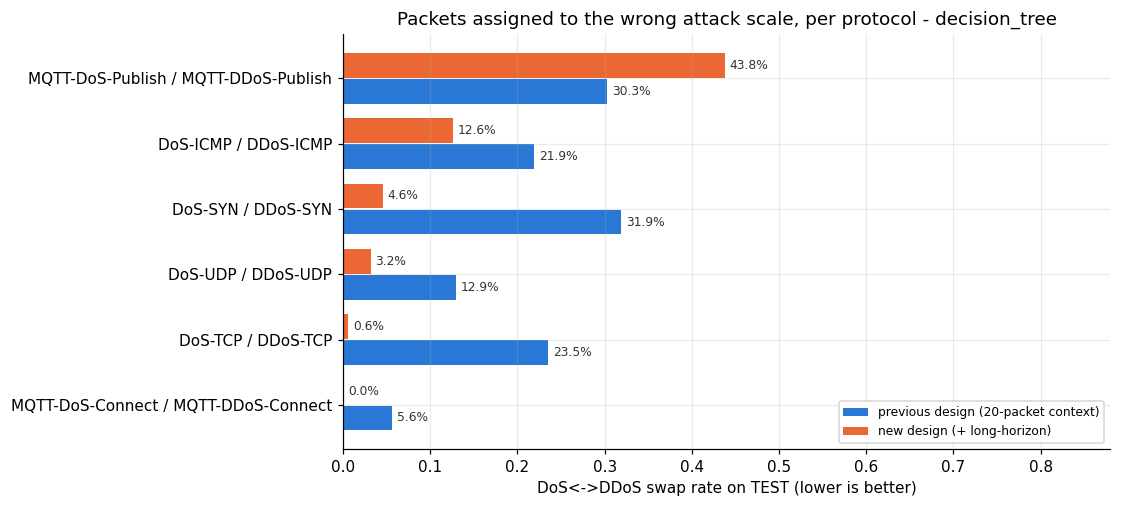

In [ ]:
# ---- 4. shortcut ablation ----
_tab_rank = [n for n in SELECTION.index if MODEL_KIND.get(n) == "tabular" and n != "dummy"]
ABL_MODEL = SELECTED if MODEL_KIND[SELECTED] == "tabular" else _tab_rank[0]
ABL_PARAMS = FINAL[ABL_MODEL]["meta"]["params"]
print(f"Ablation / leave-capture-out model: {ABL_MODEL}"
      + ("" if ABL_MODEL == SELECTED else f" (best tabular model; the selected {SELECTED} is a sequence model)"))
abl_key = FINAL[ABL_MODEL]["meta"]["key"] + f"|{ABLATION_ROWS_PER_CLASS}"
ABLATION, abl_path = None, os.path.join(DIRS["reports"], "shortcut_ablation.csv")
if RUN_SHORTCUT_ABLATION:
    if os.path.exists(abl_path) and pd.read_csv(abl_path)["key"].iloc[0] == abl_key:
        ABLATION = pd.read_csv(abl_path); print("Ablation reloaded")
    else:
        rng = np.random.default_rng(RANDOM_STATE)
        def strat(y, cap):
            return np.sort(np.concatenate([rng.choice(np.flatnonzero(y == c), size=min(cap, int((y == c).sum())), replace=False)
                                           for c in range(K) if (y == c).any()]))
        sel = {r: strat(PARTS[r]["y"], ABLATION_ROWS_PER_CLASS) for r in ("fit", "val", "test")}
        def shortcut_cols(r, idx):
            m = PARTS[r]["meta"].iloc[idx]
            return np.c_[m["__ts__"].to_numpy(np.float64), m["__pkt__"].to_numpy(np.float64) + 1]   # timestamp, packet_no
        featsets = {"(a) clean features (deployed)": lambda r, i: PARTS[r]["X"][i],
                    "(b) clean + timestamp + packet_no": lambda r, i: np.c_[PARTS[r]["X"][i], shortcut_cols(r, i)],
                    "(c) timestamp + packet_no only": lambda r, i: shortcut_cols(r, i)}
        rows = []
        for label, fn in featsets.items():
            Xs = {r: fn(r, sel[r]) for r in sel}; ys = {r: PARTS[r]["y"][sel[r]] for r in sel}
            ws = {r: np.ones(len(sel[r])) for r in sel}
            m, _ = fit_model(ABL_MODEL, ABL_PARAMS, Xs["fit"], ys["fit"], ws["fit"], Xs["val"], ys["val"], ws["val"])
            for r in ("val", "test"):
                ev = evaluate_levels(ys[r], full_proba(m, Xs[r]), ws[r])
                rows.append({"key": abl_key, "feature_set": label, "partition": r.upper(),
                             f"macro_f1_{TRAIN_LEVEL}": ev[TRAIN_LEVEL]["summary"]["macro_f1"],
                             "macro_f1_binary": ev["binary"]["summary"]["macro_f1"] if "binary" in ev else np.nan,
                             "accuracy": ev[TRAIN_LEVEL]["summary"]["accuracy"]})
            print(f"  done: {label}"); del m, Xs; free_memory()
        ABLATION = pd.DataFrame(rows); ABLATION.to_csv(abl_path, index=False)
    display(ABLATION.drop(columns="key").pivot(index="feature_set", columns="partition").round(4))
    print("Read: shortcut columns typically score very high on VAL (same capture sessions as FIT) and collapse on TEST "
          "(new sessions recorded at other times). That pattern means they identify the capture, not the attack - "
          "which is why timestamp and packet_no are excluded from the deployed detector.")

# ---- 5. leave-capture-out ----
LCO, lco_path = None, os.path.join(DIRS["reports"], "leave_capture_out.csv")
if RUN_LEAVE_CAPTURE_OUT:
    def _cap_num(c):
        m = re.search(r"(\d+)$", c); return int(m.group(1)) if m else 0
    caps = META_fit.groupby("__variant__", observed=True)["__capture__"].unique()
    HOLDOUT = {str(v): sorted(map(str, cs), key=_cap_num)[-1] for v, cs in caps.items() if len(cs) >= 2}
    if not HOLDOUT:
        print("No class has more than one training capture - leave-capture-out not possible.")
    elif os.path.exists(lco_path) and pd.read_csv(lco_path)["key"].iloc[0] == abl_key:
        LCO = pd.read_csv(lco_path); print("Leave-capture-out reloaded")
    else:
        hold = set(HOLDOUT.values())
        kf = ~META_fit["__capture__"].astype(str).isin(hold).to_numpy()
        kv = ~META_val["__capture__"].astype(str).isin(hold).to_numpy()
        print(f"Retraining {ABL_MODEL} without captures: {sorted(hold)}")
        mem_guard("leave-capture-out")
        m, _ = fit_model(ABL_MODEL, ABL_PARAMS, X_fit[kf], y_fit[kf], w_fit[kf], X_val[kv], y_val[kv], w_val[kv])
        Xh = np.vstack([X_fit[~kf], X_val[~kv]]); yh = np.concatenate([y_fit[~kf], y_val[~kv]])
        ph = full_proba(m, Xh); pred = ph.argmax(1)
        ref = evaluate(y_val, proba_of(ABL_MODEL, FINAL[ABL_MODEL]["model"], "val"), w_val, TRAIN_CLASSES)["per_class"]
        sub_names, sub_M = EVAL_LEVELS.get("subtype", (None, None))
        rows = []
        for v, capn in HOLDOUT.items():
            c = CLASS_INDEX[v] if TRAIN_LEVEL == "variant" else CLASS_INDEX[_hv.loc[v, TRAIN_LEVEL]]
            msk = yh == c
            wrong = pd.Series(np.ones(int((msk & (pred != c)).sum())), index=np.array(TRAIN_CLASSES)[pred[msk & (pred != c)]])
            row = {"key": abl_key, "class": v, "held_out_capture": capn, "packets": int(msk.sum()),
                   "recall_unseen_capture": float((msk & (pred == c)).sum() / max(msk.sum(), 1)),
                   "recall_in_capture_VAL": float(ref.loc[TRAIN_CLASSES[c], "recall"]),
                   "most_common_error": wrong.groupby(level=0).sum().idxmax() if len(wrong) else ""}
            if sub_M is not None:
                ps = (ph[msk] @ sub_M).argmax(1); row["subtype_recall_unseen_capture"] = float((ps == sub_M.argmax(1)[c]).mean())
            rows.append(row)
        LCO = pd.DataFrame(rows); LCO.to_csv(lco_path, index=False)
        del m, Xh, ph; free_memory()
    if LCO is not None:
        display(LCO.drop(columns="key").round(4))
# ---- 6. DoS <-> DDoS before / after the long-horizon features (real FIT -> VAL / TEST split) ----
SEP, SEP_PAIRS, sep_path = None, None, os.path.join(DIRS["reports"], "dos_ddos_before_after.csv")
sep_pairs_path = os.path.join(DIRS["reports"], "dos_ddos_before_after_pairs.csv")
if RUN_DOS_DDOS_ABLATION and TRAIN_LEVEL == "variant":
    sep_key = FINAL[ABL_MODEL]["meta"]["key"] + f"|{ABLATION_ROWS_PER_CLASS}|dos_ddos"
    if (os.path.exists(sep_path) and os.path.exists(sep_pairs_path)
            and pd.read_csv(sep_path)["key"].iloc[0] == sep_key):
        SEP, SEP_PAIRS = pd.read_csv(sep_path), pd.read_csv(sep_pairs_path); print("DoS/DDoS before-after reloaded")
    else:
        rng6 = np.random.default_rng(RANDOM_STATE + 6)
        sel6 = {r: np.sort(np.concatenate([rng6.choice(np.flatnonzero(PARTS[r]["y"] == c),
                                                       size=min(ABLATION_ROWS_PER_CLASS, int((PARTS[r]["y"] == c).sum())),
                                                       replace=False) for c in range(K) if (PARTS[r]["y"] == c).any()]))
                for r in ("fit", "val", "test")}
        col_of = {c: i for i, c in enumerate(FEATURES)}
        FSETS = {"(a) header only": [c for c in FEATURES if c in rt.BASE_FEATURES],
                 "(b) + 20-packet context (previous design)": [c for c in FEATURES if c not in rt.LONG_FEATURES],
                 "(c) + long-horizon attacker-count features (deployed)": list(FEATURES)}
        rows, prow = [], []
        for label, cols in FSETS.items():
            ci = [col_of[c] for c in cols]
            Xs = {r: PARTS[r]["X"][sel6[r]][:, ci] for r in sel6}
            ys = {r: PARTS[r]["y"][sel6[r]] for r in sel6}; ws = {r: np.ones(len(sel6[r])) for r in sel6}
            m, _ = fit_model(ABL_MODEL, ABL_PARAMS, Xs["fit"], ys["fit"], ws["fit"], Xs["val"], ys["val"], ws["val"])
            for r in ("val", "test"):
                ev = evaluate_levels(ys[r], full_proba(m, Xs[r]), ws[r])
                vt = ev["variant"]
                rows.append({"key": sep_key, "feature_set": label, "n_features": len(cols), "partition": r.upper(),
                             "macro_f1_variant": vt["summary"]["macro_f1"],
                             "macro_f1_subtype": ev["subtype"]["summary"]["macro_f1"] if "subtype" in ev else np.nan,
                             "macro_f1_family": ev["family"]["summary"]["macro_f1"] if "family" in ev else np.nan,
                             "dos_ddos_swap_rate": vt["summary"].get("dos_ddos_swap_rate", np.nan)})
                pt = dos_ddos_table(vt["cm"], vt["names"])
                prow += [{"feature_set": label, "partition": r.upper(), **p} for p in pt.to_dict("records")]
            print(f"  done: {label}"); del m, Xs; free_memory()
        SEP, SEP_PAIRS = pd.DataFrame(rows), pd.DataFrame(prow)
        SEP.to_csv(sep_path, index=False); SEP_PAIRS.to_csv(sep_pairs_path, index=False)
    print(f"DoS/DDoS before vs after - {ABL_MODEL}, identical class-stratified sample "
          f"({ABLATION_ROWS_PER_CLASS:,}/class), same hyper-parameters; only the feature set changes:")
    display(SEP.drop(columns="key").set_index(["partition", "feature_set"]).sort_index().round(4))
    print("Per protocol pair on TEST (share of the pair's true packets assigned to the wrong scale):")
    _fs_order = list(dict.fromkeys(SEP.feature_set))                  # (a), (b), (c)
    _tp = (SEP_PAIRS[SEP_PAIRS.partition == "TEST"]
           .pivot_table(index="pair", columns="feature_set", values="swap_rate", sort=False)[_fs_order])
    display(_tp.round(4))
    # figure: TEST swap rate per pair, previous vs new design
    _prev, _new = _fs_order[1], _fs_order[-1]
    _tp = _tp.sort_values(_new)
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(_tp) + 1.6)); yy = np.arange(len(_tp)); h = 0.38
    for i, (c, lab) in enumerate([(_prev, "previous design (20-packet context)"),
                                  (_new, "new design (+ long-horizon)")]):
        bars = ax.barh(yy + (i - 0.5) * (h + 0.02), _tp[c], height=h, color=SERIES_COLORS[i], label=lab)
        ax.bar_label(bars, labels=[f"{v:.1%}" for v in _tp[c]], padding=3, fontsize=8, color="#333")
    ax.set_yticks(yy, _tp.index); ax.set_xlabel("DoS<->DDoS swap rate on TEST (lower is better)")
    ax.set_xlim(0, max(0.05, float(_tp.to_numpy().max()) * 1.25)); ax.legend(fontsize=8, loc="lower right")
    ax.set_title(f"Packets assigned to the wrong attack scale, per protocol - {ABL_MODEL}")
    save_fig(fig, "dos_ddos_before_after")
elif RUN_DOS_DDOS_ABLATION:
    print(f"DoS/DDoS before-after needs TRAIN_LEVEL='variant' (current: {TRAIN_LEVEL}) - skipped")


In [ ]:
# =====================================================================================================================
# §17b  HISTORY-LENGTH EXPERIMENT -- how far back must the detector look to tell DoS from DDoS?
#
# Paste the CELLS below, in order, as new code cells AFTER the §17 cell that ends with "DoS <-> DDoS before / after".
# They reuse the live notebook state (PARTS, RAW_PARTS, FILES, FINAL, FEATURES, rt, fit_model, full_proba,
# evaluate_levels, dos_ddos_table, ...). Do NOT edit §3: changing a setting there changes CONFIG_HASH and rebuilds
# everything on different packets, which would break "same training and test packets for every run".
# =====================================================================================================================


# ===================================================== CELL 1 =====================================================
# Configuration + the two source-count features at every history length
import json, os, time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

EXP_MODEL = "decision_tree"                      # same model family as the §17 before/after table
EXP_PARAMS = FINAL[EXP_MODEL]["meta"]["params"]  # the tuned hyper-parameters, frozen for every run
EXP_PAIRS = {"TCP": ("DoS-TCP", "DDoS-TCP"),
             "MQTT Publish": ("MQTT-DoS-Publish", "MQTT-DDoS-Publish")}
H_GRID = [20, 64, 256, 1024]                     # look-back lengths in packets (all <= HISTORY_N, so every target has them)
EXP_SEEDS = [0]                                  # seed 0 == the sample used in §17 item 6; use [0, 1, 2, 3, 4] for mean +- sd
assert max(H_GRID) <= HISTORY_N, "H must not exceed HISTORY_N, or some targets would lack the history"
assert EXP_MODEL in FINAL, f"{EXP_MODEL} was not trained in this run"

EXP_COLS = [f"{k}_H{H}" for k in ("all", "dst") for H in H_GRID]
#   all_H<h> : distinct sources over ALL traffic in the last h packets            (counting method 1)
#   dst_H<h> : distinct sources that sent to THIS packet's destination, last h    (counting method 2)


def source_counts_for_block(src, dst, hs):
    """Exact, causal, per-packet counts for one contiguous block. Same engine as rt.long_horizon_features."""
    n = len(src)
    zero = np.zeros(n, np.int64)
    gdst = rt._group_codes(dst)
    out = {}
    for H in hs:
        out[f"all_H{H}"] = rt.window_group_stats(zero, src, H)[1].astype(np.float32)
        out[f"dst_H{H}"] = rt.window_group_stats(gdst, src, H)[1].astype(np.float32)
    return out


def build_count_columns(files, cache_paths_fn, raw_parts, hs):
    """Return {part: {col: float32 array aligned row-for-row with raw_parts[part]}} for the packets already in
    FIT / VAL / TEST. Rows are matched on (file id, packet number), so no packet is added, dropped or re-sampled."""
    cols = [f"{k}_H{H}" for k in ("all", "dst") for H in hs]
    new = {r: {c: np.full(len(raw_parts[r]["pkt"]), np.nan, np.float32) for c in cols} for r in raw_parts}
    for fid, rec in enumerate(files.itertuples(index=False)):
        t = pq.read_table(cache_paths_fn(rec)[0], columns=["__pkt__", "__block__", "src_h", "dst_h"]).to_pandas()
        pkt_all = t["__pkt__"].to_numpy()
        assert np.all(np.diff(pkt_all) > 0), f"packet numbers not increasing in {rec.file}"
        blk = t["__block__"].to_numpy()
        cut = np.flatnonzero(np.diff(blk)) + 1
        starts, ends = np.r_[0, cut], np.r_[cut, len(t)]
        src, dst = t["src_h"].to_numpy(), t["dst_h"].to_numpy()
        full = {c: np.zeros(len(t), np.float32) for c in cols}
        for a, b in zip(starts, ends):                   # one contiguous 20k block at a time, like training
            for c, v in source_counts_for_block(src[a:b], dst[a:b], hs).items():
                full[c][a:b] = v
        for r in raw_parts:
            rows = np.flatnonzero(raw_parts[r]["fid"] == fid)
            if len(rows):
                want = raw_parts[r]["pkt"][rows]
                pos = np.searchsorted(pkt_all, want)
                assert (pkt_all[pos] == want).all(), f"row alignment failed for {rec.file}"
                for c in cols:
                    new[r][c][rows] = full[c][pos]
        del t
    for r in new:
        assert not any(np.isnan(v).any() for v in new[r].values()), f"unfilled rows in {r}"
    return new


exp_feat_path = os.path.join(DIRS["reports"], f"history_exp_counts_{CONFIG_HASH}_{'-'.join(map(str, H_GRID))}.npz")
t0 = time.time()
if os.path.exists(exp_feat_path):
    z = np.load(exp_feat_path)
    NEWF = {r: {c: z[f"{r}|{c}"] for c in EXP_COLS} for r in ("fit", "val", "test")}
    print("Count features reloaded:", os.path.basename(exp_feat_path))
else:
    NEWF = build_count_columns(FILES, cache_paths, RAW_PARTS, H_GRID)
    np.savez_compressed(exp_feat_path, **{f"{r}|{c}": v for r in NEWF for c, v in NEWF[r].items()})
    print(f"Count features built in {time.time() - t0:.0f}s and saved")

# ---- sanity check: our H=1024 columns must equal the notebook's own lh_n_src / lh_fanin_dst, row for row ----
col_of = {c: i for i, c in enumerate(FEATURES)}
for r in ("fit", "val", "test"):
    for nb_col, mine in (("lh_n_src", "all_H1024"), ("lh_fanin_dst", "dst_H1024")):
        if nb_col in col_of and "1024" in mine and 1024 in H_GRID:
            assert np.array_equal(PARTS[r]["X"][:, col_of[nb_col]], NEWF[r][mine]), f"{r}: {mine} != {nb_col}"
print("Alignment check passed: the new columns describe exactly the packets already in FIT / VAL / TEST.")


Count features built in 79s and saved
Alignment check passed: the new columns describe exactly the packets already in FIT / VAL / TEST.


In [ ]:
# ===================================================== CELL 2 =====================================================
# The experiment: one frozen decision tree, one fixed packet sample per seed, one extra feature per run
def draw_sample(seed):
    """Identical to the §17 item 6 draw when seed == 0: class-stratified, ABLATION_ROWS_PER_CLASS per class."""
    rng = np.random.default_rng(RANDOM_STATE + 6 + seed)
    return {r: np.sort(np.concatenate([rng.choice(np.flatnonzero(PARTS[r]["y"] == c),
                                                  size=min(ABLATION_ROWS_PER_CLASS, int((PARTS[r]["y"] == c).sum())),
                                                  replace=False)
                                       for c in range(K) if (PARTS[r]["y"] == c).any()]))
            for r in ("fit", "val", "test")}


def main_error(cm, names, true_name):
    i = names.index(true_name)
    row = cm[i].astype(float).copy(); row[i] = 0
    return names[int(row.argmax())] if row.sum() > 0 else "-"


# the fixed part: header + 20-packet context features, i.e. design (b) of §17 item 6, no long-horizon column at all
BASE_COLS = [c for c in FEATURES if c not in rt.LONG_FEATURES]
base_idx = [col_of[c] for c in BASE_COLS]

RUNS = [("none", 0)]                                         # reference: previous design, nothing added
RUNS += [("all", H) for H in H_GRID] + [("dst", H) for H in H_GRID]
RUNS += [("full", 1024)]                                     # reference: all 8 long-horizon features (deployed)

rows = []
for seed in EXP_SEEDS:
    sel = draw_sample(seed)
    ys = {r: PARTS[r]["y"][sel[r]] for r in sel}
    ws = {r: np.ones(len(sel[r])) for r in sel}
    for counter, H in RUNS:
        if counter == "full":
            Xs = {r: PARTS[r]["X"][sel[r]] for r in sel}
        else:
            Xs = {r: PARTS[r]["X"][sel[r]][:, base_idx] for r in sel}
            if counter != "none":
                Xs = {r: np.c_[Xs[r], NEWF[r][f"{counter}_H{H}"][sel[r]]] for r in sel}
        m, _ = fit_model(EXP_MODEL, EXP_PARAMS, Xs["fit"], ys["fit"], ws["fit"], Xs["val"], ys["val"], ws["val"])
        for part in ("val", "test"):
            vt = evaluate_levels(ys[part], full_proba(m, Xs[part]), ws[part])["variant"]
            pt = dos_ddos_table(vt["cm"], vt["names"]).set_index("pair")
            for label, (dos, ddos) in EXP_PAIRS.items():
                p = pt.loc[f"{dos} / {ddos}"]
                rows.append({"seed": seed, "counter": counter, "H": H, "n_features": Xs[part].shape[1],
                             "partition": part.upper(), "pair": label,
                             "dos_as_ddos": p.dos_as_ddos, "ddos_as_dos": p.ddos_as_dos, "swap_rate": p.swap_rate,
                             "dos_main_error": main_error(vt["cm"], vt["names"], dos),
                             "ddos_main_error": main_error(vt["cm"], vt["names"], ddos),
                             "macro_f1_variant": vt["summary"]["macro_f1"]})
        del m, Xs; free_memory()
    print(f"seed {seed}: {len(RUNS)} runs done")

EXP = pd.DataFrame(rows)
EXP.to_csv(os.path.join(DIRS["reports"], "history_window_experiment.csv"), index=False)

# ---- reproduction check against the §17 item 6 table (only meaningful for seed 0 and ABL_MODEL == decision_tree) ----
if 0 in EXP_SEEDS and EXP_MODEL == ABL_MODEL and SEP_PAIRS is not None:
    for ref_counter, ref_fs in (("none", "(b)"), ("full", "(c)")):
        a = EXP[(EXP.seed == 0) & (EXP.counter == ref_counter) & (EXP.partition == "TEST") & (EXP.pair == "MQTT Publish")]
        b = SEP_PAIRS[(SEP_PAIRS.partition == "TEST") & SEP_PAIRS.feature_set.str.startswith(ref_fs)
                      & (SEP_PAIRS.pair == "MQTT-DoS-Publish / MQTT-DDoS-Publish")]
        print(f"reproduction {ref_fs}: experiment {a.swap_rate.iloc[0]:.4f} vs §17 {b.swap_rate.iloc[0]:.4f}")


seed 0: 10 runs done
reproduction (b): experiment 0.3029 vs §17 0.3029
reproduction (c): experiment 0.4375 vs §17 0.4375



=== TEST: share of packets assigned to the wrong attack scale ===

dos_as_ddos


mean
pair         counter H           
MQTT Publish all     20    0.0104
                     64    0.0058
                     256   0.0073
                     1024  0.0088
             dst     20    0.0126
                     64    0.0064
                     256   0.0076
                     1024  0.0054
             full    1024  0.0001
             none    0     0.0106
TCP          all     20    0.3859
                     64    0.1299
                     256   0.0352
                     1024  0.1158
             dst     20    0.3800
                     64    0.1569
                     256   0.0110
                     1024  0.0170
             full    1024  0.0122
             none    0     0.3859


ddos_as_dos


mean
pair         counter H           
MQTT Publish all     20    0.5953
                     64    0.7181
                     256   0.7719
                     1024  0.7966
             dst     20    0.5960
                     64    0.7970
                     256   0.7538
                     1024  0.7998
             full    1024  0.8750
             none    0     0.5953
TCP          all     20    0.0846
                     64    0.0440
                     256   0.0240
                     1024  0.0312
             dst     20    0.0782
                     64    0.0436
                     256   0.0102
                     1024  0.0026
             full    1024  0.0003
             none    0     0.0846


swap_rate


mean
pair         counter H           
MQTT Publish all     20    0.3029
                     64    0.3619
                     256   0.3896
                     1024  0.4027
             dst     20    0.3043
                     64    0.4017
                     256   0.3808
                     1024  0.4026
             full    1024  0.4376
             none    0     0.3029
TCP          all     20    0.2352
                     64    0.0869
                     256   0.0296
                     1024  0.0735
             dst     20    0.2292
                     64    0.1003
                     256   0.0106
                     1024  0.0098
             full    1024  0.0062
             none    0     0.2352

... (4 outputs left out)


swap_rate


mean
pair         counter H           
MQTT Publish all     20    0.0240
                     64    0.0170
                     256   0.0167
                     1024  0.0214
             dst     20    0.0242
                     64    0.0164
                     256   0.0096
                     1024  0.0127
             full    1024  0.0016
             none    0     0.0239
TCP          all     20    0.2140
                     64    0.1357
                     256   0.1234
                     1024  0.1411
             dst     20    0.2198
                     64    0.1256
                     256   0.0985
                     1024  0.0896
             full    1024  0.0313
             none    0     0.2140


Most common wrong label per true class (TEST, seed 0):


,pair,counter,H,dos_main_error,ddos_main_error
0,TCP,none,0,DDoS-TCP,DoS-TCP
1,MQTT Publish,none,0,MQTT-DDoS-Publish,MQTT-DoS-Publish
2,TCP,all,20,DDoS-TCP,DoS-TCP
3,MQTT Publish,all,20,MQTT-DDoS-Publish,MQTT-DoS-Publish
4,TCP,all,64,DDoS-TCP,DoS-TCP
5,MQTT Publish,all,64,MQTT-DDoS-Publish,MQTT-DoS-Publish
6,TCP,all,256,DDoS-TCP,DoS-TCP
7,MQTT Publish,all,256,MQTT-DDoS-Publish,MQTT-DoS-Publish
8,TCP,all,1024,DDoS-TCP,DoS-TCP
9,MQTT Publish,all,1024,MQTT-DDoS-Publish,MQTT-DoS-Publish


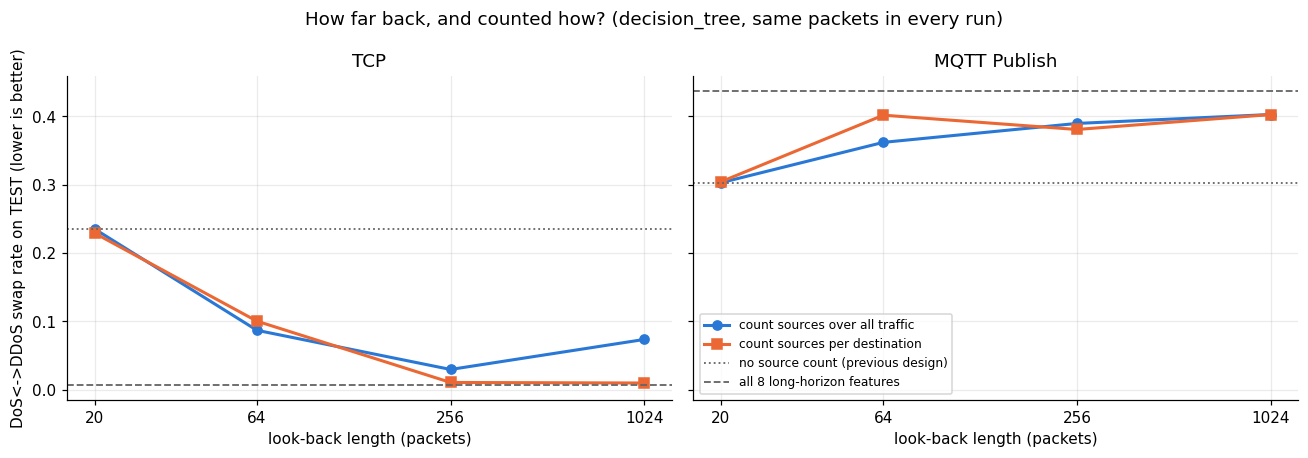

In [ ]:
# ===================================================== CELL 3 =====================================================
# Results tables and figure
def table(partition, value):
    d = EXP[EXP.partition == partition]
    g = d.groupby(["pair", "counter", "H"])[value].agg(["mean", "std"] if len(EXP_SEEDS) > 1 else ["mean"])
    return g.round(4)

for part in ("TEST", "VAL"):
    print(f"\n=== {part}: share of packets assigned to the wrong attack scale ===")
    for v in ("dos_as_ddos", "ddos_as_dos", "swap_rate"):
        print(f"\n{v}"); display(table(part, v))

print("\nMost common wrong label per true class (TEST, seed 0):")
display(EXP[(EXP.partition == "TEST") & (EXP.seed == EXP_SEEDS[0])]
        [["pair", "counter", "H", "dos_main_error", "ddos_main_error"]].reset_index(drop=True))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, label in zip(axes, EXP_PAIRS):
    d = EXP[(EXP.partition == "TEST") & (EXP.pair == label)]
    for i, (ctr, name) in enumerate([("all", "count sources over all traffic"), ("dst", "count sources per destination")]):
        s = d[d.counter == ctr].groupby("H").swap_rate.mean()
        ax.plot(s.index, s.values, marker="os"[i], lw=2, color=SERIES_COLORS[i], label=name)
    for ctr, name, ls in [("none", "no source count (previous design)", ":"), ("full", "all 8 long-horizon features", "--")]:
        ax.axhline(d[d.counter == ctr].swap_rate.mean(), color="#666", ls=ls, lw=1.2, label=name)
    ax.set_xscale("log", base=2); ax.set_xticks(H_GRID, [str(h) for h in H_GRID])
    ax.set_xlabel("look-back length (packets)"); ax.set_title(label)
axes[0].set_ylabel("DoS<->DDoS swap rate on TEST (lower is better)")
axes[1].legend(fontsize=8, loc="best")
fig.suptitle(f"How far back, and counted how? ({EXP_MODEL}, same packets in every run)")
fig.tight_layout(); save_fig(fig, "history_window_experiment")

## 18. Resumable checkpointing and production artifact bundling
Everything needed for deployment is saved together:

* `models/detector_bundle.joblib`: the predictor (tabular pipeline = FIT-fitted preprocessor + classifier, or the
  PyTorch predictor with its normalisation buffers), the calibrator, class list, label hierarchy and collapse matrices,
  feature schema, `CONTEXT_N`, extraction config, selected hyper-parameters, selection table and weights, hardware
  benchmarks, VAL/TEST metrics, data fingerprints, seed, run config and library versions;
* native model files next to it: `detector_model.json` (XGBoost), `.txt` (LightGBM) or `.pt` (PyTorch);
* `iomt_runtime.py` and `iomt_torch_models.py`, the exact feature/decoder/model code the bundle needs at load time
  (`iomt_inference.py`, the live engine, is added by §19);
* `model_card.json` and `feature_schema.json` for human review.

Checkpoints written along the way: per-capture Parquet caches (§5), `tuning/trials.csv` (§10), per-epoch `.pt`
checkpoints (§13), final models + `meta.json` (§10–§13), `bench.json` (§14) and the calibrator (§15).

The project-wide **best-model pointer** (`OUTPUT_DIR/best_model/best_model.json`) is replaced only when a new run has a
higher VAL macro-F1 for its selected model under the **same evaluation protocol** (same data fingerprints, extraction,
split, short and long context, feature version, label level and off-protocol policy). A run with the
new features therefore starts its own lineage; set `FORCE_UPDATE_BEST = True` to promote it over an older-protocol best. Macro-F1 is used here, not the composite score, because latency and
memory depend on the machine and on the other candidates of a run.

In [ ]:
FORCE_UPDATE_BEST = False      # True replaces the global best even if the protocol differs

sel_meta = FINAL[SELECTED]["meta"]
SEL_KIND = MODEL_KIND[SELECTED]
predictor = FINAL[SELECTED]["pipeline"] if SEL_KIND == "tabular" else FINAL[SELECTED]["model"]
BUNDLE = {
    "predictor": predictor, "model_kind": SEL_KIND, "calibrator": CALIBRATOR, "model_name": SELECTED,
    "train_level": TRAIN_LEVEL, "classes": TRAIN_CLASSES,
    "eval_levels": {lv: {"names": n, "matrix": M.tolist()} for lv, (n, M) in EVAL_LEVELS.items()},
    "hierarchy": HIERARCHY.to_dict("records"), "features": FEATURES, "tab_features_all": rt.TAB_FEATURES,
    "seq_features": rt.SEQ_FEATURES, "context_n": CONTEXT_N, "long_context_n": LONG_CONTEXT_N,
    "history_n": HISTORY_N, "long_features": rt.LONG_FEATURES, "feature_version": FEATURE_VERSION,
    "extract_config": EXTRACT_CONFIG,
    "runtime_version": rt.RUNTIME_VERSION, "off_protocol_policy": OFF_PROTOCOL_POLICY,
    "excluded_shortcuts": rt.SHORTCUT_COLUMNS, "top_features": TOP_FEATURES, "params": sel_meta["params"],
    "adaboost_algorithm": ADA_ALGORITHM,
    "selection": {"mode": SELECTION_MODE, "auto_winner": AUTO_SELECTED, "weights": SCORE_WEIGHTS,
                  "latency_metric": LATENCY_METRIC, "memory_metric": MEMORY_METRIC,
                  "table": json_safe(SELECTION.reset_index().to_dict("records"))},
    "benchmarks": BENCH[SELECTED], "hardware": HARDWARE, "val_metrics": sel_meta["val"],
    "test_metrics": {lv: TEST_RESULTS[SEL_CAL][lv]["summary"] for lv in EVAL_LEVELS},
    "test_metrics_uncalibrated": {lv: TEST_RESULTS[SELECTED][lv]["summary"] for lv in EVAL_LEVELS},
    "severity_thresholds": SEVERITY_THRESHOLDS, "run_config": RUN_CONFIG, "config_hash": CONFIG_HASH,
    "versions": VERSIONS, "random_state": RANDOM_STATE,
    "data_manifest": FILES[["file", "variant", "split", "capture", "fingerprint", "size_mb", "packets_total",
                            "packets_extracted"]].to_dict("records"),
    "created_utc": datetime.now(timezone.utc).isoformat()}
BUNDLE_PATH = os.path.join(DIRS["models"], "detector_bundle.joblib")
joblib.dump(BUNDLE, BUNDLE_PATH, compress=3)

mdir_sel, _ = model_artifact(SELECTED)
for old in glob.glob(os.path.join(DIRS["models"], "detector_model.*")):
    os.remove(old)                                                     # no stale files from an earlier selection
for src_name, ext in (("model.json", "json"), ("model.txt", "txt"), ("model.pt", "pt"), ("pipeline.joblib", "pipeline.joblib")):
    if os.path.exists(os.path.join(mdir_sel, src_name)):
        shutil.copy2(os.path.join(mdir_sel, src_name), os.path.join(DIRS["models"], f"detector_model.{ext}"))
for mod in ("iomt_runtime.py", "iomt_torch_models.py"):
    if os.path.exists(os.path.join(RUNTIME_DIR, mod)):
        shutil.copy2(os.path.join(RUNTIME_DIR, mod), os.path.join(DIRS["models"], mod))
card = {k: v for k, v in BUNDLE.items() if k not in ("predictor", "calibrator")}
with open(os.path.join(DIRS["models"], "model_card.json"), "w") as f:
    json.dump(json_safe(card), f, indent=2, default=str)
with open(os.path.join(DIRS["models"], "feature_schema.json"), "w") as f:
    json.dump({"tabular_features_in_order": FEATURES, "all_tabular_features": rt.TAB_FEATURES,
               "sequence_features_per_step": rt.SEQ_FEATURES, "context_n": CONTEXT_N,
               "long_horizon_features": rt.LONG_FEATURES, "long_context_n": LONG_CONTEXT_N, "raw_fields": rt.RAW_COLUMNS,
               "excluded": {"shortcut": rt.SHORTCUT_COLUMNS, "identifiers": sorted(_FORBIDDEN),
                            "constant_on_fit": const_cols, "duplicate_on_fit": dup_cols}}, f, indent=2)

# ---- experiment summary (this run) + project-wide log ----
summary_rows = []
for n in FINAL:
    r = {"run": CONFIG_HASH, "model": n, "selected": n == SELECTED, "selection_mode": SELECTION_MODE,
         **{f"val_{k}": v for k, v in FINAL[n]["meta"]["val"].items() if isinstance(v, (int, float))}}
    for lv in EVAL_LEVELS:
        r[f"test_{lv}_macro_f1"] = TEST_RESULTS[n][lv]["summary"]["macro_f1"]
    r.update({k: SELECTION.loc[n, k] for k in ("composite_score", LATENCY_METRIC, "peak_ram_mb", "disk_mb") if n in SELECTION.index})
    r["params"] = json.dumps(FINAL[n]["meta"]["params"]); summary_rows.append(r)
EXP_SUMMARY = pd.DataFrame(summary_rows)
EXP_SUMMARY.to_csv(os.path.join(RUN_DIR, "experiment_summary.csv"), index=False)
log_path = os.path.join(OUTPUT_DIR, "experiment_log.csv")
log = pd.concat([pd.read_csv(log_path), EXP_SUMMARY]) if os.path.exists(log_path) else EXP_SUMMARY
log.drop_duplicates(["run", "model"], keep="last").to_csv(log_path, index=False)

# ---- global best pointer protected by the protocol hash ----
PROTOCOL = hashlib.sha256(json.dumps({k: RUN_CONFIG[k] for k in ["train_level", "packets_per_capture", "block_packets",
                          "context_n", "long_context_n", "feature_version", "off_protocol_policy", "val_fraction",
                          "gap", "data"]}, sort_keys=True).encode()).hexdigest()[:10]
BEST_DIR = os.path.join(OUTPUT_DIR, "best_model"); os.makedirs(BEST_DIR, exist_ok=True)
pointer_path = os.path.join(BEST_DIR, "best_model.json")
new_score = sel_meta["val"]["macro_f1"]
old = json.load(open(pointer_path)) if os.path.exists(pointer_path) else None
same_run = old is not None and old.get("run") == CONFIG_HASH
if old is None or FORCE_UPDATE_BEST or same_run or (old["protocol"] == PROTOCOL and new_score > old["val_score"]):
    shutil.copy2(BUNDLE_PATH, os.path.join(BEST_DIR, "detector_bundle.joblib"))
    for mod in ("iomt_runtime.py", "iomt_torch_models.py"):
        if os.path.exists(os.path.join(DIRS["models"], mod)):
            shutil.copy2(os.path.join(DIRS["models"], mod), os.path.join(BEST_DIR, mod))
    with open(pointer_path, "w") as f:
        json.dump({"run": CONFIG_HASH, "run_dir": RUN_DIR, "model": SELECTED, "selection_mode": SELECTION_MODE,
                   "protocol": PROTOCOL, "val_metric": "macro_f1", "val_score": new_score,
                   "composite_score": float(SELECTION.loc[SELECTED, "composite_score"]),
                   "updated_utc": datetime.now(timezone.utc).isoformat()}, f, indent=2)
    print(f"Global best -> {SELECTED} (run {CONFIG_HASH}, VAL macro-F1 {new_score:.4f}, {SELECTION_MODE} selection)")
elif old["protocol"] != PROTOCOL:
    print(f"Global best kept: different evaluation protocol ({old['protocol']} vs {PROTOCOL}). This run is saved in "
          f"{RUN_DIR}. Set FORCE_UPDATE_BEST=True to replace it deliberately.")
else:
    print(f"Global best kept: existing VAL macro-F1 {old['val_score']:.4f} >= this run {new_score:.4f}")

print("\nSaved artifacts:")
for root, _, fs in os.walk(RUN_DIR):
    if root[len(RUN_DIR):].count(os.sep) <= 2 and fs:
        print(f"  {os.path.relpath(root, OUTPUT_DIR)}/  ({len(fs)} files)")

Global best kept: different evaluation protocol (9adf7f6222 vs 1373798b05). This run is saved in /content/drive/MyDrive/FYP_IoMT_Detector/runs/run_c53a51becb. Set FORCE_UPDATE_BEST=True to replace it deliberately.

Saved artifacts:
  runs/run_c53a51becb/  (3 files)
  runs/run_c53a51becb/models/  (7 files)
  runs/run_c53a51becb/models/dummy/  (4 files)
  runs/run_c53a51becb/models/logreg/  (4 files)
  runs/run_c53a51becb/models/decision_tree/  (5 files)
  runs/run_c53a51becb/models/random_forest/  (4 files)
  runs/run_c53a51becb/models/adaboost/  (4 files)
  runs/run_c53a51becb/models/xgboost/  (6 files)
  runs/run_c53a51becb/models/lightgbm/  (5 files)
  runs/run_c53a51becb/models/birnn/  (4 files)
  runs/run_c53a51becb/models/transformer/  (4 files)
  runs/run_c53a51becb/tuning/  (1 files)
  runs/run_c53a51becb/reports/  (25 files)
  runs/run_c53a51becb/figures/  (15 files)
  runs/run_c53a51becb/bench/  (3 files)


## 19. Live PCAP packet inference engine
`predict_pcap_stream(pcap_path, detector_bundle, batch_size=1000)` lives in a third module, `iomt_inference.py`,
written by the next cell and copied next to the bundle, so a gateway can use it without this notebook:

```
python iomt_inference.py detector_bundle.joblib capture.pcap --emit attacks   # one incident JSON per line
```

It loads the bundle **from disk** (no retraining) and streams a raw capture:
`read packets → decode (dpkt) → causal features with a max(20, 1,024)-packet carry-over between batches (StreamFeaturizer) →
model → calibrator → probabilities at 4 levels → incident JSON`.

* The feature code is the bundle's own `iomt_runtime`. The next cell **asserts** on a real cached block that streaming
  in 1,000-packet batches reproduces the training block features exactly, long-horizon columns included.
* Every packet is classified, including background traffic in an attack capture. The off-protocol filter was a
  *training-label* rule, not a deployment rule.
* The first `max(CONTEXT_N, LONG_CONTEXT_N)` packets of a stream have a partial history and are marked
  `context_warmup: true`.
* `emit="attacks"` (default) yields only packets predicted as Attack; `"all"` yields every packet.
* `inference_latency_ms` is the model + calibration time per packet within its batch. End-to-end throughput, including
  parsing, is reported in the demo table.
* `initial_severity`: `none` for Benign; otherwise `high` / `medium` / `low` by calibrated confidence
  (`SEVERITY_THRESHOLDS`). The Controller combines this with device criticality.

In [ ]:
%%writefile iomt_inference.py
"""Live PCAP inference for the IoMT detector bundle (deployment entry point).

    python iomt_inference.py <detector_bundle.joblib> <capture.pcap> [--emit all|attacks] [--max-packets N]

prints one incident JSON object per line. Import use: `predict_pcap_stream(pcap_path, bundle_or_path, batch_size=1000)`.
"""
import argparse
import json
import os
import sys
import time
from datetime import datetime, timezone

import joblib
import numpy as np

_HERE = os.path.dirname(os.path.abspath(__file__))
if _HERE not in sys.path:
    sys.path.insert(0, _HERE)
import iomt_runtime as rt  # noqa: E402

DEFAULT_SEVERITY = {"high": 0.90, "medium": 0.60}


def load_detector(path):
    """Load a bundle saved by the training notebook; its own runtime modules sit next to it."""
    d = os.path.dirname(os.path.abspath(path))
    if d not in sys.path:
        sys.path.insert(0, d)
    b = joblib.load(path)
    try:
        import sklearn
        if b["versions"]["scikit-learn"] != sklearn.__version__:
            print(f"Note: bundle saved with scikit-learn {b['versions']['scikit-learn']}, running {sklearn.__version__}",
                  file=sys.stderr)
    except ImportError:
        pass
    if b.get("runtime_version") != rt.RUNTIME_VERSION:
        print(f"Note: bundle built with iomt_runtime {b.get('runtime_version')}, running {rt.RUNTIME_VERSION}",
              file=sys.stderr)
    if b["model_kind"] == "sequence":
        b["predictor"].to("cpu")
    return b


def _severity(is_attack, conf, thr):
    if not is_attack:
        return "none"
    return "high" if conf >= thr["high"] else "medium" if conf >= thr["medium"] else "low"


def predict_pcap_stream(pcap_path, detector_bundle, batch_size=1000, emit="attacks", max_packets=None,
                        min_confidence=0.0, use_calibrated=True):
    """Stream a raw PCAP/PCAPNG and yield structured incident dicts for SOC / Controller routing.
    emit: "attacks" (packets predicted as Attack) or "all" (every packet)."""
    det = load_detector(detector_bundle) if isinstance(detector_bundle, str) else detector_bundle
    src = rt.PcapSource(pcap_path)
    fz = rt.StreamFeaturizer(det["context_n"], det.get("long_context_n", rt.DEFAULT_LONG_CONTEXT_N))
    levels = {lv: (d["names"], np.asarray(d["matrix"])) for lv, d in det["eval_levels"].items()}
    classes = det["classes"]
    version, thr = f"run_{det['config_hash']}", det.get("severity_thresholds", DEFAULT_SEVERITY)

    def score(batch, first_index):
        raw = rt.decode_records(batch, src.linktype)
        feats, wins, warm = fz.transform(raw)
        t0 = time.perf_counter()
        P = det["predictor"].predict_proba(wins if det["model_kind"] == "sequence" else feats)
        if use_calibrated and det.get("calibrator") is not None:
            P = det["calibrator"].predict_proba(P)
        per_pkt_ms = (time.perf_counter() - t0) * 1e3 / len(batch)
        coarse = {lv: (names, (P @ M).argmax(1)) for lv, (names, M) in levels.items()}
        top = np.argsort(-P, axis=1)[:, :3]
        for j in range(len(batch)):
            lab = {lv: names[idx[j]] for lv, (names, idx) in coarse.items()}
            binary = lab.get("binary", "Benign" if classes[top[j, 0]] == "Benign" else "Attack")
            is_attack, conf = binary == "Attack", float(P[j, top[j, 0]])
            if (emit == "attacks" and not is_attack) or conf < min_confidence:
                continue
            s_ip, d_ip = rt.packet_addresses(batch[j][2], src.linktype)
            yield {"timestamp": datetime.fromtimestamp(batch[j][0], timezone.utc)
                                .isoformat(timespec="milliseconds").replace("+00:00", "Z"),
                   "src_ip": s_ip, "dst_ip": d_ip,
                   "attack_variant": lab.get("variant"), "attack_subtype": lab.get("subtype"),
                   "attack_family": lab.get("family"), "attack_binary": binary,
                   "confidence": round(conf, 4),
                   "top3_predictions": [[classes[k], round(float(P[j, k]), 4)] for k in top[j]],
                   "initial_severity": _severity(is_attack, conf, thr),
                   "inference_latency_ms": round(per_pkt_ms, 4), "model_version": version,
                   "packet_index": first_index + j, "context_warmup": bool(warm[j])}

    buf, n = [], 0
    for rec in src.iter_all():
        buf.append(rec)
        n += 1
        if len(buf) == batch_size:
            yield from score(buf, n - len(buf))
            buf = []
        if max_packets and n >= max_packets:
            break
    if buf:
        yield from score(buf, n - len(buf))


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description="Stream a PCAP through the IoMT detector and print incident JSON lines")
    ap.add_argument("bundle")
    ap.add_argument("pcap")
    ap.add_argument("--emit", choices=["attacks", "all"], default="attacks")
    ap.add_argument("--max-packets", type=int, default=None)
    ap.add_argument("--batch-size", type=int, default=1000)
    a = ap.parse_args()
    for inc in predict_pcap_stream(a.pcap, a.bundle, a.batch_size, a.emit, a.max_packets):
        print(json.dumps(inc))

Writing iomt_inference.py


In [ ]:
import iomt_inference as inf
importlib.reload(inf)
_ptr = json.load(open(pointer_path)) if os.path.exists(pointer_path) else {}
for d in [DIRS["models"]] + ([BEST_DIR] if _ptr.get("run") == CONFIG_HASH else []):
    shutil.copy2(os.path.join(RUNTIME_DIR, "iomt_inference.py"), os.path.join(d, "iomt_inference.py"))
load_detector, predict_pcap_stream = inf.load_detector, inf.predict_pcap_stream

# ---------------- check on real traffic: streamed batches == training block features ----------------
_rec = FILES[FILES.split == "test"].iloc[0]
_rg = pq.ParquetFile(cache_paths(_rec)[0]).read_row_group(0).to_pandas()
_rawb = _rg[_rg["__block__"] == _rg["__block__"].iloc[0]].reset_index(drop=True)[rt.RAW_COLUMNS]
_Fb = rt.build_features(_rawb, CONTEXT_N, LONG_CONTEXT_N)
_fz = rt.StreamFeaturizer(CONTEXT_N, LONG_CONTEXT_N)
_Fs = pd.concat([_fz.transform(_rawb.iloc[a:a + 1000])[0] for a in range(0, len(_rawb), 1000)], ignore_index=True)
assert np.allclose(_Fs.to_numpy(), _Fb.to_numpy(), equal_nan=True), "streamed features differ from training features"
print(f"Streaming check passed on {_rec.file} block 0 ({len(_rawb):,} packets, {_Fb.shape[1]} features incl. "
      f"{len(rt.LONG_FEATURES)} long-horizon)")
del _rg, _rawb, _Fb, _Fs

# ---------------- demo: load from disk, stream one TEST capture per family ----------------
DETECTOR = load_detector(BUNDLE_PATH)
demo_files = (FILES[FILES.split == "test"].merge(HIERARCHY, on="variant").groupby("family", sort=False).head(1))
# add the DoS partner of every DDoS demo capture (same protocol) so the demo shows both scales
_pairs = FILES[(FILES.split == "test") & FILES.variant.isin([dos_ddos_partner(v) or "" for v in demo_files.variant]
                                                             + [v for v, p in DOS_DDOS_PAIRS if p in set(demo_files.variant)])]
demo_files = pd.concat([demo_files, _pairs.merge(HIERARCHY, on="variant")]).drop_duplicates("file")
demo_rows, examples = [], {}
for rec in demo_files.itertuples(index=False):
    t0 = time.perf_counter()
    incs = list(predict_pcap_stream(rec.path, DETECTOR, batch_size=1000, emit="all", max_packets=DEMO_PACKETS_PER_FILE))
    secs = time.perf_counter() - t0
    fam = pd.Series([i["attack_family"] for i in incs]).value_counts(normalize=True)
    demo_rows.append({"capture": rec.file, "true_variant": rec.variant, "true_family": rec.family, "packets": len(incs),
                      "share_pred_attack": float(np.mean([i["attack_binary"] == "Attack" for i in incs])),
                      "share_pred_true_family": float(fam.get(rec.family, 0.0)),
                      "share_pred_true_variant": float(np.mean([i["attack_variant"] == rec.variant for i in incs])),
                      "end_to_end_pkts_per_s": len(incs) / secs,
                      "model_ms_per_pkt_p50": float(np.median([i["inference_latency_ms"] for i in incs]))})
    att = [i for i in incs if i["attack_binary"] == "Attack" and not i["context_warmup"]]
    if att and rec.family != "Benign":
        examples[rec.variant] = att[len(att) // 2]
DEMO = pd.DataFrame(demo_rows)
print(f"Live engine on the first {DEMO_PACKETS_PER_FILE:,} packets of one TEST capture per family "
      "(every packet, including background traffic, is classified):")
display(DEMO.round(4))
for v, inc in list(examples.items())[:2]:
    print(f"\nExample incident from {v} capture:")
    print(json.dumps(inc, indent=2))
print(f"\nStandalone use: python {os.path.join(DIRS['models'], 'iomt_inference.py')} {BUNDLE_PATH} <capture.pcap>")

Streaming check passed on Benign_test.pcap block 0 (20,000 packets, 74 features incl. 8 long-horizon)
Live engine on the first 5,000 packets of one TEST capture per family (every packet, including background traffic, is classified):


,capture,true_variant,true_family,packets,share_pred_attack,share_pred_true_family,share_pred_true_variant,end_to_end_pkts_per_s,model_ms_per_pkt_p50
0,Benign_test.pcap,Benign,Benign,5000,0.0002,0.9998,0.9998,10915.7896,0.0050
1,MQTT-DDoS-Connect_Flood_test.pcap,MQTT-DDoS-Connect,MQTT-Flood,5000,1.0000,0.9966,0.9896,11677.8697,0.0050
2,TCP_IP-DDoS-ICMP1_test.pcap,DDoS-ICMP,DDoS,5000,0.9982,0.9868,0.9856,6221.6716,0.0050
3,TCP_IP-DoS-ICMP_test.pcap,DoS-ICMP,DoS,5000,1.0000,0.9794,0.9794,4987.0121,0.0054
4,MQTT-DoS-Connect_Flood_test.pcap,MQTT-DoS-Connect,MQTT-Flood,5000,0.9998,0.9960,0.9958,6840.6424,0.0052
5,TCP_IP-DDoS-ICMP2_test.pcap,DDoS-ICMP,DDoS,5000,1.0000,0.9810,0.9810,10817.0016,0.0049



Example incident from MQTT-DDoS-Connect capture:
{
  "timestamp": "2023-08-29T20:27:55.853Z",
  "src_ip": "192.168.137.250",
  "dst_ip": "192.168.137.156",
  "attack_variant": "MQTT-DDoS-Connect",
  "attack_subtype": "MQTT-Connect",
  "attack_family": "MQTT-Flood",
  "attack_binary": "Attack",
  "confidence": 0.97,
  "top3_predictions": [
    [
      "MQTT-DDoS-Connect",
      0.97
    ],
    [
      "MQTT-DDoS-Publish",
      0.03
    ],
    [
      "DoS-UDP",
      0.0
    ]
  ],
  "initial_severity": "high",
  "inference_latency_ms": 0.0049,
  "model_version": "run_c53a51becb",
  "packet_index": 3012,
  "context_warmup": false
}

Example incident from DDoS-ICMP capture:
{
  "timestamp": "2023-09-05T19:49:38.356Z",
  "src_ip": "192.168.137.48",
  "dst_ip": "192.168.137.250",
  "attack_variant": "DDoS-ICMP",
  "attack_subtype": "ICMP",
  "attack_family": "DDoS",
  "attack_binary": "Attack",
  "confidence": 1.0,
  "top3_predictions": [
    [
      "DDoS-ICMP",
      1.0
    ],
    [
 

## 20. Final experiment summary — all statistics, and how to change the selection
The table below collects **every statistic for every model** in one place: VAL quality, latency, memory, disk,
composite score and rank, and TEST metrics at all four levels.

**Changing the selected model by hand.** Set `MANUAL_SELECTION = "<model>"` in §3 (e.g. `"lightgbm"`), then run §3
and §14 → §20 again (or simply *Run all*: every model, trial and benchmark is reloaded from disk, nothing is
retrained). Calibration, the TEST headline, the bundle and the best-model pointer then follow your choice, and the bundle
records `selection.mode = "manual"`.

> Make the manual choice from the **VAL and cost columns**. The TEST columns are there for reporting. Picking the model
> with the best TEST score turns TEST into a selection set and makes the reported TEST numbers optimistic.

Interpretation guide for the report:
* Quote the selected model's TEST metrics at each level together with the VAL→TEST gap, the label-conflict floor, the
  shortcut ablation and the leave-capture-out result. Accuracy alone is not a result here: use macro-F1, balanced
  accuracy, worst-class recall and the benign false-alarm rate.
* **DoS vs DDoS.** Same-protocol DoS and DDoS send identical packets and differ only in the number of attacking
  hosts. §5b shows on the training captures that this number is invisible to the old 20-packet, whole-stream context
  (attackers send in bursts longer than the window) and visible to victim-centric counts over 1,024 packets. Quote the
  §17 item 6 table (swap rate before → after, per protocol) and the per-pair TEST table of §16. Two honest caveats:
  (i) a decision is still made per packet, so the first packets of a new attack, or an attacker that pauses, can be
  assigned the wrong scale; (ii) the attacker count depends on how many hosts the lab used, so a deployment with a
  different botnet size should be re-validated.
* Where single packets are identical across classes, the 13-class score is bounded by the conflict floor, while the
  7-class subtype and 4-class family scores show what the detector can separate.
* These are **in-domain CICIoMT2024** results. Latency and memory were measured on this runtime; measure again on the real
  edge gateway before quoting them as deployment numbers.

In [ ]:
rows = []
for n in SELECTION.index:
    r = SELECTION.loc[n].to_dict()
    for lv in EVAL_LEVELS:
        s = TEST_RESULTS[n][lv]["summary"]
        r[f"test_{lv}_macro_f1"] = s["macro_f1"]
    s = TEST_RESULTS[n][TRAIN_LEVEL]["summary"]
    r.update(test_accuracy=s["accuracy"], test_balanced_accuracy=s["balanced_accuracy"],
             test_min_class_recall=s["min_class_recall"], test_worst_class=s["worst_class"],
             test_benign_false_alarm_rate=s.get("benign_false_alarm_rate"), test_log_loss=s["log_loss"],
             test_brier=s["brier"], test_ece=s["ece"], test_dos_ddos_swap_rate=s.get("dos_ddos_swap_rate", np.nan))
    r["selected"] = "<< SELECTED" if n == SELECTED else ("composite winner" if n == AUTO_SELECTED else "")
    rows.append({"model": n, **r})
FINAL_TABLE = pd.DataFrame(rows).set_index("model")
FINAL_TABLE.to_csv(os.path.join(RUN_DIR, "final_model_comparison.csv"))

GROUPS = {
    "Selection (VAL, variant level)": ["selected", "kind", "rank", "composite_score", "f1_term", "latency_term",
                                       "memory_term", "val_macro_f1", "val_min_class_recall", "val_worst_class",
                                       "val_dos_ddos_swap_rate",
                                       "val_benign_false_alarm_rate", "val_ece_raw", "fit_macro_f1"],
    "Latency & throughput (CPU, subprocess)": ["single_p50_ms", "single_p95_ms", "batch1k_p50_ms", "batch1k_p95_ms",
                                               "throughput_pps"],
    "Resources": ["peak_ram_mb", "peak_train_ram_mb", "peak_train_vram_mb", "peak_infer_vram_mb", "disk_mb", "fit_seconds"],
    "TEST (reporting only - do not select on these)": ["test_accuracy", "test_balanced_accuracy"] +
        [f"test_{lv}_macro_f1" for lv in EVAL_LEVELS] + ["test_min_class_recall", "test_worst_class",
        "test_benign_false_alarm_rate", "test_dos_ddos_swap_rate", "test_log_loss", "test_brier", "test_ece"],
}
for title, cs in GROUPS.items():
    print(f"\n### {title}")
    display(FINAL_TABLE[[c for c in cs if c in FINAL_TABLE]].round(4))
print(f"\nFull table saved: {os.path.join(RUN_DIR, 'final_model_comparison.csv')}")
print(f"To change the selection: set MANUAL_SELECTION in §3 to one of {[n for n in FINAL if n != 'dummy']} "
      "and re-run §3 and §14 onward.")

sel_test = TEST_RESULTS[SEL_CAL]
print("\n" + "=" * 100)
print(f"RUN {CONFIG_HASH} | {len(FILES)} captures | {len(y_fit) + len(y_val):,} training-side packets "
      f"(FIT {len(y_fit):,} / VAL {len(y_val):,}) | {len(y_test):,} TEST packets | {len(FEATURES)} tabular features, "
      f"window {CONTEXT_N}, long horizon {LONG_CONTEXT_N}")
print(f"Selected: {SELECTED} ({SELECTION_MODE}; composite winner {AUTO_SELECTED}) | score "
      f"{SELECTION.loc[SELECTED, 'composite_score']:.4f} | weights {SCORE_WEIGHTS}")
print(f"VAL {TRAIN_LEVEL}: macro-F1 {sel_meta['val']['macro_f1']:.4f} | worst-class recall "
      f"{sel_meta['val']['min_class_recall']:.4f} | benign FAR {sel_meta['val'].get('benign_false_alarm_rate', float('nan')):.4f}")
for lv in EVAL_LEVELS:
    s = sel_test[lv]["summary"]
    print(f"TEST {lv:<8}: macro-F1 {s['macro_f1']:.4f} | weighted-F1 {s['weighted_f1']:.4f} | acc {s['accuracy']:.4f} | "
          f"worst {s['worst_class']} ({s['min_class_recall']:.3f}) | log-loss {s['log_loss']:.4f} | "
          f"Brier {s['brier']:.4f} | ECE {s['ece']:.4f} | conflict floor {CONFLICTS.loc[lv, 'test_min_error_floor']:.4f}")
s = sel_test[TRAIN_LEVEL]["summary"]
print(f"Benign false-alarm rate {s.get('benign_false_alarm_rate', float('nan')):.4f} | attacks missed as benign "
      f"{s.get('attack_missed_as_benign_rate', float('nan')):.4f} | ECE raw "
      f"{TEST_RESULTS[SELECTED][TRAIN_LEVEL]['summary']['ece']:.4f} -> calibrated {s['ece']:.4f}")
b = BENCH[SELECTED]
print(f"Latency (CPU, this runtime): single packet p50 {b['single_p50_ms']:.2f} ms / p95 {b['single_p95_ms']:.2f} ms | "
      f"1k batch p95 {b['batch1k_p95_ms']:.1f} ms | {b['throughput_pps']:,.0f} pkt/s | RAM {b['peak_ram_mb']:,.0f} MB | "
      f"disk {sel_meta['disk_mb']:.2f} MB")
print(f"DoS<->DDoS swap rate (TEST, {SEL_CAL}): {s.get('dos_ddos_swap_rate', float('nan')):.4f}")
if SEP is not None:
    _t = SEP[SEP.partition == "TEST"].set_index("feature_set")
    print("DoS/DDoS before -> after (TEST, " + ABL_MODEL + "):",
          {k: {"variant_macro_f1": round(r.macro_f1_variant, 4), "swap_rate": round(r.dos_ddos_swap_rate, 4)}
           for k, r in _t.iterrows()})
if DIAG_SEPARABILITY is not None:
    print("Diagnosis (training captures, unseen sessions) - mean DoS-vs-DDoS balanced accuracy:",
          DIAG_SEPARABILITY.groupby("feature_set", sort=False).balanced_accuracy.mean().round(3).to_dict())
if ABLATION is not None:
    t = ABLATION[ABLATION.partition == "TEST"].set_index("feature_set")[f"macro_f1_{TRAIN_LEVEL}"]
    print("Shortcut ablation (TEST macro-F1):", {k: round(v, 4) for k, v in t.items()})
if LCO is not None:
    print("Leave-capture-out recall (unseen session vs in-capture VAL):",
          {r["class"]: (round(r["recall_unseen_capture"], 3), round(r["recall_in_capture_VAL"], 3)) for _, r in LCO.iterrows()})
print(f"Bundle: {BUNDLE_PATH}")
print(mem_status("end"))
print("=" * 100)


### Selection (VAL, variant level)


,selected,kind,rank,composite_score,f1_term,latency_term,memory_term,val_macro_f1,val_min_class_recall,val_worst_class,val_dos_ddos_swap_rate,val_benign_false_alarm_rate,val_ece_raw,fit_macro_f1
model,,,,,,,,,,,,,,
decision_tree,<< SELECTED,tabular,1.0,0.9798,0.5884,0.1966,0.1949,0.9806,0.8936,DDoS-SYN,0.0227,0.0016,0.0128,0.9874
logreg,,tabular,2.0,0.9586,0.5821,0.1848,0.1917,0.9701,0.8859,DDoS-SYN,0.0379,0.0010,0.0101,0.9782
adaboost,,tabular,3.0,0.9349,0.5791,0.1620,0.1938,0.9652,0.8839,DDoS-SYN,0.0359,0.0022,0.8839,0.9710
xgboost,,tabular,4.0,0.8553,0.5898,0.1026,0.1629,0.9831,0.8983,DDoS-SYN,0.0209,0.0001,0.0106,0.9910
lightgbm,,tabular,5.0,0.8394,0.5898,0.0663,0.1833,0.9830,0.8982,DDoS-SYN,0.0210,0.0000,0.0107,0.9915
birnn,,sequence,6.0,0.7377,0.5893,0.0419,0.1065,0.9821,0.8949,DDoS-SYN,0.0224,0.0000,0.0114,0.9863
random_forest,,tabular,7.0,0.7103,0.5895,0.1208,0.0000,0.9825,0.8945,DDoS-SYN,0.0214,0.0007,0.0072,0.9905
transformer,,sequence,8.0,0.6813,0.5894,0.0000,0.0919,0.9823,0.8941,DDoS-SYN,0.0222,0.0000,0.0106,0.9865
dummy,,tabular,NaN,NaN,NaN,NaN,NaN,0.0033,0.0000,Benign,0.0234,1.0000,0.0549,0.0110



### Latency & throughput (CPU, subprocess)


,single_p50_ms,single_p95_ms,batch1k_p50_ms,batch1k_p95_ms,throughput_pps
model,,,,,
decision_tree,2.8747,3.6268,3.3243,3.5928,812165.8547
logreg,4.6262,5.6214,6.0259,15.9943,301698.8876
adaboost,27.9846,37.2856,38.1856,39.9130,71853.6133
xgboost,4.3564,6.8013,81.3796,102.2531,8271.4272
lightgbm,3.8312,4.6899,129.5099,140.3039,8341.0283
birnn,6.0285,24.5032,134.0630,165.9882,5975.3823
random_forest,57.0154,59.7428,78.1031,83.1399,52568.3998
transformer,1.5939,1.8318,178.5608,209.9451,4355.9324
dummy,2.6543,2.9523,3.1752,3.3855,866510.8045



### Resources


,peak_ram_mb,peak_train_ram_mb,peak_train_vram_mb,peak_infer_vram_mb,disk_mb,fit_seconds
model,,,,,,
decision_tree,17.0000,4987.1,0.0,0.0000,0.106,77.8
logreg,27.4609,7533.9,0.0,0.0000,0.011,615.0
adaboost,20.6680,5732.3,0.0,0.0000,0.074,1549.8
xgboost,123.3945,6208.7,968.0,0.0000,7.968,152.6
lightgbm,55.5938,6114.2,0.0,0.0000,7.739,625.5
birnn,310.4844,7552.7,310.0,250.8701,0.463,2721.2
random_forest,664.4688,5452.6,0.0,0.0000,59.146,1001.6
transformer,359.1797,7795.3,584.0,264.2471,1.073,1865.9
dummy,14.8477,4943.5,0.0,0.0000,0.002,0.4



### TEST (reporting only - do not select on these)


,test_accuracy,test_balanced_accuracy,test_variant_macro_f1,test_subtype_macro_f1,test_family_macro_f1,test_binary_macro_f1,test_min_class_recall,test_worst_class,test_benign_false_alarm_rate,test_dos_ddos_swap_rate,test_log_loss,test_brier,test_ece
model,,,,,,,,,,,,,
decision_tree,0.9084,0.8994,0.8835,0.9947,0.9694,0.9870,0.1157,MQTT-DDoS-Publish,0.0017,0.0919,0.9172,0.1619,0.0722
logreg,0.9153,0.9122,0.8908,0.9945,0.9743,0.9865,0.1200,MQTT-DDoS-Publish,0.0027,0.0847,0.5611,0.1632,0.0717
adaboost,0.9146,0.9089,0.8886,0.8400,0.5291,0.4928,0.1021,MQTT-DDoS-Publish,0.0023,0.0849,2.5544,0.9215,0.8368
xgboost,0.9069,0.8977,0.8838,0.9963,0.9685,0.9894,0.1307,MQTT-DDoS-Publish,0.0002,0.0944,0.6506,0.1600,0.0655
lightgbm,0.9053,0.8958,0.8812,0.9960,0.9674,0.9885,0.1185,MQTT-DDoS-Publish,0.0001,0.0960,0.6127,0.1640,0.0682
birnn,0.9089,0.9028,0.8856,0.9958,0.9700,0.9882,0.1234,MQTT-DDoS-Publish,0.0002,0.0921,0.7329,0.1627,0.0653
random_forest,0.9054,0.8966,0.8810,0.9955,0.9675,0.9875,0.1128,MQTT-DDoS-Publish,0.0004,0.0955,1.5890,0.1611,0.0606
transformer,0.9032,0.8971,0.8799,0.9954,0.9657,0.9875,0.1183,MQTT-DDoS-Publish,0.0001,0.0978,0.8086,0.1674,0.0660
dummy,0.0645,0.0769,0.0093,0.0256,0.0922,0.4928,0.0000,Benign,1.0000,0.0652,2.5650,0.9231,0.0126



Full table saved: /content/drive/MyDrive/FYP_IoMT_Detector/runs/run_c53a51becb/final_model_comparison.csv
To change the selection: set MANUAL_SELECTION in §3 to one of ['logreg', 'decision_tree', 'random_forest', 'adaboost', 'xgboost', 'lightgbm', 'birnn', 'transformer'] and re-run §3 and §14 onward.

RUN c53a51becb | 60 captures | 3,250,002 training-side packets (FIT 2,598,912 / VAL 651,090) | 1,299,644 TEST packets | 69 tabular features, window 20, long horizon 1024
Selected: decision_tree (composite; composite winner decision_tree) | score 0.9798 | weights {'macro_f1': 0.6, 'latency': 0.2, 'memory': 0.2}
VAL variant: macro-F1 0.9806 | worst-class recall 0.8936 | benign FAR 0.0016
TEST variant : macro-F1 0.8584 | weighted-F1 0.8645 | acc 0.8836 | worst MQTT-DDoS-Publish (0.116) | log-loss 0.7046 | Brier 0.1710 | ECE 0.0812 | conflict floor 0.0000
TEST subtype : macro-F1 0.9947 | weighted-F1 0.9978 | acc 0.9977 | worst SYN (0.995) | log-loss 0.0206 | Brier 0.0046 | ECE 0.0025 | confl